# Garbage Classification — Transfer Learning with RegNetY-1.6GF (PyTorch)

**Task.** 10-class image classification of household waste
(*battery, biological, cardboard, clothes, glass, metal, paper, plastic, shoes, trash*)
on the [Garbage Classification v2](https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2) dataset.

**Approach.** ImageNet-pretrained **RegNetY-1.6GF** used first as a frozen feature extractor with a new
linear classification head (*linear probing*), then **fine-tuned** in a second stage (four controlled experiments), followed by a statistical comparison of the variants and an in-depth evaluation of the selected model. Every run is trained **once**: weights, history, logits and TensorBoard logs are stored, and all comparisons / evaluations are computed from those artifacts. The emphasis is on a **leakage-free evaluation protocol**:
the data is audited, near-duplicates are grouped by perceptual hash, and the train/val/test split is
stratified **and** group-disjoint, so test metrics reflect generalisation to unseen images rather than memorised duplicates.

| # | Section | Purpose |
|---|---------|---------|
| 1 | Setup & reproducibility | Imports, global seeding |
| 2 | Configuration | Image size, normalisation, paths, device |
| 3 | Data audit | Corrupt files, formats, image geometry, class balance |
| 4 | Duplicate & leakage analysis | MD5 / pHash grouping, label-noise removal |
| 5 | Group-aware stratified split | Train / val / test without duplicate leakage |
| 6 | Class imbalance | Inverse-frequency class weights |
| 7 | Preprocessing & augmentation | Train vs. eval transforms, DataLoaders |
| 8 | Model architecture | RegNetY-1.6GF backbone, frozen, new head |
| 9 | Training | Loss, optimiser, schedule, model selection |
| 10 | Post-training evaluation | Curves, metrics, CIs, confusion matrix, calibration, error analysis |
| 11 | Stage 2 — fine-tuning | Baseline registration + 4 experiments; each trained once, saved, recorded and logged to TensorBoard |
| 12 | Model comparison | From disk only: summary, calibration, validation-only selection with tie check, curves, per-class Δ, paired tests, confusion Δ, error overlap |
| 13 | Selected model — in-depth evaluation | CIs, per-class P/R/F1, ROC/PR, calibration, selective prediction, errors, Grad-CAM, embeddings, robustness, latency, export |
| 14 | Inference | Deployable predictor built from the exported bundle |
| 15 | Conclusions & next steps | |

## 1. Setup & reproducibility

All randomness (Python, NumPy, PyTorch CPU/CUDA) is seeded from a single `SEED`.

> **Note.** Seeding alone does not make CUDA runs bit-exact: cuDNN may pick non-deterministic kernels.
> For strict reproducibility add `torch.backends.cudnn.deterministic = True` and
> `torch.backends.cudnn.benchmark = False` (at some speed cost).

In [1]:
import hashlib
import random
import shutil
from pathlib import Path
import json

import seaborn as sns

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch

from torch import nn
from torch.utils.data import DataLoader
from torchinfo import summary
from torchvision import transforms as T
from torchvision.models import RegNet_Y_1_6GF_Weights, regnet_y_1_6gf

from PIL import Image, UnidentifiedImageError

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold, \
    train_test_split  # train_test_split: only for the old-split leakage diagnostic
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    log_loss,
    matthews_corrcoef,
    precision_recall_fscore_support,
    roc_auc_score,
    top_k_accuracy_score,
)

from IPython.display import display
from torch.amp import GradScaler, autocast
from tqdm.auto import tqdm

In [2]:
def seed_everything(seed: int) -> None:
    """Seed Python, NumPy and PyTorch (CPU + CUDA) RNGs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [3]:
SEED = 11
seed_everything(SEED)

## 2. Configuration

* **Input resolution 224×224** — the resolution RegNetY was pretrained at, so the frozen filters see objects at the scale they were trained on.
* **`MEAN` / `STD`** — ImageNet channel statistics. A frozen backbone *must* receive inputs normalised exactly as during pretraining.
* **Paths** are kept relative to `DATA_DIR` when persisted (`to_relative` / `to_absolute`), so split files are portable across machines and OSs.

In [4]:

IMAGE_WIDTH = 224
IMAGE_HEIGHT = 224
IMAGE_SIZE = (IMAGE_HEIGHT, IMAGE_WIDTH)
IMAGE_CHANNELS = 3

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

BATCH_SIZE = 64
NUM_WORKERS = 4

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "garbage"
SPLITS_DIR = PROJECT_DIR / "splits"


def to_relative(frame: pd.DataFrame, root: Path) -> pd.DataFrame:
    """Store paths relative to `root` (portable across machines/OS)."""
    return frame.assign(path=frame["path"].map(lambda p: Path(p).relative_to(root).as_posix()))


def to_absolute(frame: pd.DataFrame, root: Path) -> pd.DataFrame:
    """Resolve relative paths back to absolute ones for loading."""
    return frame.assign(path=frame["path"].map(lambda p: str(root / p)))

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## 3. Data audit

Before any modelling, every file is opened and checked. For each image we record:

| Field | Why it matters |
|-------|----------------|
| `ok` / `error` | `Image.verify()` + full decode — corrupt files crash DataLoader workers mid-epoch |
| `mode`, `fmt`, `ext` | Detects grayscale/RGBA/CMYK images and extensions that lie about the real format |
| `width`, `height`, `aspect` | Drives the resize/crop strategy |
| `md5` | Exact duplicates (byte-identical files) |
| `phash` | 64-bit perceptual hash for **near**-duplicates (re-encoded, resized, lightly edited copies) |

**Findings:** 12,259 images, 0 corrupt, all RGB. 7 files have a mismatched extension (MPO/WEBP saved as `.jpg`) — harmless because PIL sniffs the real format.

In [6]:
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
paths: list[Path] = sorted(p for p in DATA_DIR.rglob("*") if p.suffix.lower() in EXTS)
print(len(paths))

12259


In [7]:
def audit_file(path: Path) -> dict:
    row: dict = {"path": str(path), "label": path.parent.name, "ext": path.suffix.lower(), "ok": True}
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            row.update(mode=im.mode, fmt=im.format, width=im.width, height=im.height)
            rgb = im.convert("RGB")  # grayscale / RGBA / CMYK / P -> RGB
            row["phash"] = str(imagehash.phash(rgb))
        row["md5"] = hashlib.md5(path.read_bytes()).hexdigest()
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as e:
        row.update(ok=False, error=repr(e))
    return row


df = pd.DataFrame([audit_file(p) for p in tqdm(paths)])
df["aspect"] = df["width"] / df["height"]
df["pixels"] = df["width"] * df["height"]

print("Corrupted:", (~df["ok"]).sum())
print(df["mode"].value_counts(dropna=False))
print(df["fmt"].value_counts(dropna=False))
# Extension vs. real format mismatch
print(df[df["ok"] & (df["ext"].str.lstrip(".").str.upper().replace({"JPG": "JPEG"}) != df["fmt"])].shape[0])

  0%|          | 0/12259 [00:00<?, ?it/s]

Corrupted: 0
mode
RGB    12259
Name: count, dtype: int64
fmt
JPEG    12252
MPO         5
WEBP        2
Name: count, dtype: int64
7


In [8]:
df

,path,label,ext,ok,mode,fmt,width,height,phash,md5,aspect,pixels
0,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,.jpg,True,RGB,JPEG,225,225,ef68909533376e48,27e8f7f9ed1a371647c779b687327e48,1.000000,50625
1,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,.jpg,True,RGB,JPEG,259,194,fa04476d893b5729,f1ee73f4d6b35bd58cf56233012f82f0,1.335052,50246
2,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,.jpg,True,RGB,JPEG,215,193,ab60a8c0bf5b9d61,edc81c99b6bef1f19749df506e92f2f0,1.113990,41495
3,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,.jpg,True,RGB,JPEG,259,194,ead2942d6ad2858f,0540c963a41eea9a16e96a42352d68c8,1.335052,50246
4,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,.jpg,True,RGB,JPEG,400,126,eb958045cfe3b01b,de16d847e70c0e7858129b82d3cbbbe1,3.174603,50400
...,...,...,...,...,...,...,...,...,...,...,...,...
12254,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,.jpg,True,RGB,JPEG,300,168,c15e23073b633c73,f65a98c9ec6d42b61e9f365a2a0f3d13,1.785714,50400
12255,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,.jpg,True,RGB,JPEG,236,214,bfc8d02cc13e8e72,10aa235aa09734cdd24bccaca67a98d3,1.102804,50504
12256,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,.jpg,True,RGB,JPEG,371,248,939c6c3865f227a6,5fa4ecb366cdf7a659f077757142e7d3,1.495968,92008
12257,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,.jpg,True,RGB,JPEG,200,200,bfc4d03f8836c499,b106c943d545f1ce7686fa2e5ce563c9,1.000000,40000


### 3.1 Image geometry

Image sizes are heterogeneous (median ≈ 400×384, max ≈ 7.8k px) and aspect ratios span roughly **0.13 – 6.4**.
Consequences for preprocessing:

* Everything is resized, so raw resolution is not a constraint; only 1 image has a side < 64 px.
* The evaluation transform is *resize-shorter-side → center-crop*. For extreme aspect ratios the center crop can cut the object off — this is checked explicitly in the error analysis (Section 10.8).

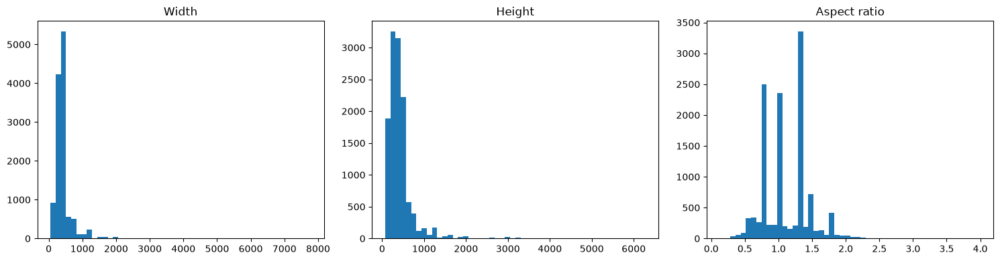

Tiny images: 1
              width        height        aspect
count  12259.000000  12259.000000  12259.000000
mean     440.069011    430.640754      1.115599
std      329.596119    361.837028      0.370003
min       51.000000     71.000000      0.127500
25%      252.000000    225.000000      0.750469
50%      400.000000    384.000000      1.000000
75%      512.000000    533.000000      1.333333
max     7786.000000   6283.000000      6.376344


In [9]:
ok = df[df["ok"]]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(ok["width"], bins=50)
ax[0].set_title("Width")

ax[1].hist(ok["height"], bins=50)
ax[1].set_title("Height")

ax[2].hist(ok["aspect"].clip(0, 4), bins=50)
ax[2].set_title("Aspect ratio")

plt.tight_layout()
plt.show()

MIN_SIDE = 64
tiny = ok[(ok["width"] < MIN_SIDE) | (ok["height"] < MIN_SIDE)]
print("Tiny images:", len(tiny))
print(ok[["width", "height", "aspect"]].describe())

### 3.2 Class distribution

The dataset is moderately imbalanced (**max/min ≈ 4.2**, *clothes* most frequent, *trash* least).
Two implications:

1. **Accuracy alone is misleading** — a model can score well while neglecting minority classes. Model selection therefore uses **macro-F1**, which weights every class equally.
2. Inverse-frequency **class weights** are prepared (Section 6) as an optional remedy.

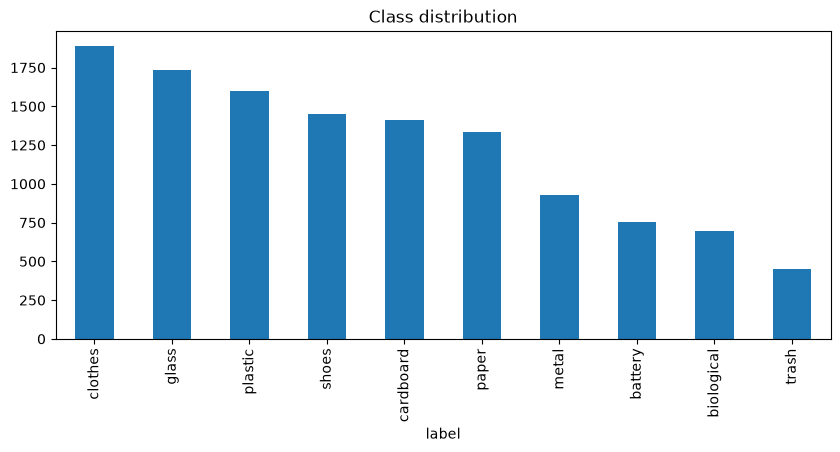

Imbalance ratio (max/min): 4.18


In [10]:
counts = ok["label"].value_counts()
counts.plot.bar(figsize=(10, 4), title="Class distribution")
plt.show()
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")

## 4. Duplicate & leakage analysis

Web-scraped datasets routinely contain the same photo multiple times. If copies land in both train and test,
test metrics are inflated because the model is partly evaluated on images it has already seen.

1. **Exact duplicates** — identical MD5 hashes (none found).
2. **Near-duplicates** — two images are linked when the Hamming distance between their pHashes is ≤ `PHASH_MAX_DIST` (4 of 64 bits).
   Linked images are merged **transitively** into groups via connected components on a sparse adjacency matrix.
   Pairwise distances are computed in chunks with a vectorised popcount, so the O(N²) comparison stays fast and memory-bounded.
3. **Label noise** — a group whose members carry *different* labels is the same picture annotated twice inconsistently. Such groups are dropped.

In [11]:
dup_exact = ok[ok.duplicated("md5", keep=False)].sort_values("md5")
print("Exact duplicate files:", len(dup_exact), "| groups:", dup_exact["md5"].nunique())

# Same file under different labels = definite label noise
cross_label = dup_exact.groupby("md5")["label"].nunique()
print("MD5 groups with conflicting labels:", (cross_label > 1).sum())

Exact duplicate files: 0 | groups: 0
MD5 groups with conflicting labels: 0


In [12]:
_POPCOUNT_U8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def popcount64(x: np.ndarray) -> np.ndarray:
    """Bit count for a uint64 array (numpy>=2.0 fast path, lookup-table fallback)."""
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    return _POPCOUNT_U8[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1)


def phash_groups(hashes: pd.Series, max_dist: int = 4, chunk: int = 512) -> np.ndarray:
    """Assign a group id so that images with pHash Hamming distance <= max_dist
    (transitively) share the same group."""
    h = np.array([int(s, 16) for s in hashes], dtype=np.uint64)
    rows, cols = [], []
    for i in range(0, len(h), chunk):
        dist = popcount64(h[i:i + chunk, None] ^ h[None, :])
        r, c = np.nonzero(dist <= max_dist)
        r += i
        keep = r < c  # upper triangle only, no self-pairs
        rows.append(r[keep])
        cols.append(c[keep])
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    n = len(h)
    adj = coo_matrix((np.ones(len(rows), dtype=np.int8), (rows, cols)), shape=(n, n))
    return connected_components(adj, directed=False)[1]


PHASH_MAX_DIST = 4

ok = df[df["ok"]].reset_index(drop=True).copy()
ok["group"] = phash_groups(ok["phash"], max_dist=PHASH_MAX_DIST)

group_sizes = ok["group"].map(ok["group"].value_counts())
print(f"Unique groups: {ok['group'].nunique()} / {len(ok)} images")
print(f"Images in near-duplicate groups: {(group_sizes > 1).sum()}")
print(f"Largest group size: {group_sizes.max()}")

labels_per_group = ok.groupby("group")["label"].nunique()
conflict_groups = labels_per_group[labels_per_group > 1].index
print(f"Groups with conflicting labels: {len(conflict_groups)}")

Unique groups: 12255 / 12259 images
Images in near-duplicate groups: 8
Largest group size: 2
Groups with conflicting labels: 1


### 4.1 Visual check of duplicate groups

Visual inspection confirms the threshold catches genuine near-duplicates without merging merely similar images.
The second grid shows the conflicting-label group (identical image, two labels), which is removed in the next cell.

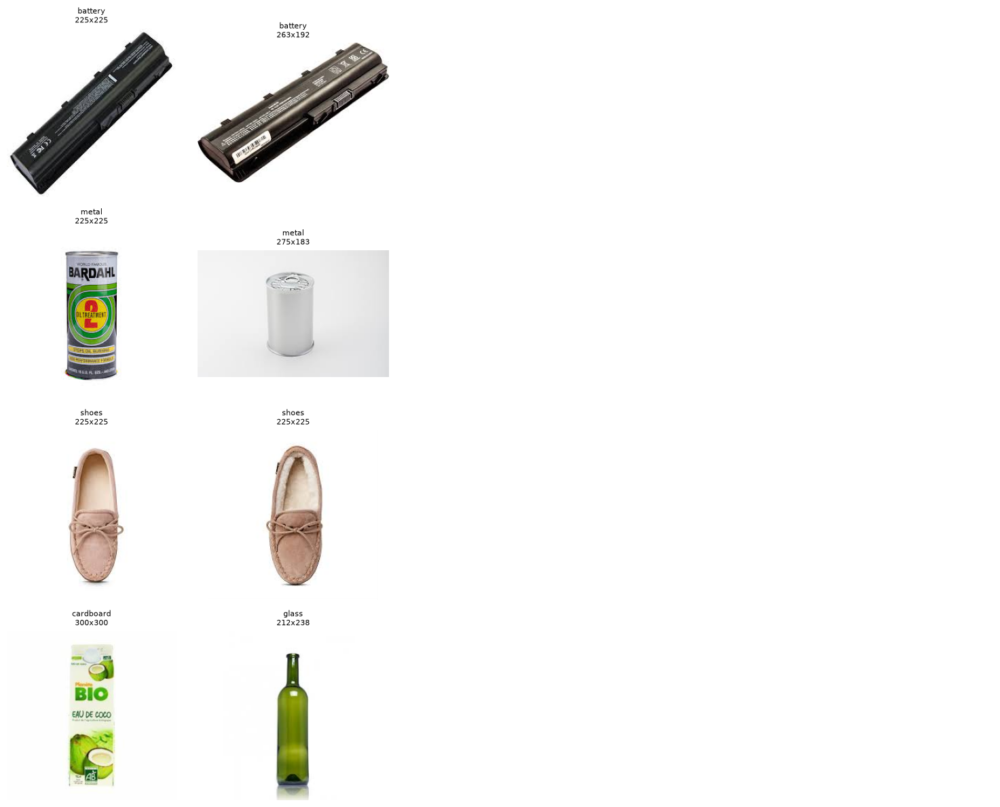

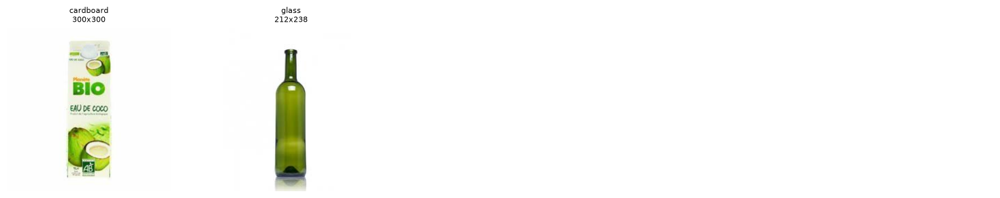

In [13]:
def show_dup_groups(frame: pd.DataFrame, n_groups: int = 6, max_per_group: int = 5,
                    only_conflicts: bool = False) -> None:
    sizes = frame["group"].value_counts()
    candidates = sizes[sizes > 1].index
    if only_conflicts:
        candidates = candidates.intersection(conflict_groups)
    rng = np.random.default_rng(SEED)
    picked = rng.choice(candidates, size=min(n_groups, len(candidates)), replace=False)

    fig, axes = plt.subplots(len(picked), max_per_group,
                             figsize=(3 * max_per_group, 3 * len(picked)), squeeze=False)
    for row, g in zip(axes, picked):
        members = frame[frame["group"] == g].head(max_per_group)
        for ax, (_, r) in zip(row, members.iterrows()):
            with Image.open(r["path"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"{r['label']}\n{r['width']}x{r['height']}", fontsize=8)
        for ax in row:
            ax.axis("off")
    plt.tight_layout()
    plt.show()


show_dup_groups(ok)  # random duplicate groups
show_dup_groups(ok, only_conflicts=True)  # same image, different labels -> label noise

In [14]:
# Drop near-duplicate groups whose members carry conflicting labels (label noise)
n_before = len(ok)
ok = ok[~ok["group"].isin(conflict_groups)].reset_index(drop=True)
print(f"Removed {n_before - len(ok)} images from {len(conflict_groups)} conflicting group(s)")

Removed 2 images from 1 conflicting group(s)


### 4.2 Leakage diagnostic for a naive random split

For reference, a plain `train_test_split` (70/15/15, stratified, **group-unaware**) is simulated, and we measure how many
val/test images have a near-duplicate in train. On this dataset the leakage is tiny (~0.1 %), but the group-aware split below
guarantees it is **zero** at no extra cost, which is the right default for any image dataset.

In [15]:
_old = ok[["path", "label", "group"]].copy()
_old["y"] = _old["label"].map({c: i for i, c in enumerate(sorted(_old["label"].unique()))})
_old_train, _old_tmp = train_test_split(_old, test_size=0.30, stratify=_old["y"], random_state=SEED)
_old_val, _old_test = train_test_split(_old_tmp, test_size=0.50, stratify=_old_tmp["y"], random_state=SEED)

train_groups = set(_old_train["group"])
for name, part in [("val", _old_val), ("test", _old_test)]:
    leaked = part["group"].isin(train_groups).mean()
    print(f"Old split | {name}: {leaked:.1%} of images have a near-duplicate in train")

Old split | val: 0.1% of images have a near-duplicate in train
Old split | test: 0.0% of images have a near-duplicate in train


## 5. Group-aware stratified split

`StratifiedGroupKFold` is used twice to carve out held-out folds that are **(a)** stratified by class and **(b)** disjoint at the
near-duplicate-group level:

* 7 folds → 1 fold becomes **test** (~14.5 %)
* the remaining 6/7 → 6 folds → 1 fold becomes **validation** (~14.5 %), the rest **train** (~71 %)

| Split | Images | Role |
|-------|-------:|------|
| train | 8,754 | Fit the classification head |
| val   | 1,752 | Model selection (best epoch, TTA decision, any tuning) |
| test  | 1,751 | **Touched once**, for the final unbiased estimate |

The asserts guarantee no group is shared between splits; the class-proportion table confirms stratification held (differences ≤ 0.1 pp).
Splits are persisted to `splits/*.csv` for reproducibility.

> `df` is re-bound here to the cleaned, deduplicated frame — from this point on it no longer refers to the raw audit table.

In [16]:
df = ok[["path", "label", "group"]].reset_index(drop=True)

classes: list[str] = sorted(df["label"].unique())
class_to_idx: dict[str, int] = {c: i for i, c in enumerate(classes)}
df["y"] = df["label"].map(class_to_idx)


def holdout_group_split(
        frame: pd.DataFrame, n_splits: int, seed: int
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Hold out one stratified, group-disjoint fold (~1/n_splits of the data)."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest_idx, hold_idx = next(sgkf.split(frame, frame["y"], groups=frame["group"]))
    return frame.iloc[rest_idx], frame.iloc[hold_idx]


# ~71% train / ~14.5% val / ~14.5% test, no group shared between splits
trainval_df, test_df = holdout_group_split(df, n_splits=7, seed=SEED)
train_df, val_df = holdout_group_split(trainval_df, n_splits=6, seed=SEED)

# Leakage guard
assert not set(train_df["group"]) & set(val_df["group"])
assert not set(train_df["group"]) & set(test_df["group"])
assert not set(val_df["group"]) & set(test_df["group"])

# Persist splits for reproducibility
SPLITS_DIR.mkdir(exist_ok=True)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    to_relative(d, DATA_DIR).to_csv(SPLITS_DIR / f"{name}.csv", index=False)

# Sanity check: class proportions must match across splits
dist = pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "val": val_df["label"].value_counts(normalize=True),
    "test": test_df["label"].value_counts(normalize=True),
}).round(3)
print(dist)
print({k: len(v) for k, v in [("train", train_df), ("val", val_df), ("test", test_df)]})

            train    val   test
label                          
clothes     0.154  0.154  0.154
glass       0.142  0.142  0.142
plastic     0.130  0.130  0.130
shoes       0.118  0.118  0.118
cardboard   0.115  0.115  0.115
paper       0.109  0.109  0.109
metal       0.076  0.076  0.075
battery     0.062  0.062  0.062
biological  0.057  0.057  0.057
trash       0.037  0.037  0.037
{'train': 8754, 'val': 1752, 'test': 1751}


In [17]:
train_df

,path,label,group,y
0,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,0,0
1,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,1,0
3,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,3,0
4,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,4,0
6,C:\Users\User\Projects\DL_Learning\data\garbag...,battery,6,0
...,...,...,...,...
12251,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,12249,9
12252,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,12250,9
12253,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,12251,9
12254,C:\Users\User\Projects\DL_Learning\data\garbag...,trash,12252,9


## 6. Class imbalance — inverse-frequency weights

$$w_c = \left(\frac{N}{K \cdot n_c}\right)^{\alpha}, \qquad \text{then normalised so that } \overline{w} = 1$$

where $N$ is the number of training images, $K$ the number of classes and $n_c$ the count of class $c$.
`alpha = 1` is full inverse frequency, `alpha = 0.5` a softer square-root variant.
Normalising to mean 1 keeps the loss scale (and thus the effective learning rate) comparable to the unweighted loss.

Weights are computed on the **training split only** to avoid leaking val/test statistics.
They are wired into the loss behind `USE_CLASS_WEIGHTS` (Section 9); the reported run trains **without** them.

In [18]:
def compute_class_weights(
        labels: pd.Series, num_classes: int, alpha: float = 1.0
) -> torch.Tensor:
    """Inverse-frequency weights, normalized to mean 1.

    alpha=1.0 -> full inverse frequency; alpha=0.5 -> softer (sqrt) version.
    """
    y = torch.from_numpy(labels.to_numpy(dtype=np.int64, copy=True))
    counts = torch.bincount(y, minlength=num_classes).float()
    weights = (counts.sum() / (num_classes * counts)) ** alpha
    return weights / weights.mean()

In [19]:
class_weights = compute_class_weights(train_df["y"], len(classes), alpha=1.0).to(device)
for class_name, class_weight in zip(classes, class_weights.tolist()):
    print(f"{class_name}'s weight: {class_weight:.2f}")

battery's weight: 1.33
biological's weight: 1.44
cardboard's weight: 0.72
clothes's weight: 0.53
glass's weight: 0.58
metal's weight: 1.08
paper's weight: 0.75
plastic's weight: 0.63
shoes's weight: 0.70
trash's weight: 2.23


## 7. Preprocessing & augmentation

| Stage | Transform | Rationale |
|-------|-----------|-----------|
| **Train** | `RandomResizedCrop(224, scale=(0.7, 1.0))` | Scale/translation invariance; the conservative lower bound (0.7) avoids crops that lose the object entirely |
| | `RandomHorizontalFlip()` | Waste items have no canonical left/right orientation |
| | `ColorJitter(0.2, 0.2, 0.2)` | Robustness to lighting and white balance (brightness, contrast, saturation) |
| | `ToTensor` + `Normalize(ImageNet)` | Matches the pretraining input distribution |
| **Val / Test** | `weights.transforms()` → resize shorter side to 232 (bilinear), center-crop 224, normalise | Uses the *exact* preprocessing published with the weights — no hand-copied constants that can drift |

Augmentation is applied **only** to the training split; evaluation must be deterministic.

**DataLoaders.** Training uses `shuffle=True`, `drop_last=True` (no tiny, noisy final batch) and a seeded `Generator` for
reproducible ordering. Val/test use `shuffle=False`, which the evaluation section relies on to map predictions back to file paths
(it is asserted, not assumed). `GarbageDataset` lives in a separate module so it can be pickled by worker processes on Windows.

In [20]:
regnet_1_6GF_weights = RegNet_Y_1_6GF_Weights.DEFAULT
regnet_1_6GF_weights

RegNet_Y_1_6GF_Weights.IMAGENET1K_V2

In [21]:
train_tf = T.Compose([
    T.RandomResizedCrop(size=IMAGE_SIZE, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD)
])

eval_tf = regnet_1_6GF_weights.transforms()
print(eval_tf)  # verify: resize_size, crop_size, interpolation, mean/std

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [22]:
from garbage_dataset import GarbageDataset

train_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)
eval_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=False)

train_dl = DataLoader(GarbageDataset(train_df, train_tf), BATCH_SIZE, shuffle=True,
                      drop_last=True, generator=torch.Generator().manual_seed(SEED),
                      **train_kwargs)
val_dl = DataLoader(GarbageDataset(val_df, eval_tf), BATCH_SIZE, shuffle=False, **eval_kwargs)
test_dl = DataLoader(GarbageDataset(test_df, eval_tf), BATCH_SIZE, shuffle=False, **eval_kwargs)

loader_kwargs = train_kwargs  # v3 fine-tuning section reuses this for its train loaders

## 8. Model architecture — RegNetY-1.6GF

**RegNet** (Radosavovic et al., *Designing Network Design Spaces*, 2020) is a family of CNNs whose stage widths and depths
follow a simple quantised linear rule found by design-space search. The **Y** variant adds **Squeeze-and-Excitation** blocks.

| Component | Detail |
|-----------|--------|
| Stem | 3×3 conv, stride 2 → 32 channels |
| Body | 4 stages of residual bottleneck blocks with **group convolutions** + SE; widths 48 → 120 → 336 → 888, depths 2 / 6 / 17 / 2 |
| Head | Global average pooling → `Linear(888, K)` |
| Pretraining | ImageNet-1k, `IMAGENET1K_V2` recipe (≈ 80.9 % top-1) |
| Size / cost | ≈ 11.2 M parameters, ≈ 1.6 GFLOPs at 224×224 |

It offers a strong accuracy/compute trade-off for a ~9k-image dataset on a single laptop GPU.

### 8.1 Linear probing (frozen backbone)

1. All backbone parameters are frozen (`requires_grad = False`).
2. The 1000-class ImageNet head is replaced with a fresh `Linear(888, 10)` — **8,890 trainable parameters** out of 10.3 M (see the `torchinfo` summary).
3. During training, `freeze_bn_of_frozen_modules` puts every frozen `BatchNorm` layer in `eval()` mode. Without it, `model.train()`
   would keep updating BN running statistics from small, augmented batches even though BN weights are frozen, silently shifting the
   features the head is being fitted on.

Linear probing is the right first stage: it is fast, nearly impossible to overfit, and gives a clean baseline before any fine-tuning.

In [23]:
model_regnet_1_6gf = regnet_y_1_6gf(weights=regnet_1_6GF_weights).to(device)
model_regnet_1_6gf

RegNet(
  (stem): SimpleStemIN(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (trunk_output): Sequential(
    (block1): AnyStage(
      (block1-0): ResBottleneckBlock(
        (proj): Conv2dNormActivation(
          (0): Conv2d(32, 48, kernel_size=(1, 1), stride=(2, 2), bias=False)
          (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        )
        (f): BottleneckTransform(
          (a): Conv2dNormActivation(
            (0): Conv2d(32, 48, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): ReLU(inplace=True)
          )
          (b): Conv2dNormActivation(
            (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), g

In [24]:
for param in model_regnet_1_6gf.parameters():
    param.requires_grad = False

In [25]:
num_class = len(classes)

torch.manual_seed(SEED)  
model_regnet_1_6gf.fc = nn.Linear(
    in_features=model_regnet_1_6gf.fc.in_features, out_features=num_class
).to(device)

In [26]:
summary(model_regnet_1_6gf, input_size=(BATCH_SIZE, IMAGE_CHANNELS, *IMAGE_SIZE),
        col_names=["input_size", "output_size", "num_params", "trainable", "kernel_size"],
        col_width=20, row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable            Kernel Shape
RegNet (RegNet)                                              [64, 3, 224, 224]    [64, 10]             --                   Partial              --
├─SimpleStemIN (stem)                                        [64, 3, 224, 224]    [64, 32, 112, 112]   --                   False                --
│    └─Conv2d (0)                                            [64, 3, 224, 224]    [64, 32, 112, 112]   (864)                False                [3, 3]
│    └─BatchNorm2d (1)                                       [64, 32, 112, 112]   [64, 32, 112, 112]   (64)                 False                --
│    └─ReLU (2)                                              [64, 32, 112, 112]   [64, 32, 112, 112]   --                   --                   --
├─Sequential (trunk_output)                                  [64, 32, 112, 112]   [64, 888, 7, 7] 

## 9. Training

| Hyperparameter | Value | Notes |
|----------------|-------|-------|
| Loss | `CrossEntropyLoss` | Unweighted in the reported run (`USE_CLASS_WEIGHTS = False`) |
| Optimiser | `AdamW`, lr = 1e-3, weight decay = 0.01 (default) | Only the head's parameters are passed in |
| LR schedule | `CosineAnnealingLR(T_max=15, eta_min=1e-5)` | Stepped once per epoch |
| Epochs | 15 | |
| Batch size | 64 | `drop_last=True` on train |
| Model selection | best **validation macro-F1** | Robust to class imbalance, unlike accuracy |
| Early stopping | patience = 5 epochs on val macro-F1 | |
| Checkpoint | `checkpoints/regnet_y_1_6gf_head.pt` | Model + optimiser + scheduler state + class list |

**Training loop design**

* `train_step` — forward → loss → `zero_grad(set_to_none=True)` → backward → step. Accuracy uses `argmax` on logits (softmax is monotonic, so it is unnecessary).
* `evaluate` — one inference pass under `torch.inference_mode()` that returns loss, accuracy, macro-F1 **and** the raw predictions/probabilities, so Section 10 reuses the same code path that drove model selection.
* `train` — logs the per-epoch history, saves a checkpoint whenever val macro-F1 improves, and **restores the best weights** at the end so the in-memory model is the selected one.

> **Fix applied.** `train()` called `evaluate(...)`, but the notebook only defined `val_step(...)`, which returns a tuple and no macro-F1.
> The run only worked because `evaluate` existed in the kernel from an earlier session; *Restart & Run All* would have raised `NameError`.
> `val_step` has been replaced by `collect_predictions` + `evaluate` below.

In [27]:
# The reported run used an *unweighted* loss. The inverse-frequency weights from
# Section 6 are kept behind a flag so the two settings can be compared cleanly
# (re-train with USE_CLASS_WEIGHTS = True and compare val macro-F1).
USE_CLASS_WEIGHTS = False

loss_fn = nn.CrossEntropyLoss(weight=class_weights if USE_CLASS_WEIGHTS else None)
optimizer = torch.optim.AdamW(
    (p for p in model_regnet_1_6gf.parameters() if p.requires_grad), lr=1e-3
)

In [28]:
def freeze_bn_of_frozen_modules(model: nn.Module) -> None:
    """Put BN layers whose affine params are frozen into eval mode,
    so their running stats are not updated during training."""
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(
                p.requires_grad for p in m.parameters()
        ):
            m.eval()

In [29]:
AMP_DTYPE: torch.dtype = torch.bfloat16  # use torch.float16 + scaler on GPUs without bf16

def train_step(model: nn.Module,
               dataloader: DataLoader,
               optimizer: torch.optim.Optimizer,
               loss_fn: nn.Module,
               device: torch.device,
               amp_dtype: torch.dtype | None = torch.bfloat16,
               scaler: GradScaler | None = None) -> tuple[float, float]:
    model.train()
    freeze_bn_of_frozen_modules(model)

    total_loss, correct, total = 0.0, 0, 0

    for X, y in dataloader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Forward + loss under autocast; backward stays outside
        with autocast(device_type=device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            logits = model(X)
            loss = loss_fn(logits, y)

        if scaler is not None:  # FP16 path only
            scaler.scale(loss).backward()
            # scaler.unscale_(optimizer)  # required before clip_grad_norm_
            scaler.step(optimizer)
            scaler.update()
        else:  # BF16 / FP32 path
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total

In [30]:
@torch.inference_mode()
def collect_predictions(model: nn.Module,
                        dataloader: DataLoader,
                        device: torch.device,
                        loss_fn: nn.Module | None = None,
                        tta_hflip: bool = False) -> dict[str, np.ndarray | float]:
    """Single inference pass that gathers everything downstream analysis needs.

    Returns y_true, y_pred, softmax probabilities and (optionally) the mean loss.
    With tta_hflip=True the logits of the image and its horizontal mirror are averaged.
    """
    model.eval()
    logits_chunks, target_chunks = [], []
    total_loss, n_seen = 0.0, 0

    for X, y in dataloader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(X).float()
        if tta_hflip:
            logits = 0.5 * (logits + model(torch.flip(X, dims=[3])).float())

        if loss_fn is not None:
            total_loss += loss_fn(logits, y).item() * y.size(0)
        n_seen += y.size(0)

        logits_chunks.append(logits.cpu())
        target_chunks.append(y.cpu())

    probs = torch.cat(logits_chunks).softmax(dim=1)
    return {
        "y_true": torch.cat(target_chunks).numpy(),
        "y_pred": probs.argmax(dim=1).numpy(),
        "probs": probs.numpy(),
        "loss": total_loss / n_seen if loss_fn is not None else float("nan"),
    }


def evaluate(model: nn.Module,
             dataloader: DataLoader,
             loss_fn: nn.Module,
             device: torch.device,
             tta_hflip: bool = False) -> dict[str, np.ndarray | float]:
    """Loss, accuracy and macro-F1 on a loader (used for model selection in `train`).

    The raw predictions are returned too, so the post-training analysis can reuse them.
    """
    out = collect_predictions(model, dataloader, device, loss_fn, tta_hflip)
    labels = np.arange(out["probs"].shape[1])  # score every class even if absent in a split
    out["acc"] = float((out["y_true"] == out["y_pred"]).mean())
    out["macro_f1"] = float(f1_score(out["y_true"], out["y_pred"], labels=labels,
                                     average="macro", zero_division=0))
    return out

In [31]:
def train(model: nn.Module,
          train_dataloader: DataLoader,
          val_dataloader: DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: nn.Module,
          epochs: int = 10,
          device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu"),
          scheduler: torch.optim.lr_scheduler.LRScheduler | None = None,
          ckpt_path: Path | None = None,
          classes: list[str] | None = None,
          patience: int | None = None,
          ) -> dict[str, list[float]]:
    """Train with best-checkpoint selection on val macro-F1.

    scheduler: stepped once per epoch. ReduceLROnPlateau is stepped with val macro-F1.
    patience: early stopping on val macro-F1 (None = disabled).
    """
    results = {"train_loss": [], "train_acc": [], "val_loss": [],
               "val_acc": [], "val_macro_f1": [], "lr": []}

    best_f1, best_epoch, epochs_no_improve = -1.0, -1, 0

    if ckpt_path is not None:
        ckpt_path.parent.mkdir(parents=True, exist_ok=True)

    for epoch in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = train_step(model, train_dataloader, optimizer, loss_fn, device)
        val_res = evaluate(model, val_dataloader, loss_fn, device)
        val_f1 = val_res["macro_f1"]

        # Scheduler step (per epoch)
        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_f1)
            else:
                scheduler.step()

        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["val_loss"].append(val_res["loss"])
        results["val_acc"].append(val_res["acc"])
        results["val_macro_f1"].append(val_f1)
        results["lr"].append(lr)

        improved = val_f1 > best_f1
        if improved:
            best_f1, best_epoch, epochs_no_improve = val_f1, epoch, 0
            if ckpt_path is not None:
                torch.save({
                    "model": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict() if scheduler is not None else None,
                    "epoch": epoch,
                    "val_macro_f1": val_f1,
                    "classes": classes,
                }, ckpt_path)
        else:
            epochs_no_improve += 1

        print(f"Epoch {epoch + 1:02d}/{epochs} | lr {lr:.2e} | "
              f"train loss {train_loss:.4f} acc {train_acc * 100:.2f}% | "
              f"val loss {val_res['loss']:.4f} acc {val_res['acc'] * 100:.2f}% "
              f"F1 {val_f1:.4f}{'  *best*' if improved else ''}")

        if patience is not None and epochs_no_improve >= patience:
            print(f"Early stopping: no improvement for {patience} epochs.")
            break

    # Restore best weights so that test evaluation uses the selected model
    if ckpt_path is not None and ckpt_path.exists():
        state = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(state["model"])
        print(f"Restored best model from epoch {best_epoch + 1} (val macro-F1 = {best_f1:.4f})")

    return results

In [32]:
EPOCHS = 15
CKPT_PATH = PROJECT_DIR / "checkpoints" / "regnet_y_1_6gf_head.pt"
LP_HISTORY_PATH = PROJECT_DIR / "reports" / "regnet_y_1_6gf_head" / "history.csv"  # written in Section 10.10
RETRAIN_LINEAR_PROBE = False  # True -> ignore the cached checkpoint and train again (invalidates all Stage-2 runs)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

if CKPT_PATH.exists() and LP_HISTORY_PATH.exists() and not RETRAIN_LINEAR_PROBE:
    # Cache hit: restore the selected weights and the per-epoch history instead of training again.
    _state = torch.load(CKPT_PATH, map_location=device, weights_only=False)
    model_regnet_1_6gf.load_state_dict(_state["model"])
    results = pd.read_csv(LP_HISTORY_PATH, index_col="epoch").to_dict(orient="list")
    print(f"Loaded cached linear probe from {CKPT_PATH.name}: best epoch {_state['epoch'] + 1}, "
          f"val macro-F1 = {_state['val_macro_f1']:.4f}, {len(results['train_loss'])} epochs of history. "
          f"Set RETRAIN_LINEAR_PROBE = True to retrain.")
else:
    results = train(
        model=model_regnet_1_6gf,
        train_dataloader=train_dl,
        val_dataloader=val_dl,
        optimizer=optimizer,
        loss_fn=loss_fn,
        epochs=EPOCHS,
        device=device,
        scheduler=scheduler,
        ckpt_path=CKPT_PATH,
        classes=classes,
        patience=5,
    )

Loaded cached linear probe from regnet_y_1_6gf_head.pt: best epoch 14, val macro-F1 = 0.9351, 15 epochs of history. Set RETRAIN_LINEAR_PROBE = True to retrain.


**Run summary.** Best validation macro-F1 = **0.9351** (accuracy 94.01 %) at epoch 15 (the last epoch; val macro-F1 was still creeping up). Train and validation curves stay close
(final train acc ≈ 95.4 % vs. val ≈ 94.0 %), which is the expected signature of a linear probe: little overfitting, and the
remaining error is mostly a *capacity* limit of frozen ImageNet features rather than variance. Early stopping did not trigger.

## 10. Post-training evaluation

In [33]:
MODEL_NAME = "regnet_y_1_6gf_head"
REPORTS_DIR = PROJECT_DIR / "reports" / MODEL_NAME
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Fixed colour roles used across all evaluation figures.
TRAIN_COLOR = "#2a78d6"  # blue   -> train / correct
VAL_COLOR = "#eb6834"  # orange -> validation / incorrect
NEUTRAL_COLOR = "#52514e"  # gray   -> reference lines (best epoch, perfect calibration)
SEQ_CMAP = "Blues"  # single-hue sequential map for heatmaps

sns.set_theme(style="whitegrid", context="notebook")


def save_figure(fig: plt.Figure, name: str) -> Path:
    """Persist a figure next to the other evaluation artifacts."""
    path = REPORTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

### 10.1 Learning curves

Four panels, all sharing the epoch axis: loss, accuracy, validation macro-F1 (the selection metric) and the learning rate.
The dashed line marks the selected epoch.

How to read them:

* **Train metrics are measured on augmented batches in `train()` mode**, validation on clean center crops in `eval()` mode, so
  validation loss *below* training loss is normal here and not a bug.
* A widening gap (train ↑, val ↓) signals overfitting; flat, close curves signal a capacity limit.

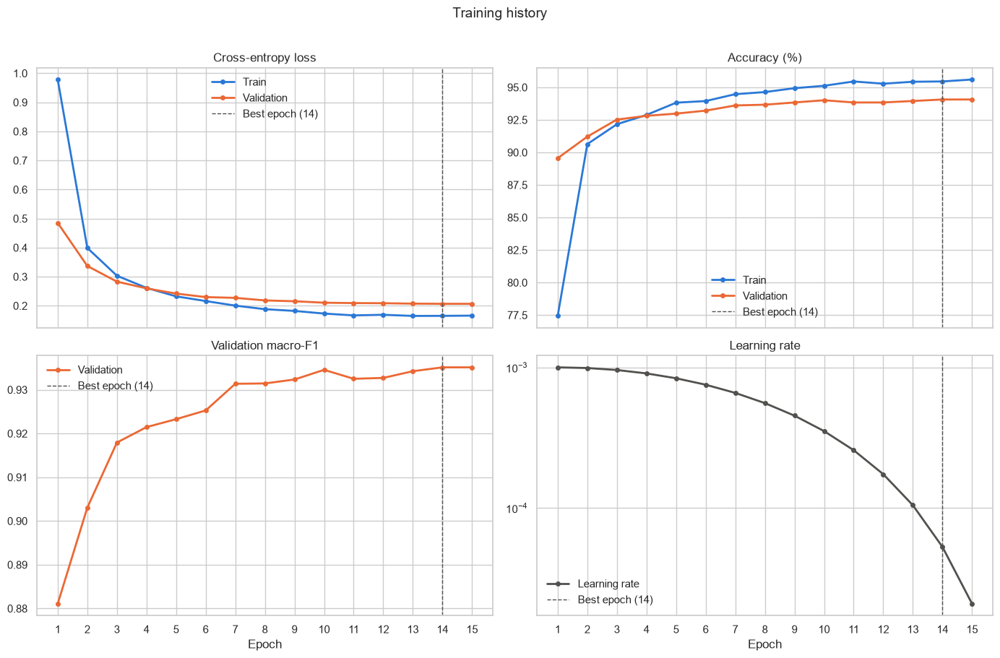

Best epoch           : 14
Val macro-F1 / acc   : 0.9351 / 94.06%
Train-val acc gap    : +1.39 pp


In [34]:
def plot_training_history(history: dict[str, list[float]],
                          monitor: str = "val_macro_f1") -> plt.Figure:
    """Plot loss / accuracy / monitored metric / LR per epoch and mark the best epoch."""
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    best_epoch = int(np.argmax(history[monitor])) + 1

    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    panels = [
        (axes[0, 0], "Cross-entropy loss", [("train_loss", "Train", TRAIN_COLOR),
                                            ("val_loss", "Validation", VAL_COLOR)], 1.0),
        (axes[0, 1], "Accuracy (%)", [("train_acc", "Train", TRAIN_COLOR),
                                      ("val_acc", "Validation", VAL_COLOR)], 100.0),
        (axes[1, 0], "Validation macro-F1", [("val_macro_f1", "Validation", VAL_COLOR)], 1.0),
        (axes[1, 1], "Learning rate", [("lr", "Learning rate", NEUTRAL_COLOR)], 1.0),
    ]

    for ax, title, series, scale in panels:
        for key, label, color in series:
            ax.plot(epochs, np.asarray(history[key]) * scale, color=color, lw=2,
                    marker="o", ms=4, label=label)
        ax.axvline(best_epoch, color=NEUTRAL_COLOR, ls="--", lw=1,
                   label=f"Best epoch ({best_epoch})")
        ax.set_title(title)
        ax.legend(frameon=False)

    axes[1, 1].set_yscale("log")
    for ax in axes[1]:
        ax.set_xlabel("Epoch")
        ax.set_xticks(epochs)
    fig.suptitle("Training history", fontsize=14, y=1.01)
    fig.tight_layout()
    return fig


fig = plot_training_history(results)
save_figure(fig, "training_history")
plt.show()

best_idx = int(np.argmax(results["val_macro_f1"]))
print(f"Best epoch           : {best_idx + 1}")
print(f"Val macro-F1 / acc   : {results['val_macro_f1'][best_idx]:.4f} / {results['val_acc'][best_idx]:.2%}")
print(f"Train-val acc gap    : {(results['train_acc'][best_idx] - results['val_acc'][best_idx]) * 100:+.2f} pp")

In [35]:
# Per-class precision / recall / F1 of the trained linear probe (best checkpoint restored by train()).
from sklearn.metrics import classification_report, precision_recall_fscore_support

label_ids = np.arange(len(classes))
for split_name, loader in [("Validation", val_dl), ("Test", test_dl)]:
    out = collect_predictions(model_regnet_1_6gf, loader, device)
    y_true, y_pred = out["y_true"], out["y_pred"]

    p, r, f, support = precision_recall_fscore_support(
        y_true, y_pred, labels=label_ids, average=None, zero_division=0
    )
    report = pd.DataFrame(
        {"precision": p, "recall": r, "f1": f, "support": support},
        index=pd.Index(classes, name="class"),
    ).sort_values("f1")  # weakest class first

    print(f"\n{'=' * 20} {split_name} {'=' * 20}")
    print(report.to_string(float_format=lambda v: f"{v:.4f}"))
    print(f"\naccuracy {np.mean(y_true == y_pred):.4f} | "
          f"macro-F1 {f.mean():.4f} | weighted-F1 {np.average(f, weights=support):.4f}")
    print(classification_report(y_true, y_pred, labels=label_ids, target_names=classes,
                                digits=4, zero_division=0))


==================== Validation ====================
            precision  recall     f1  support
class                                        
trash          0.8088  0.8462 0.8271       65
plastic        0.8969  0.8772 0.8869      228
paper          0.9077  0.9267 0.9171      191
metal          0.9173  0.9173 0.9173      133
cardboard      0.9257  0.9257 0.9257      202
glass          0.9536  0.9113 0.9320      248
battery        0.9813  0.9722 0.9767      108
shoes          0.9763  0.9952 0.9856      207
biological     0.9804  1.0000 0.9901      100
clothes        0.9854  1.0000 0.9926      270

accuracy 0.9406 | macro-F1 0.9351 | weighted-F1 0.9405
              precision    recall  f1-score   support

     battery     0.9813    0.9722    0.9767       108
  biological     0.9804    1.0000    0.9901       100
   cardboard     0.9257    0.9257    0.9257       202
     clothes     0.9854    1.0000    0.9926       270
       glass     0.9536    0.9113    0.9320       248
       metal 

### 11.0 Shared helpers

Sections 11–14 reuse the evaluation helpers that were defined in the removed Section 10: checkpoint loading with a class-order
check, split-alignment guard, calibration (ECE), global metrics, bootstrap CI, confusion-matrix / calibration plots, per-image
prediction frames and image grids. They are collected here, unchanged, so the notebook runs without the old Section 10
(only Section 9 and the first cells of Section 10 that define `REPORTS_DIR`, the colours and `SEQ_CMAP` are still needed).

The second cell stores the linear-probe training history on disk, which is what lets Section 9 skip retraining on re-runs.

In [36]:
# Shared evaluation helpers (restored: they used to live in Section 10 and are required by Sections 11-14).
# Definitions only - nothing is computed here.


# --- Checkpoint loading and split-alignment guard
def load_checkpoint(model: nn.Module, path: Path, device: torch.device,
                    expected_classes: list[str] | None = None) -> dict:
    """Load model weights from a training checkpoint and validate its class list."""
    state = torch.load(path, map_location=device, weights_only=False)
    if expected_classes is not None and state.get("classes") is not None:
        assert list(state["classes"]) == list(expected_classes), (
            f"Class order mismatch: checkpoint={state['classes']} vs current={expected_classes}"
        )
    model.load_state_dict(state["model"])
    model.eval()
    return state


# --- Checkpoint loading and split-alignment guard
def check_alignment(frame: pd.DataFrame, res: dict, split: str) -> None:
    """Fail loudly if loader order != DataFrame order (would corrupt per-image analysis)."""
    assert len(res["y_true"]) == len(frame), f"{split}: {len(res['y_true'])} predictions vs {len(frame)} rows"
    assert np.array_equal(res["y_true"], frame["y"].to_numpy()), (
        f"{split}: loader order differs from DataFrame order -- use shuffle=False"
    )


# --- Calibration and global metrics
def calibration_table(y_true: np.ndarray, probs: np.ndarray, n_bins: int = 15) -> pd.DataFrame:
    """Bin predictions by confidence (max softmax prob) and compare to empirical accuracy."""
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == y_true
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_idx = np.clip(np.digitize(confidence, edges[1:-1], right=True), 0, n_bins - 1)

    rows = []
    for b in range(n_bins):
        mask = bin_idx == b
        rows.append({
            "bin_lower": edges[b],
            "bin_upper": edges[b + 1],
            "count": int(mask.sum()),
            "confidence": confidence[mask].mean() if mask.any() else np.nan,
            "accuracy": correct[mask].mean() if mask.any() else np.nan,
        })
    return pd.DataFrame(rows)


# --- Calibration and global metrics
def expected_calibration_error(y_true: np.ndarray, probs: np.ndarray, n_bins: int = 15) -> float:
    table = calibration_table(y_true, probs, n_bins).dropna()
    weights = table["count"] / table["count"].sum()
    return float((weights * (table["accuracy"] - table["confidence"]).abs()).sum())


# --- Calibration and global metrics
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, probs: np.ndarray) -> dict[str, float]:
    """Global classification metrics for one split."""
    labels = np.arange(probs.shape[1])
    metrics: dict[str, float] = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=labels, average=avg, zero_division=0
        )
        metrics.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})

    metrics["top3_accuracy"] = top_k_accuracy_score(y_true, probs, k=3, labels=labels)
    metrics["log_loss"] = log_loss(y_true, probs, labels=labels)
    try:
        metrics["roc_auc_ovr_macro"] = roc_auc_score(y_true, probs, multi_class="ovr",
                                                     average="macro", labels=labels)
    except ValueError:  # a class is missing from y_true -> AUC undefined
        metrics["roc_auc_ovr_macro"] = float("nan")
    metrics["mcc"] = matthews_corrcoef(y_true, y_pred)
    metrics["cohen_kappa"] = cohen_kappa_score(y_true, y_pred)
    metrics["ece"] = expected_calibration_error(y_true, probs)
    return {k: float(v) for k, v in metrics.items()}


# --- Bootstrap confidence interval
def bootstrap_ci(y_true: np.ndarray, y_pred: np.ndarray, metric_fn, n_boot: int = 1000,
                 alpha: float = 0.05, seed: int = SEED) -> tuple[float, float, float]:
    """Point estimate and percentile bootstrap CI for any metric(y_true, y_pred)."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    stats = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        stats[b] = metric_fn(y_true[idx], y_pred[idx])
    lo, hi = np.quantile(stats, [alpha / 2, 1 - alpha / 2])
    return float(metric_fn(y_true, y_pred)), float(lo), float(hi)


# --- Confusion-matrix plots and ranking
def plot_confusion_matrices(cm: np.ndarray, classes: list[str], title: str) -> plt.Figure:
    """Side-by-side annotated heatmaps: raw counts and row-normalised percentages."""
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums > 0) * 100
    pct_annot = np.where(cm > 0, np.char.mod("%.1f", cm_pct), "")

    fig, axes = plt.subplots(1, 2, figsize=(22, 9))
    heatmap_kw = dict(cmap=SEQ_CMAP, square=True, linewidths=0.5, linecolor="white",
                      xticklabels=classes, yticklabels=classes, cbar_kws={"shrink": 0.8})
    sns.heatmap(cm, annot=True, fmt="d", ax=axes[0], **heatmap_kw)
    sns.heatmap(cm_pct, annot=pct_annot, fmt="", vmin=0, vmax=100, ax=axes[1], **heatmap_kw)

    for ax, subtitle in zip(axes, ["Counts", "Row-normalised (% of true class) — diagonal = recall"]):
        ax.set_title(subtitle)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    return fig


# --- Confusion-matrix plots and ranking
def top_confusions(cm: np.ndarray, classes: list[str], k: int = 10) -> pd.DataFrame:
    """Largest off-diagonal cells of the confusion matrix."""
    rows = [
        {"true": classes[i], "predicted": classes[j], "count": int(cm[i, j]),
         "% of true class": 100 * cm[i, j] / cm[i].sum()}
        for i in range(len(classes)) for j in range(len(classes))
        if i != j and cm[i, j] > 0
    ]
    if not rows:
        return pd.DataFrame(columns=["true", "predicted", "count", "% of true class"])
    return pd.DataFrame(rows).sort_values("count", ascending=False).head(k).reset_index(drop=True)


# --- Calibration plot
def plot_calibration(y_true: np.ndarray, probs: np.ndarray, title: str, n_bins: int = 15) -> plt.Figure:
    table = calibration_table(y_true, probs, n_bins)
    ece = expected_calibration_error(y_true, probs, n_bins)
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == y_true
    width = 1.0 / n_bins

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    # Reliability diagram
    filled = table.dropna()
    axes[0].bar(filled["bin_lower"], filled["accuracy"], width=width * 0.95, align="edge",
                color=TRAIN_COLOR, label="Empirical accuracy")
    axes[0].plot([0, 1], [0, 1], ls="--", color=NEUTRAL_COLOR, lw=1.5, label="Perfect calibration")
    axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Predicted confidence", ylabel="Accuracy",
                title=f"Reliability diagram (ECE = {ece:.3f})")
    axes[0].legend(frameon=False, loc="upper left")

    # Confidence histogram, correct vs. incorrect
    bins = np.linspace(0, 1, 26)
    axes[1].hist(confidence[correct], bins=bins, color=TRAIN_COLOR, alpha=0.75,
                 label=f"Correct (n={correct.sum()})")
    axes[1].hist(confidence[~correct], bins=bins, color=VAL_COLOR, alpha=0.85,
                 label=f"Incorrect (n={(~correct).sum()})")
    axes[1].set_yscale("log")
    axes[1].set(xlabel="Predicted confidence (max softmax)", ylabel="Images (log scale)",
                title="Confidence distribution")
    axes[1].legend(frameon=False, loc="upper left")

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    return fig


# --- Per-image prediction frame and image grids
def build_prediction_frame(frame: pd.DataFrame, res: dict, classes: list[str]) -> pd.DataFrame:
    """One row per image: path, true/pred label, confidence, true-class prob, runner-up class."""
    probs = res["probs"]
    order = np.argsort(-probs, axis=1)
    rows = np.arange(len(probs))
    out = frame[["path", "label"]].reset_index(drop=True).rename(columns={"label": "true"})
    out["pred"] = [classes[i] for i in res["y_pred"]]
    out["confidence"] = probs[rows, res["y_pred"]]
    out["p_true"] = probs[rows, res["y_true"]]
    out["runner_up"] = [classes[i] for i in order[:, 1]]
    out["runner_up_p"] = probs[rows, order[:, 1]]
    out["correct"] = out["true"] == out["pred"]
    return out


# --- Per-image prediction frame and image grids
def show_prediction_grid(rows: pd.DataFrame, title: str, ncols: int = 4,
                         thumb_size: float = 3.6) -> plt.Figure | None:
    """Display original (un-normalised) images with true / predicted labels."""
    if rows.empty:
        print(f"{title}: nothing to show.")
        return None
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(thumb_size * ncols, thumb_size * nrows + 0.6),
                             squeeze=False)
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        with Image.open(r["path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(
            f"True: {r['true']}  (p={r['p_true']:.2f})\n"
            f"Pred: {r['pred']}  (p={r['confidence']:.2f})",
            fontsize=9, loc="left",
        )
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    return fig

In [37]:
# Persist the linear-probe history next to its checkpoint. The cache guard in Section 9 looks for this file,
# so a re-run loads the checkpoint instead of training the linear probe again.
LP_HISTORY_PATH.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame(results, index=pd.RangeIndex(1, len(results["train_loss"]) + 1, name="epoch")).to_csv(LP_HISTORY_PATH)
print(f"Linear-probe history saved: {LP_HISTORY_PATH.relative_to(PROJECT_DIR)}")

Linear-probe history saved: reports\regnet_y_1_6gf_head\history.csv


## 11. Stage 2 — Fine-tuning experiments

Section 10 showed that the linear probe is **capacity-limited**, not variance-limited: train and validation accuracy are within
~1.5 pp and the validation curve is flat at the end. The frozen ImageNet features are the bottleneck, so the next step is to let
the backbone adapt to the waste domain.

Every fine-tuning run starts from the **best linear-probe checkpoint** (Section 9). The head is therefore already fitted when the
first gradients reach the backbone, so the early updates are not driven by a random classifier — the classic
*linear-probe-then-fine-tune* (LP-FT) recipe, which protects the pretrained features.

| Experiment | Trainable part | Learning rates | Extra |
|------------|----------------|----------------|-------|
| `linear_probe` *(baseline)* | `fc` only | 1e-3 | Section 9 run — **registered, not retrained** |
| `ft_block4` | `fc` + `block4` | head 5e-4, block4 1e-4 | — |
| `ft_block34` | `fc` + `block4` + `block3` | head 5e-4, block4 1e-4, block3 5e-5 | — |
| `ft_full_llrd` | whole network | layer-wise decay ×0.5 per stage, stem 1e-5 | — |
| `ft_block34_cw` | same as `ft_block34` | same as `ft_block34` | √ inverse-frequency class weights (α = 0.5) for the weak `trash` class |

**Shared recipe for all fine-tuning runs**

| Component | Setting | Rationale |
|-----------|---------|-----------|
| Optimiser | `AdamW`, weight decay 0.05, **no decay on BN / bias** | Decay on 1-D params only hurts normalisation layers |
| LR schedule | 1 epoch linear warm-up (×0.1 → ×1), then cosine to 1e-6 | Protects pretrained weights from the first large updates |
| Discriminative LRs | Lower LR for earlier stages | Early stages hold generic features that need little change |
| Loss | `CrossEntropyLoss(label_smoothing=0.1)` | Regularises the much larger trainable capacity |
| Augmentation | `RandomResizedCrop(0.6–1.0)` + flip + `TrivialAugmentWide` + `RandomErasing(p=0.25)` | More capacity needs stronger augmentation |
| BatchNorm | BN of frozen stages stays in `eval()`, BN of unfrozen stages trains | Batch 64 is large enough for BN statistics |
| Precision | bf16 autocast (`AMP_DTYPE`), fp32 master weights | ~2× faster on RTX 50-series, no loss scaling needed |
| Budget / selection | **max 20 epochs**, early stopping patience 5, best **val macro-F1** | A 12-epoch budget stopped `ft_full_llrd` at its last epoch, i.e. before convergence |
| Validation loss | plain, unweighted, unsmoothed cross-entropy | Comparable across runs (the *training* loss is not: smoothing / class weights change its scale) |

**Protocol.** Every decision (which experiment wins, TTA on/off, rejection thresholds) uses **validation only**. Test numbers are
recorded for every run for transparency but never drive a choice.

### 11.1 Configuration, artifact layout and caching

Every run — the baseline included — writes the same set of artifacts, so Sections 12–14 run **from disk alone**, without
re-training:

```
experiments/
├── registry.csv           one row per run: cost + key val/test metrics, updated after every run
├── linear_probe/          run.json · history.csv · predictions.npz     (weights: checkpoints/regnet_y_1_6gf_head.pt)
├── ft_block4/             best.pt · run.json · history.csv · predictions.npz
├── ft_block34/            ...
├── ft_full_llrd/          ...
└── ft_block34_cw/         ...
tensorboard/
└── linear_probe/ · ft_block4/ · ft_block34/ · ft_full_llrd/ · ft_block34_cw/
```

| File | Content |
|------|---------|
| `best.pt` | Best-epoch weights (`model`), class list, config, best epoch, val macro-F1 |
| `history.csv` | Per epoch: train/val loss and accuracy, val macro-F1, LR of every parameter group, epoch time |
| `predictions.npz` | fp32 **logits** on val and test, logits of the horizontally mirrored images (offline TTA) and labels |
| `run.json` | Config, parameter counts, train time, best epoch, val/test metrics, fingerprint of the initial checkpoint |

**Cache rule.** A run is skipped when all its artifacts exist, its stored config equals the current config, **and** the
linear-probe checkpoint it was initialised from is unchanged (MD5 fingerprint). Editing an experiment's hyper-parameters or
retraining the linear probe therefore invalidates exactly the runs that depend on it, and nothing else.
`FORCE_RETRAIN = {"ft_block4"}` retrains selected runs, `FORCE_RETRAIN = set(EXP_ORDER)` all of them.

> **GPU memory.** Full fine-tuning at batch 64 in bf16 needs ~5 GB; on out-of-memory set `BATCH_SIZE_FT = 32`.
> **TensorBoard** needs `pip install tensorboard`.

In [38]:
import gc
import time
from collections.abc import Callable
from dataclasses import asdict, dataclass
from datetime import datetime

import torch.nn.functional as F
import torchvision.transforms.functional as TF
from scipy.optimize import minimize_scalar
from scipy.stats import binomtest
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import auc, average_precision_score, precision_recall_curve, roc_curve, silhouette_score
from torch.utils.tensorboard import SummaryWriter
from torchvision.io import decode_jpeg, encode_jpeg

EXPERIMENTS_DIR = PROJECT_DIR / "experiments"
TB_DIR = PROJECT_DIR / "tensorboard"
REGISTRY_PATH = EXPERIMENTS_DIR / "registry.csv"
for _d in (EXPERIMENTS_DIR, TB_DIR):
    _d.mkdir(parents=True, exist_ok=True)

BASELINE_NAME = "linear_probe"
BATCH_SIZE_FT = BATCH_SIZE  # lower (e.g. 32) on GPU out-of-memory
LOG_EVERY_N_STEPS = 10  # TensorBoard per-step logging interval
FORCE_RETRAIN: set[str] = set()  # e.g. {"ft_full_llrd"}; set(EXP_ORDER) re-runs everything


@dataclass(frozen=True)
class FTConfig:
    """One training run.

    `lrs` maps parameter-name prefixes to learning rates: listed prefixes are trainable, everything else stays frozen.
    """
    name: str
    lrs: dict[str, float]
    description: str = ""
    epochs: int = 20
    warmup_epochs: int = 1
    weight_decay: float = 0.05
    label_smoothing: float = 0.1
    class_weight_alpha: float | None = None  # None -> unweighted loss
    patience: int = 5


LRS_BLOCK4 = {"fc": 5e-4, "trunk_output.block4": 1e-4}
LRS_BLOCK34 = {**LRS_BLOCK4, "trunk_output.block3": 5e-5}
LRS_FULL_LLRD = {**LRS_BLOCK34, "trunk_output.block2": 2.5e-5, "trunk_output.block1": 1.25e-5, "stem": 1e-5}

EXPERIMENTS: dict[str, FTConfig] = {cfg.name: cfg for cfg in [
    FTConfig("ft_block4", LRS_BLOCK4, "Unfreeze last stage"),
    FTConfig("ft_block34", LRS_BLOCK34, "Unfreeze last two stages"),
    FTConfig("ft_full_llrd", LRS_FULL_LLRD, "Full fine-tuning, layer-wise LR decay"),
    FTConfig("ft_block34_cw", LRS_BLOCK34, "block3+4 + sqrt class weights", class_weight_alpha=0.5),
]}

# The Section 9 run expressed in the same schema (AdamW default wd = 0.01, no warm-up, no smoothing).
LP_CONFIG = FTConfig(BASELINE_NAME, {"fc": 1e-3}, "Frozen backbone, linear head (Section 9)",
                     epochs=EPOCHS, warmup_epochs=0, weight_decay=0.01, label_smoothing=0.0, patience=5)
ALL_CONFIGS: dict[str, FTConfig] = {BASELINE_NAME: LP_CONFIG, **EXPERIMENTS}
EXP_ORDER: list[str] = list(ALL_CONFIGS)


def short_group(prefix: str) -> str:
    """'trunk_output.block4' -> 'block4' (used in logs, column names and TensorBoard tags)."""
    return prefix.split(".")[-1]


pd.DataFrame([{**asdict(c), "lrs": ", ".join(f"{short_group(k)}={v:.1e}" for k, v in c.lrs.items())}
              for c in ALL_CONFIGS.values()]).set_index("name")

,lrs,description,epochs,warmup_epochs,weight_decay,label_smoothing,class_weight_alpha,patience
name,,,,,,,,
linear_probe,fc=1.0e-03,"Frozen backbone, linear head (Section 9)",15,0,0.01,0.0,NaN,5
ft_block4,"fc=5.0e-04, block4=1.0e-04",Unfreeze last stage,20,1,0.05,0.1,NaN,5
ft_block34,"fc=5.0e-04, block4=1.0e-04, block3=5.0e-05",Unfreeze last two stages,20,1,0.05,0.1,NaN,5
ft_full_llrd,"fc=5.0e-04, block4=1.0e-04, block3=5.0e-05, bl...","Full fine-tuning, layer-wise LR decay",20,1,0.05,0.1,NaN,5
ft_block34_cw,"fc=5.0e-04, block4=1.0e-04, block3=5.0e-05",block3+4 + sqrt class weights,20,1,0.05,0.1,0.5,5


### 11.2 Building blocks

* `train_tf_ft` — the stronger stage-2 augmentation; val/test keep the deterministic `eval_tf` from Section 7.
* `build_model` — a fresh RegNetY-1.6GF with the 10-class head, weights loaded from a full-model checkpoint
  (`weights=None`: the checkpoint already holds the ImageNet backbone, so nothing is downloaded).
* `set_trainable` — freezes everything except the listed prefixes.
* `make_param_groups` — one AdamW group per prefix and LR, split into *decay* (conv / linear weights) and *no-decay*
  (BN / bias) parts; asserts that every trainable parameter is in exactly one group.
* `make_scheduler` — linear warm-up followed by cosine annealing, stepped once per epoch.

In [39]:
train_tf_ft = T.Compose([
    T.RandomResizedCrop(size=IMAGE_SIZE, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(),
    T.TrivialAugmentWide(),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
    T.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])


def make_train_loader(seed: int = SEED) -> DataLoader:
    """Fresh, seeded train loader so every experiment sees the same batch order."""
    return DataLoader(GarbageDataset(train_df, train_tf_ft), BATCH_SIZE_FT, shuffle=True, drop_last=True,
                      generator=torch.Generator().manual_seed(seed), **loader_kwargs)


def build_model(classes: list[str], ckpt: Path) -> nn.Module:
    """RegNetY-1.6GF with a K-class head, initialised from a full-model checkpoint."""
    model = regnet_y_1_6gf(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(classes))
    load_checkpoint(model, ckpt, torch.device("cpu"), expected_classes=classes)
    return model.to(device)


def set_trainable(model: nn.Module, prefixes: tuple[str, ...]) -> int:
    """Train only parameters whose name starts with one of `prefixes`. Returns the number of trainable params."""
    
    print("Model named parameters: ", model.named_parameters())
    
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith(prefixes)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def make_param_groups(model: nn.Module, lrs: dict[str, float], weight_decay: float) -> list[dict]:
    """Per-prefix LR groups; weight decay only on >= 2-D tensors (conv / linear weights)."""
    groups: list[dict] = []
    assigned: set[str] = set()
    for prefix, lr in lrs.items():
        named = [(n, p) for n, p in model.named_parameters() if p.requires_grad and n.startswith(prefix)]
        assigned.update(n for n, _ in named)
        decay = [p for _, p in named if p.ndim > 1]
        no_decay = [p for _, p in named if p.ndim <= 1]
        if decay:
            groups.append({"params": decay, "lr": lr, "weight_decay": weight_decay, "name": f"{prefix}/decay"})
        if no_decay:
            groups.append({"params": no_decay, "lr": lr, "weight_decay": 0.0, "name": f"{prefix}/no_decay"})

    trainable = {n for n, p in model.named_parameters() if p.requires_grad}
    assert assigned == trainable, f"Params without an LR group: {sorted(trainable - assigned)[:5]}"
    return groups


def make_scheduler(optimizer: torch.optim.Optimizer, epochs: int,
                   warmup_epochs: int) -> torch.optim.lr_scheduler.LRScheduler:
    """Linear warm-up (x0.1 -> x1) followed by cosine annealing to 1e-6; stepped once per epoch."""
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs - warmup_epochs), eta_min=1e-6)
    if warmup_epochs == 0:
        return cosine
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=warmup_epochs)
    return torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[warmup_epochs])


def free_gpu() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

### 11.3 Trainer with TensorBoard logging

`fit` is the Section 9 `train()` loop extended for stage 2: per-group learning rates, gradient-norm monitoring and TensorBoard.
Model selection is unchanged (best val macro-F1, early stopping, best weights restored at the end).

| TensorBoard tag | Granularity | Why |
|-----------------|-------------|-----|
| `train_step/loss`, `train_step/grad_norm` | every 10 optimiser steps | Instabilities (spikes, exploding gradients) are invisible in epoch averages |
| `loss/{train,val}`, `accuracy/{train,val}`, `macro_f1/val` | per epoch | Convergence and over-fitting |
| `lr/<group>` | per epoch, every parameter group | Verifies warm-up, cosine decay and the layer-wise LR ratios |
| `time/epoch_s` | per epoch | Cost |
| `images/train_augmented` | first batch | Visual check that augmentation is sane |
| `pr_curve_val/<class>`, `figures/confusion_val` | best checkpoint | Per-class behaviour of the selected epoch |
| **HPARAMS** tab | per run | Config ↔ val/test metrics across all runs in one table |

The gradient norm is measured with `clip_grad_norm_(max_norm=inf)`, which computes the global norm without clipping.

In [40]:
_MEAN_T = torch.tensor(MEAN).view(1, 3, 1, 1)
_STD_T = torch.tensor(STD).view(1, 3, 1, 1)
ALL_GROUPS = ["fc", "block4", "block3", "block2", "block1", "stem"]  # fixed hparam columns across runs


def denormalize(x: torch.Tensor) -> torch.Tensor:
    """ImageNet-normalised batch -> [0, 1] RGB (display / TensorBoard)."""
    return (x.detach().float().cpu() * _STD_T + _MEAN_T).clamp(0, 1)


def fast_macro_f1(y_true: np.ndarray, y_pred: np.ndarray, k: int) -> float:
    """Macro-F1 over all k classes via a bincount confusion matrix (same as sklearn with zero_division=0)."""
    cm = np.bincount(k * y_true + y_pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    denom = cm.sum(axis=0) + cm.sum(axis=1)
    return float(np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0).mean())


def softmax_np(logits: np.ndarray) -> np.ndarray:
    z = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def open_writer(name: str, fresh: bool = True) -> SummaryWriter:
    """TensorBoard writer for one run; `fresh=True` removes old event files so curves are never duplicated."""
    log_dir = TB_DIR / name
    if fresh and log_dir.exists():
        shutil.rmtree(log_dir)
    return SummaryWriter(log_dir=str(log_dir))


def group_lrs(optimizer: torch.optim.Optimizer) -> dict[str, float]:
    """Current LR per parameter-name prefix (the decay / no-decay halves of a prefix share one LR)."""
    return {short_group(g["name"].split("/")[0]): g["lr"] for g in optimizer.param_groups}


def tb_log_epoch(writer: SummaryWriter, epoch: int, row: dict) -> None:
    writer.add_scalar("loss/train", row["train_loss"], epoch)
    writer.add_scalar("loss/val", row["val_loss"], epoch)
    writer.add_scalar("accuracy/train", row["train_acc"], epoch)
    writer.add_scalar("accuracy/val", row["val_acc"], epoch)
    writer.add_scalar("macro_f1/val", row["val_macro_f1"], epoch)
    for key, value in row.items():
        if key.startswith("lr_"):
            writer.add_scalar(f"lr/{key[3:]}", value, epoch)
    if np.isfinite(row.get("epoch_time_s", np.nan)):
        writer.add_scalar("time/epoch_s", row["epoch_time_s"], epoch)


def train_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer, loss_fn: nn.Module,
                    writer: SummaryWriter, global_step: int,
                    amp_dtype: torch.dtype | None = AMP_DTYPE) -> tuple[float, float, int]:
    """One epoch under bf16 autocast; per-step loss and global grad-norm go to TensorBoard."""
    model.train()
    freeze_bn_of_frozen_modules(model)
    params = [p for g in optimizer.param_groups for p in g["params"]]
    total_loss, correct, total = 0.0, 0, 0

    for X, y in loader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        if global_step == 0:
            writer.add_images("images/train_augmented", denormalize(X[:16]), 0)

        optimizer.zero_grad(set_to_none=True)
        with autocast(device_type=device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            logits = model(X)
            loss = loss_fn(logits, y)
        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(params, max_norm=float("inf"))  # measure only, no clipping
        optimizer.step()

        batch_loss = loss.item()
        total_loss += batch_loss * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.size(0)
        if global_step % LOG_EVERY_N_STEPS == 0:
            writer.add_scalar("train_step/loss", batch_loss, global_step)
            writer.add_scalar("train_step/grad_norm", grad_norm.item(), global_step)
        global_step += 1

    return total_loss / total, correct / total, global_step


def fit(model: nn.Module, cfg: FTConfig, train_loader: DataLoader, writer: SummaryWriter,
        ckpt_path: Path) -> pd.DataFrame:
    """Train with best-checkpoint selection on val macro-F1 and early stopping; restores the best weights."""
    weights = None
    if cfg.class_weight_alpha is not None:
        weights = compute_class_weights(train_df["y"], len(classes), alpha=cfg.class_weight_alpha).to(device)
        
    loss_fn_train = nn.CrossEntropyLoss(weight=weights, label_smoothing=cfg.label_smoothing)
    loss_fn_val = nn.CrossEntropyLoss()  # plain CE -> val loss comparable across runs
    optimizer = torch.optim.AdamW(make_param_groups(model, cfg.lrs, cfg.weight_decay))
    scheduler = make_scheduler(optimizer, cfg.epochs, cfg.warmup_epochs)

    history: list[dict] = []
    best_f1, best_epoch, no_improve, step = -1.0, 0, 0, 0
    for epoch in range(1, cfg.epochs + 1):
        lrs_now = group_lrs(optimizer)
        t0 = time.perf_counter()
        train_loss, train_acc, step = train_one_epoch(model, train_loader, optimizer, loss_fn_train, writer, step)
        val_res = evaluate(model, val_dl, loss_fn_val, device)
        scheduler.step()

        row = {"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc, "val_loss": val_res["loss"],
               "val_acc": val_res["acc"], "val_macro_f1": val_res["macro_f1"], "lr": lrs_now["fc"],
               **{f"lr_{g}": lr for g, lr in lrs_now.items()}, "epoch_time_s": time.perf_counter() - t0}
        history.append(row)
        tb_log_epoch(writer, epoch, row)

        improved = row["val_macro_f1"] > best_f1
        if improved:
            best_f1, best_epoch, no_improve = row["val_macro_f1"], epoch, 0
            torch.save({"model": model.state_dict(), "classes": classes, "config": asdict(cfg),
                        "best_epoch": epoch, "val_macro_f1": best_f1}, ckpt_path)
        else:
            no_improve += 1

        print(f"[{cfg.name}] epoch {epoch:02d}/{cfg.epochs} | lr(fc) {lrs_now['fc']:.2e} | "
              f"train loss {train_loss:.4f} acc {train_acc:.2%} | val loss {row['val_loss']:.4f} "
              f"acc {row['val_acc']:.2%} F1 {row['val_macro_f1']:.4f} | {row['epoch_time_s']:.0f}s"
              f"{'  *best*' if improved else ''}")
        if no_improve >= cfg.patience:
            print(f"[{cfg.name}] early stopping: no val macro-F1 improvement for {cfg.patience} epochs")
            break

    load_checkpoint(model, ckpt_path, device, expected_classes=classes)
    print(f"[{cfg.name}] restored best epoch {best_epoch} (val macro-F1 = {best_f1:.4f})")
    return pd.DataFrame(history)

### 11.4 Run artifacts — save, record, cache

`finalize_run` is the common tail of every run (baseline included):

1. one fp32 inference pass on val and test that stores **logits** for the image and its mirror — temperature scaling, TTA and
   every metric in Sections 12–13 are computed from these, without the model;
2. integrity checks — loader order equals DataFrame order, and the saved weights reproduce the best val macro-F1 of the history;
3. `history.csv`, `predictions.npz`, `run.json`, the TensorBoard summary (PR curves, confusion matrix, HPARAMS) and a row in
   `experiments/registry.csv`.

`run.json` is written **last** and deleted when a run starts, so an interrupted run is never mistaken for a finished one.

In [41]:
_MD5_CACHE: dict[tuple[str, float], str] = {}


def file_md5(path: Path) -> str:
    """MD5 of a file, memoised on (path, mtime) — fingerprints the checkpoint a run was initialised from."""
    key = (str(path), path.stat().st_mtime)
    if key not in _MD5_CACHE:
        _MD5_CACHE[key] = hashlib.md5(path.read_bytes()).hexdigest()
    return _MD5_CACHE[key]


def run_dir(name: str) -> Path:
    return EXPERIMENTS_DIR / name


def config_as_json(cfg: FTConfig) -> dict:
    return json.loads(json.dumps(asdict(cfg)))


def is_complete(cfg: FTConfig) -> bool:
    """All artifacts exist and the run matches the current config and the current linear-probe checkpoint."""
    d = run_dir(cfg.name)
    if not all((d / f).exists() for f in ("run.json", "history.csv", "predictions.npz")):
        return False
    meta = json.loads((d / "run.json").read_text())
    return ((PROJECT_DIR / meta["checkpoint"]).exists()
            and meta["config"] == config_as_json(cfg)
            and meta["init_checkpoint_md5"] == file_md5(CKPT_PATH))


@torch.inference_mode()
def predict_logits(model: nn.Module, dataloader: DataLoader) -> dict[str, np.ndarray]:
    """fp32 logits of every image and of its horizontal mirror, plus labels (loader order)."""
    model.eval()
    out: dict[str, list[torch.Tensor]] = {"logits": [], "logits_hflip": [], "y_true": []}
    for X, y in dataloader:
        X = X.to(device, non_blocking=True)
        out["logits"].append(model(X).float().cpu())
        out["logits_hflip"].append(model(torch.flip(X, dims=[3])).float().cpu())
        out["y_true"].append(y)
    return {k: torch.cat(v).numpy() for k, v in out.items()}


def update_registry(row: dict) -> pd.DataFrame:
    """Insert / replace one run's row in experiments/registry.csv (kept in EXP_ORDER)."""
    new = pd.DataFrame([row])
    if REGISTRY_PATH.exists():
        old = pd.read_csv(REGISTRY_PATH)
        new = pd.concat([old[old["name"] != row["name"]], new], ignore_index=True)
    order = {n: i for i, n in enumerate(EXP_ORDER)}
    new = new.sort_values("name", key=lambda s: s.map(order).fillna(len(order))).reset_index(drop=True)
    new.to_csv(REGISTRY_PATH, index=False)
    return new


def tb_log_final(writer: SummaryWriter, cfg: FTConfig, best_epoch: int,
                 val_out: dict, test_out: dict) -> dict[str, float]:
    """Best-checkpoint diagnostics on val (PR curves, confusion matrix) and the HPARAMS entry."""
    labels = np.arange(len(classes))
    metrics: dict[str, float] = {}
    for split, o in (("val", val_out), ("test", test_out)):
        probs = softmax_np(o["logits"])
        pred = probs.argmax(axis=1)
        metrics[f"hparam/{split}_macro_f1"] = fast_macro_f1(o["y_true"], pred, len(classes))
        metrics[f"hparam/{split}_acc"] = float((pred == o["y_true"]).mean())
        metrics[f"hparam/{split}_log_loss"] = float(log_loss(o["y_true"], probs, labels=labels))

    probs_val = softmax_np(val_out["logits"])
    for k, c in enumerate(classes):
        writer.add_pr_curve(f"pr_curve_val/{c}", val_out["y_true"] == k, probs_val[:, k], global_step=best_epoch)
    cm = confusion_matrix(val_out["y_true"], probs_val.argmax(axis=1), labels=labels)
    writer.add_figure("figures/confusion_val",
                      plot_confusion_matrices(cm, classes, f"{cfg.name} — validation, best epoch {best_epoch}"),
                      global_step=best_epoch)  # add_figure closes the figure

    lrs = {short_group(k): v for k, v in cfg.lrs.items()}
    hparams = {"name": cfg.name, **{f"lr_{g}": float(lrs.get(g, 0.0)) for g in ALL_GROUPS},
               "weight_decay": cfg.weight_decay, "label_smoothing": cfg.label_smoothing,
               "class_weight_alpha": float(cfg.class_weight_alpha or 0.0), "max_epochs": cfg.epochs,
               "best_epoch": best_epoch}
    writer.add_hparams(hparams, metrics, run_name=".")
    return {k.removeprefix("hparam/"): v for k, v in metrics.items()}


def finalize_run(cfg: FTConfig, model: nn.Module, history: pd.DataFrame, ckpt_path: Path,
                 writer: SummaryWriter, n_trainable: int, batch_size: int) -> dict:
    """Shared tail of every run: cached predictions, integrity checks, run.json, TensorBoard summary, registry row."""
    d = run_dir(cfg.name)
    val_out, test_out = predict_logits(model, val_dl), predict_logits(model, test_dl)
    check_alignment(val_df, val_out, "val")
    check_alignment(test_df, test_out, "test")
    val_f1 = fast_macro_f1(val_out["y_true"], val_out["logits"].argmax(axis=1), len(classes))
    assert abs(val_f1 - history["val_macro_f1"].max()) < 1e-3, \
        f"[{cfg.name}] saved weights give val macro-F1 {val_f1:.4f}, history says {history['val_macro_f1'].max():.4f}"

    history.to_csv(d / "history.csv", index=False)
    np.savez_compressed(d / "predictions.npz", classes=np.array(classes),
                        **{f"{split}_{k}": v for split, o in (("val", val_out), ("test", test_out)) for k, v in o.items()})
    best_epoch = int(history.loc[history["val_macro_f1"].idxmax(), "epoch"])
    metrics = tb_log_final(writer, cfg, best_epoch, val_out, test_out)
    writer.close()

    meta = {
        "name": cfg.name, "description": cfg.description, "config": config_as_json(cfg),
        "checkpoint": ckpt_path.relative_to(PROJECT_DIR).as_posix(),
        "init_checkpoint_md5": file_md5(CKPT_PATH),
        "n_trainable": int(n_trainable), "n_total": int(sum(p.numel() for p in model.parameters())),
        "epochs_run": int(len(history)), "best_epoch": best_epoch,
        "train_time_s": float(history["epoch_time_s"].sum(skipna=False)),  # NaN for the (untimed) baseline
        "metrics": metrics, "batch_size": batch_size, "seed": SEED, "amp_dtype": str(AMP_DTYPE),
        "torch": torch.__version__,
        "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "finished_at": datetime.now().isoformat(timespec="seconds"),
    }
    (d / "run.json").write_text(json.dumps(meta, indent=2))
    update_registry({
        "name": cfg.name, "description": cfg.description, "trainable params (M)": n_trainable / 1e6,
        "epochs run": len(history), "best epoch": best_epoch, "train time (min)": meta["train_time_s"] / 60,
        "val acc": metrics["val_acc"], "val macro-F1": metrics["val_macro_f1"],
        "test acc": metrics["test_acc"], "test macro-F1": metrics["test_macro_f1"],
        "finished_at": meta["finished_at"],
    })
    return meta


def print_cached(meta: dict) -> None:
    m = meta["metrics"]
    print(f"[{meta['name']}] cached run ({meta['finished_at']}) — best epoch {meta['best_epoch']}/{meta['epochs_run']}, "
          f"val macro-F1 {m['val_macro_f1']:.4f}, test macro-F1 {m['test_macro_f1']:.4f}. Not retrained.")


def run_experiment(cfg: FTConfig) -> dict:
    """Train one fine-tuning config — or return its cached record if it is complete and up to date."""
    d = run_dir(cfg.name)
    d.mkdir(parents=True, exist_ok=True)
    if cfg.name not in FORCE_RETRAIN and is_complete(cfg):
        meta = json.loads((d / "run.json").read_text())
        print_cached(meta)
        return meta

    (d / "run.json").unlink(missing_ok=True)  # mark as incomplete until finalize_run succeeds
    seed_everything(SEED)
    model = build_model(classes, CKPT_PATH)
    n_trainable = set_trainable(model, tuple(cfg.lrs))
    print(f"[{cfg.name}] {cfg.description} | trainable params: {n_trainable / 1e6:.2f} M")

    writer = open_writer(cfg.name, fresh=True)
    train_loader = make_train_loader(SEED)
    try:
        history = fit(model, cfg, train_loader, writer, d / "best.pt")
        meta = finalize_run(cfg, model, history, d / "best.pt", writer, n_trainable, BATCH_SIZE_FT)
    finally:
        writer.close()
        del train_loader, model
        free_gpu()
    total = meta["train_time_s"] / 60
    print(f"[{cfg.name}] done in {total:.1f} min -> {d.relative_to(PROJECT_DIR)}")
    return meta


def register_linear_probe() -> dict:
    """Record the Section 9 baseline with the same artifacts as a fine-tuning run (no training)."""
    cfg = LP_CONFIG
    d = run_dir(cfg.name)
    d.mkdir(parents=True, exist_ok=True)
    if cfg.name not in FORCE_RETRAIN and is_complete(cfg):
        meta = json.loads((d / "run.json").read_text())
        print_cached(meta)
        return meta

    (d / "run.json").unlink(missing_ok=True)
    model = build_model(classes, CKPT_PATH)  # independent copy of the Section 9 weights
    history = pd.DataFrame(results)
    history.insert(0, "epoch", np.arange(1, len(history) + 1))
    history["lr_fc"] = history["lr"]
    history["epoch_time_s"] = np.nan  # Section 9 was not timed

    writer = open_writer(cfg.name, fresh=True)
    for row in history.to_dict(orient="records"):
        tb_log_epoch(writer, int(row["epoch"]), row)
    try:
        meta = finalize_run(cfg, model, history, CKPT_PATH, writer, sum(p.numel() for p in model.fc.parameters()),
                            BATCH_SIZE)
    finally:
        writer.close()
        del model
        free_gpu()
    print(f"[{cfg.name}] registered -> {d.relative_to(PROJECT_DIR)}")
    return meta


run_meta: dict[str, dict] = {}

### 11.5 Baseline — `linear_probe`

The Section 9 model is **not retrained**. Its checkpoint and per-epoch history are registered so that it has exactly the same
artifacts (logits, TensorBoard curves, registry row) as the fine-tuned models.

In [42]:
run_meta[BASELINE_NAME] = register_linear_probe()

[linear_probe] cached run (2026-10-14T19:30:52) — best epoch 14/15, val macro-F1 0.9351, test macro-F1 0.9244. Not retrained.


### 11.6 `ft_block4` — unfreeze the last stage

*Hypothesis:* the most task-specific stage (`block4`, 2 blocks, ~3.9 M params) carries most of the domain gap; adapting it alone
should capture the bulk of the gain at the lowest over-fitting risk.

In [43]:
run_meta["ft_block4"] = run_experiment(EXPERIMENTS["ft_block4"])

[ft_block4] cached run (2026-10-14T22:28:23) — best epoch 14/19, val macro-F1 0.9614, test macro-F1 0.9611. Not retrained.


### 11.7 `ft_block34` — unfreeze the last two stages

*Hypothesis:* `block3` (17 blocks) holds mid-level texture / material features — exactly what separates *paper ↔ cardboard* and
*plastic ↔ glass*. Adapting it with a 2× lower LR than `block4` should add material discrimination.

In [44]:
run_meta["ft_block34"] = run_experiment(EXPERIMENTS["ft_block34"])

[ft_block34] cached run (2026-10-14T22:48:35) — best epoch 11/16, val macro-F1 0.9647, test macro-F1 0.9622. Not retrained.


### 11.8 `ft_full_llrd` — full fine-tuning with layer-wise LR decay

*Hypothesis:* with ~8.7 k training images, full fine-tuning is affordable if early stages move only slightly. The LR halves per
stage towards the input (fc 5e-4 → stem 1e-5), so generic edge / colour filters are nearly preserved while the top adapts freely.

In [45]:
run_meta["ft_full_llrd"] = run_experiment(EXPERIMENTS["ft_full_llrd"])

[ft_full_llrd] cached run (2026-10-15T00:49:43) — best epoch 18/20, val macro-F1 0.9688, test macro-F1 0.9677. Not retrained.


### 11.9 `ft_block34_cw` — `ft_block34` + √ inverse-frequency class weights

*Hypothesis:* `trash` (3.7 % of the data, weakest class of the baseline) is under-weighted by the plain loss. Square-root
weights (α = 0.5, `trash` ≈ 1.5×) raise its recall without the precision collapse full inverse weights can cause. This run isolates
the effect of the loss weighting: everything else is identical to `ft_block34`.

In [46]:
run_meta["ft_block34_cw"] = run_experiment(EXPERIMENTS["ft_block34_cw"])

[ft_block34_cw] cached run (2026-10-15T01:11:14) — best epoch 16/20, val macro-F1 0.9642, test macro-F1 0.9667. Not retrained.


### 11.10 Experiment registry and TensorBoard

`experiments/registry.csv` is the one-line-per-run record of everything trained so far. All runs are logged under
`tensorboard/`; open it inline below, or from a terminal in the project root with `tensorboard --logdir tensorboard`.
Useful views: **SCALARS** with the regex `macro_f1|loss/val` to overlay all runs, **HPARAMS → Parallel coordinates** for the
config ↔ metric relationship, **PR CURVES** for per-class behaviour of each best checkpoint.

In [47]:
assert set(run_meta) == set(EXP_ORDER), f"Missing runs: {set(EXP_ORDER) - set(run_meta)}"
display(pd.read_csv(REGISTRY_PATH).set_index("name").style.format(
    {"trainable params (M)": "{:.2f}", "train time (min)": "{:.1f}", "val acc": "{:.4f}", "val macro-F1": "{:.4f}",
     "test acc": "{:.4f}", "test macro-F1": "{:.4f}"}, na_rep="n/a"))

,description,trainable params (M),epochs run,best epoch,train time (min),val acc,val macro-F1,test acc,test macro-F1,finished_at
name,,,,,,,,,,
linear_probe,"Frozen backbone, linear head (Section 9)",0.01,15,14,n/a,0.9406,0.9351,0.9338,0.9244,2026-10-14T19:30:52
ft_block4,Unfreeze last stage,3.91,19,14,23.0,0.9652,0.9614,0.9686,0.9611,2026-10-14T22:28:23
ft_block34,Unfreeze last two stages,9.92,16,11,18.7,0.9680,0.9647,0.9686,0.9622,2026-10-14T22:48:35
ft_full_llrd,"Full fine-tuning, layer-wise LR decay",10.32,20,18,23.2,0.9726,0.9688,0.9737,0.9677,2026-10-15T00:49:43
ft_block34_cw,block3+4 + sqrt class weights,9.92,20,16,20.6,0.9675,0.9642,0.9732,0.9667,2026-10-15T01:11:14


In [48]:
%load_ext tensorboard
%tensorboard --logdir "{TB_DIR.as_posix()}"

In [ ]:
!cd C:\Users\User\Projects\DL_Learning\tensorboard && tensorboard --logdir tensorboard

## 12. Model comparison

**This section never trains and never runs a model.** Every number is computed from `experiments/<name>/{run.json, history.csv,
predictions.npz}`, so after a kernel restart it can be re-run in seconds (Sections 1–10 + 11.1–11.4 for the definitions; the run
cells in 11.5–11.9 only print *cached run*).

All models are evaluated on the same, identically ordered images, which allows **paired** statistics. The comparison goes from
summary to detail:

1. **Loading & integrity** — every run present, up to date, aligned with the splits.
2. **Summary table** — capacity, cost, validation and test metrics, test macro-F1 with bootstrap CI.
3. **Calibration** — a temperature per model, fitted on validation; needed by the selection rule.
4. **Model selection (validation only)** — macro-F1 with a statistical-tie check and a proper-scoring-rule tie-break.
5. **Macro-F1 overview** and **learning curves** (stage 1 → stage 2).
6. **Per-class F1 / recall** — absolute and change vs. baseline.
7. **Statistical significance on test** — paired bootstrap Δ and exact McNemar, Holm-corrected.
8. **Confusion Δ** and **error overlap** — which mistakes fine-tuning removed, which it introduced.
9. **Export** of all comparison artifacts.

### 12.1 Load all runs from disk

In [49]:
COMPARE_DIR = PROJECT_DIR / "reports" / "comparison"
COMPARE_DIR.mkdir(parents=True, exist_ok=True)

# Fixed categorical colour per experiment: identity follows the experiment, never its rank.
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
EXP_COLORS: dict[str, str] = {name: CATEGORICAL[i % len(CATEGORICAL)] for i, name in enumerate(EXP_ORDER)}
DIVERGING_CMAP = "RdBu"  # blue <-> red, neutral midpoint
K = len(classes)
macro_f1_fn = lambda t, p: fast_macro_f1(t, p, K)  # noqa: E731


def save_cmp_figure(fig: plt.Figure, name: str) -> Path:
    path = COMPARE_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


def load_record(name: str) -> dict:
    """Everything the comparison needs for one run, read from experiments/<name>/ (no model, no GPU)."""
    d = run_dir(name)
    meta = json.loads((d / "run.json").read_text())
    with np.load(d / "predictions.npz") as npz:
        arrays = {k: npz[k] for k in npz.files}
    assert [str(c) for c in arrays["classes"]] == classes, f"[{name}] class order mismatch"
    rec = {"name": name, "description": meta["description"], "meta": meta,
           "history": pd.read_csv(d / "history.csv"), "ckpt": PROJECT_DIR / meta["checkpoint"],
           "n_trainable": meta["n_trainable"], "train_time_s": meta["train_time_s"]}
    for split in ("val", "test"):
        logits = arrays[f"{split}_logits"]
        probs = softmax_np(logits)
        rec[split] = {"y_true": arrays[f"{split}_y_true"], "logits": logits,
                      "logits_hflip": arrays[f"{split}_logits_hflip"], "probs": probs, "y_pred": probs.argmax(axis=1)}
    return rec


stale = [name for name, cfg in ALL_CONFIGS.items() if not is_complete(cfg)]
assert not stale, f"Missing or out-of-date runs {stale} -- execute Section 11 first."
records: dict[str, dict] = {name: load_record(name) for name in EXP_ORDER}

y_val, y_test = val_df["y"].to_numpy(), test_df["y"].to_numpy()
for rec in records.values():  # identical, identically ordered evaluation sets -> paired tests are valid
    assert np.array_equal(rec["val"]["y_true"], y_val) and np.array_equal(rec["test"]["y_true"], y_test)
print(f"Loaded {len(records)} runs from {EXPERIMENTS_DIR}: {list(records)}")

Loaded 5 runs from C:\Users\User\Projects\DL_Learning\experiments: ['linear_probe', 'ft_block4', 'ft_block34', 'ft_full_llrd', 'ft_block34_cw']


#### Statistical and calibration helpers

* `paired_bootstrap_delta` — resample images with replacement, recompute **both** models' metric on the same resample, record the
  difference. Image-difficulty noise cancels, so the interval of Δ is much tighter than two independent CIs.
* `mcnemar_exact` — exact binomial test on the discordant images (`fixed` vs. `broken`).
* `holm_adjust` — Holm–Bonferroni step-down correction for a family of tests.
* `fit_temperature` — the single scalar `T` that minimises NLL of `softmax(logits / T)`; argmax (and thus accuracy) is unchanged.
  It works directly on the stored logits.

In [50]:
def paired_bootstrap_delta(y_true: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray, metric_fn,
                           n_boot: int = 2000, seed: int = SEED) -> tuple[float, float, float, float]:
    """Δ = metric(b) - metric(a): point estimate, paired percentile 95% CI and P(Δ <= 0)."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    deltas = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        deltas[i] = metric_fn(y_true[idx], pred_b[idx]) - metric_fn(y_true[idx], pred_a[idx])
    lo, hi = np.quantile(deltas, [0.025, 0.975])
    return float(metric_fn(y_true, pred_b) - metric_fn(y_true, pred_a)), float(lo), float(hi), float((deltas <= 0).mean())


def mcnemar_exact(y_true: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray) -> tuple[int, int, float]:
    """(#fixed, #broken, two-sided exact p) for model b vs. model a."""
    ok_a, ok_b = pred_a == y_true, pred_b == y_true
    fixed, broken = int((~ok_a & ok_b).sum()), int((ok_a & ~ok_b).sum())
    p = binomtest(fixed, fixed + broken, 0.5).pvalue if fixed + broken > 0 else 1.0
    return fixed, broken, float(p)


def holm_adjust(p_values: list[float]) -> list[float]:
    """Holm-Bonferroni step-down adjusted p-values."""
    m = len(p_values)
    adjusted, running = np.empty(m), 0.0
    for rank, i in enumerate(np.argsort(p_values)):
        running = max(running, (m - rank) * p_values[i])
        adjusted[i] = min(1.0, running)
    return adjusted.tolist()


def _log_softmax(z: np.ndarray) -> np.ndarray:
    z = z - z.max(axis=1, keepdims=True)
    return z - np.log(np.exp(z).sum(axis=1, keepdims=True))


def fit_temperature(logits: np.ndarray, y_true: np.ndarray) -> float:
    rows = np.arange(len(y_true))
    nll = lambda t: -_log_softmax(logits / t)[rows, y_true].mean()  # noqa: E731
    return float(minimize_scalar(nll, bounds=(0.05, 10.0), method="bounded").x)


def apply_temperature(logits: np.ndarray, t: float) -> np.ndarray:
    return softmax_np(logits / t)


def brier_score(y_true: np.ndarray, probs: np.ndarray) -> float:
    """Multi-class Brier score (mean squared error of the probability vector, lower is better)."""
    onehot = np.eye(probs.shape[1])[y_true]
    return float(((probs - onehot) ** 2).sum(axis=1).mean())

### 12.2 Summary table

Test columns are shown for every model for transparency; the winner is chosen on validation in 12.4. `log-loss` and `ECE` here
are computed from the raw softmax (before temperature scaling, see 12.3).

In [51]:
def summarize_record(rec: dict) -> dict[str, float]:
    val_m = compute_metrics(rec["val"]["y_true"], rec["val"]["y_pred"], rec["val"]["probs"])
    test_m = compute_metrics(rec["test"]["y_true"], rec["test"]["y_pred"], rec["test"]["probs"])
    _, lo, hi = bootstrap_ci(rec["test"]["y_true"], rec["test"]["y_pred"], macro_f1_fn)
    hist = rec["history"]
    return {
        "trainable params (M)": rec["n_trainable"] / 1e6,
        "epochs run": len(hist),
        "best epoch": int(hist.loc[hist["val_macro_f1"].idxmax(), "epoch"]),
        "train time (min)": rec["train_time_s"] / 60,
        "val acc": val_m["accuracy"],
        "val macro-F1": val_m["macro_f1"],
        "val log-loss": val_m["log_loss"],
        "test acc": test_m["accuracy"],
        "test balanced acc": test_m["balanced_accuracy"],
        "test macro-F1": test_m["macro_f1"],
        "test macro-F1 CI low": lo,
        "test macro-F1 CI high": hi,
        "test top-3 acc": test_m["top3_accuracy"],
        "test log-loss": test_m["log_loss"],
        "test ECE": test_m["ece"],
        "test MCC": test_m["mcc"],
    }


comparison_df = pd.DataFrame({name: summarize_record(rec) for name, rec in records.items()}).T
comparison_df.index.name = "experiment"

HIGHER_BETTER = ["val acc", "val macro-F1", "test acc", "test balanced acc", "test macro-F1", "test top-3 acc", "test MCC"]
LOWER_BETTER = ["val log-loss", "test log-loss", "test ECE"]
display(
    comparison_df.style
    .format({c: "{:.4f}" for c in HIGHER_BETTER + LOWER_BETTER + ["test macro-F1 CI low", "test macro-F1 CI high"]})
    .format({"trainable params (M)": "{:.2f}", "epochs run": "{:.0f}", "best epoch": "{:.0f}",
             "train time (min)": "{:.1f}"}, na_rep="n/a")
    .highlight_max(subset=HIGHER_BETTER, props="font-weight: bold; background-color: #dbe9f9")
    .highlight_min(subset=LOWER_BETTER, props="font-weight: bold; background-color: #dbe9f9")
    .set_caption("Bold = best per column. Test columns are reported, never used for selection.")
)

,trainable params (M),epochs run,best epoch,train time (min),val acc,val macro-F1,val log-loss,test acc,test balanced acc,test macro-F1,test macro-F1 CI low,test macro-F1 CI high,test top-3 acc,test log-loss,test ECE,test MCC
experiment,,,,,,,,,,,,,,,,
linear_probe,0.01,15,14,n/a,0.940639,0.935121,0.206684,0.933752,0.925624,0.924435,0.910586,0.937040,0.992005,0.213908,0.038995,0.925268
ft_block4,3.91,19,14,23.0,0.965183,0.961368,0.215104,0.968589,0.959672,0.961149,0.950176,0.970644,0.994860,0.211962,0.110046,0.964551
ft_block34,9.92,16,11,18.7,0.968037,0.964663,0.200415,0.968589,0.959976,0.962205,0.950854,0.972026,0.996002,0.195676,0.101386,0.964557
ft_full_llrd,10.32,20,18,23.2,0.972603,0.968777,0.197485,0.973729,0.965314,0.967673,0.957292,0.976922,0.993718,0.193492,0.107679,0.970359
ft_block34_cw,9.92,20,16,20.6,0.967466,0.964220,0.218672,0.973158,0.966247,0.966679,0.956103,0.975654,0.994860,0.210850,0.120738,0.969714


### 12.3 Calibration and temperature scaling

Label smoothing makes fine-tuned models systematically **under-confident** (`T < 1`), which inflates the raw ECE even though the
ranking of classes is excellent. A single temperature per model, fitted on **validation** by minimising NLL, fixes this without
changing any prediction. Fitting on the stored logits is exact (no inference pass needed).

,T (fit on val),val NLL raw,val NLL scaled,test ECE raw,test ECE scaled,test log-loss raw,test log-loss scaled,test Brier raw,test Brier scaled
experiment,,,,,,,,,
linear_probe,0.7810,0.2067,0.1951,0.0390,0.0144,0.2139,0.1997,0.1016,0.0981
ft_block4,0.5507,0.2151,0.1139,0.1100,0.0084,0.2120,0.1157,0.0677,0.0516
ft_block34,0.5735,0.2004,0.1114,0.1014,0.0098,0.1957,0.1052,0.0603,0.0472
ft_full_llrd,0.5847,0.1975,0.1087,0.1077,0.0079,0.1935,0.0988,0.0571,0.0421
ft_block34_cw,0.5664,0.2187,0.1160,0.1207,0.0056,0.2108,0.1017,0.0619,0.0426


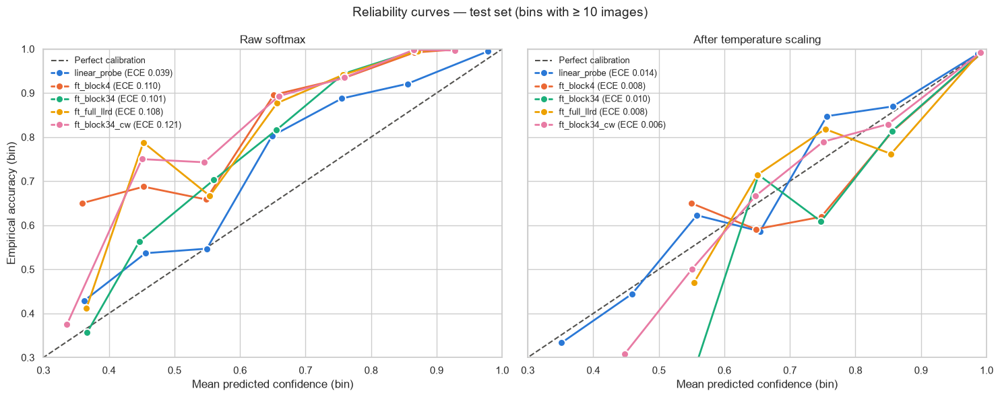

In [52]:
calib_rows = []
for name, rec in records.items():
    t = fit_temperature(rec["val"]["logits"], y_val)
    rec["temperature"] = t
    for split, y in (("val", y_val), ("test", y_test)):
        rec[split]["probs_ts"] = apply_temperature(rec[split]["logits"], t)
    p_raw, p_ts = rec["test"]["probs"], rec["test"]["probs_ts"]
    calib_rows.append({
        "experiment": name, "T (fit on val)": t,
        "val NLL raw": log_loss(y_val, rec["val"]["probs"], labels=np.arange(K)),
        "val NLL scaled": log_loss(y_val, rec["val"]["probs_ts"], labels=np.arange(K)),
        "test ECE raw": expected_calibration_error(y_test, p_raw),
        "test ECE scaled": expected_calibration_error(y_test, p_ts),
        "test log-loss raw": log_loss(y_test, p_raw, labels=np.arange(K)),
        "test log-loss scaled": log_loss(y_test, p_ts, labels=np.arange(K)),
        "test Brier raw": brier_score(y_test, p_raw),
        "test Brier scaled": brier_score(y_test, p_ts),
    })
calibration_df = pd.DataFrame(calib_rows).set_index("experiment")
display(calibration_df.style.format("{:.4f}").highlight_min(
    subset=["val NLL scaled", "test ECE scaled", "test log-loss scaled", "test Brier scaled"],
    props="font-weight: bold; background-color: #dbe9f9"))

# Axis range adapts to the data: lowest populated bin (>= 10 images) across models, rounded down to 0.1.
min_conf = min(calibration_table(y_test, rec["test"]["probs"], n_bins=10).query("count >= 10")["confidence"].min()
               for rec in records.values())
axis_lo = float(np.floor(min(min_conf, 0.5) * 10) / 10) if np.isfinite(min_conf) else 0.0

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, key, title in zip(axes, ["probs", "probs_ts"], ["Raw softmax", "After temperature scaling"]):
    ax.plot([0, 1], [0, 1], ls="--", color=NEUTRAL_COLOR, lw=1.5, label="Perfect calibration")
    for name, rec in records.items():
        probs = rec["test"][key]
        tab = calibration_table(y_test, probs, n_bins=10).query("count >= 10")  # hide nearly empty bins
        ax.plot(tab["confidence"], tab["accuracy"], marker="o", ms=8, lw=2, color=EXP_COLORS[name],
                mec="white", mew=1.5, label=f"{name} (ECE {expected_calibration_error(y_test, probs):.3f})")
    ax.set(xlim=(axis_lo, 1.0), ylim=(axis_lo, 1.0), xlabel="Mean predicted confidence (bin)", title=title)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
axes[0].set_ylabel("Empirical accuracy (bin)")
fig.suptitle("Reliability curves — test set (bins with ≥ 10 images)", fontsize=14)
fig.tight_layout()
save_cmp_figure(fig, "calibration")
plt.show()

### 12.4 Model selection (validation only)

On ~1.75 k validation images one image is worth ≈ 0.06 pp of accuracy, so a raw `argmax` over val macro-F1 can pick a winner by
noise. The rule is therefore:

1. **Rank** all runs by val macro-F1; the top one is the provisional winner.
2. **Tie check** — paired bootstrap (2,000 resamples of the val images) of Δ = F1(top) − F1(other). If the 95 % CI of Δ contains
   0, the two runs are *statistically tied*.
3. **Tie-break** — among the tied set, pick the lowest **temperature-scaled val NLL**. NLL is a strictly proper scoring rule
   that uses the entire probability vector of every image, so it separates models that differ by one or two argmax flips.
   Temperature scaling first removes the label-smoothing confidence offset, so the comparison is about *ranking quality*, not
   about a calibration artefact. The temperature is one scalar fitted on the same val set — identical, negligible optimism for
   every candidate.

All candidates share the same architecture, so inference cost is identical; "prefer the cheaper model" would only matter for
re-training cost and is reported, not used.

In [53]:
SELECTION_CI = 0.95
ranked = comparison_df["val macro-F1"].sort_values(ascending=False)
top_name = ranked.index[0]

sel_rows = []
for name in ranked.index:
    rec = records[name]
    if name == top_name:
        d, lo, hi, p_le0 = 0.0, 0.0, 0.0, float("nan")
        tied = True
    else:  # Δ = F1(top) - F1(name)
        d, lo, hi, p_le0 = paired_bootstrap_delta(y_val, rec["val"]["y_pred"], records[top_name]["val"]["y_pred"],
                                                  macro_f1_fn)
        tied = lo <= 0.0
    sel_rows.append({"experiment": name, "val macro-F1": ranked[name], "Δ to top (pp)": 100 * d,
                     "Δ CI low (pp)": 100 * lo, "Δ CI high (pp)": 100 * hi,
                     "tied with top": tied, "val NLL (T-scaled)": calibration_df.loc[name, "val NLL scaled"],
                     "trainable params (M)": rec["n_trainable"] / 1e6})
selection_df = pd.DataFrame(sel_rows).set_index("experiment")

candidates = selection_df[selection_df["tied with top"]]
best_name: str = candidates["val NLL (T-scaled)"].idxmin()
runner_up_name: str = comparison_df["val macro-F1"].drop(best_name).idxmax()
selection_df["selected"] = np.where(selection_df.index == best_name, "◀ selected", "")
comparison_df["selected"] = np.where(comparison_df.index == best_name, "◀ selected", "")

display(selection_df.style
        .format({"val macro-F1": "{:.4f}", "Δ to top (pp)": "{:+.2f}", "Δ CI low (pp)": "{:+.2f}",
                 "Δ CI high (pp)": "{:+.2f}", "val NLL (T-scaled)": "{:.4f}", "trainable params (M)": "{:.2f}"})
        .set_caption("Selection on validation: tie check by paired bootstrap, tie-break by temperature-scaled NLL"))

if len(candidates) == 1:
    print(f"Selected: {best_name} — its val macro-F1 lead over every other run is statistically supported (no tie).")
else:
    print(f"Statistically tied on val macro-F1: {list(candidates.index)}")
    print(f"Tie broken by temperature-scaled val NLL -> selected: {best_name} "
          f"(NLL {candidates.loc[best_name, 'val NLL (T-scaled)']:.4f})")
print(f"Runner-up (next best val macro-F1): {runner_up_name}")

,val macro-F1,Δ to top (pp),Δ CI low (pp),Δ CI high (pp),tied with top,val NLL (T-scaled),trainable params (M),selected
experiment,,,,,,,,
ft_full_llrd,0.9688,+0.00,+0.00,+0.00,True,0.1087,10.32,◀ selected
ft_block34,0.9647,+0.41,-0.10,+0.99,True,0.1114,9.92,
ft_block34_cw,0.9642,+0.46,-0.07,+1.06,True,0.1160,9.92,
ft_block4,0.9614,+0.74,-0.01,+1.50,True,0.1139,3.91,
linear_probe,0.9351,+3.37,+2.35,+4.43,False,0.1951,0.01,


Statistically tied on val macro-F1: ['ft_full_llrd', 'ft_block34', 'ft_block34_cw', 'ft_block4']
Tie broken by temperature-scaled val NLL -> selected: ft_full_llrd (NLL 0.1087)
Runner-up (next best val macro-F1): ft_block34


### 12.5 Macro-F1 per experiment

Hollow diamond = validation (selection metric), filled dot = test with its 95 % bootstrap CI. Overlapping test CIs mean the test
ranking alone is not reliable — the paired tests in 12.8 are the proper comparison.

C:\Users\User\AppData\Local\Temp\ipykernel_36212\1130180409.py:24: UserWarning: Glyph 9664 (\N{BLACK LEFT-POINTING TRIANGLE}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\User\AppData\Local\Temp\ipykernel_36212\4170583446.py:14: UserWarning: Glyph 9664 (\N{BLACK LEFT-POINTING TRIANGLE}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches="tight")
C:\venvs\torch_venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9664 (\N{BLACK LEFT-POINTING TRIANGLE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


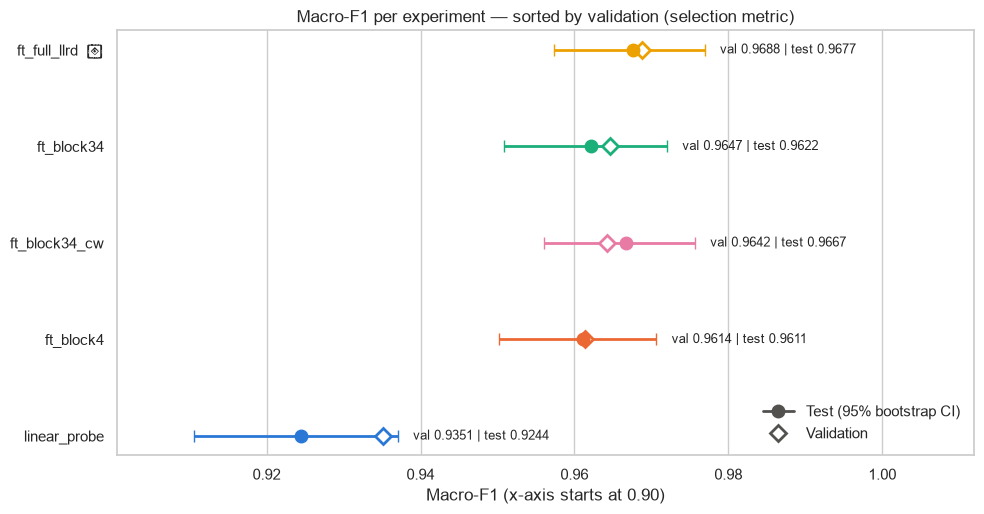

In [54]:
def plot_metric_dots(df: pd.DataFrame, colors: dict[str, str]) -> plt.Figure:
    order = df.sort_values("val macro-F1").index
    fig, ax = plt.subplots(figsize=(10, 0.7 * len(order) + 1.8))
    for y, name in enumerate(order):
        row = df.loc[name]
        ax.errorbar(row["test macro-F1"], y,
                    xerr=[[row["test macro-F1"] - row["test macro-F1 CI low"]],
                          [row["test macro-F1 CI high"] - row["test macro-F1"]]],
                    fmt="o", ms=9, color=colors[name], ecolor=colors[name], elinewidth=2, capsize=4)
        ax.plot(row["val macro-F1"], y, marker="D", ms=8, mfc="white", mec=colors[name], mew=2, ls="none")
        ax.text(max(row["test macro-F1 CI high"], row["val macro-F1"]) + 0.002, y,
                f"val {row['val macro-F1']:.4f} | test {row['test macro-F1']:.4f}", va="center", fontsize=9)
    ax.set_yticks(range(len(order)), [f"{n}  ◀" if n == best_name else n for n in order])
    lo = max(0.0, df["test macro-F1 CI low"].min() - 0.01)
    hi = max(df["test macro-F1 CI high"].max(), df["val macro-F1"].max()) + 0.035
    ax.set_xlim(lo, hi)
    ax.set_xlabel(f"Macro-F1 (x-axis starts at {lo:.2f})" if lo > 0 else "Macro-F1")
    ax.set_title("Macro-F1 per experiment — sorted by validation (selection metric)")
    ax.legend(handles=[
        plt.Line2D([], [], marker="o", ms=9, color=NEUTRAL_COLOR, ls="-", lw=2, label="Test (95% bootstrap CI)"),
        plt.Line2D([], [], marker="D", ms=8, mfc="white", mec=NEUTRAL_COLOR, mew=2, ls="none", label="Validation"),
    ], frameon=False, loc="lower right")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    return fig


fig = plot_metric_dots(comparison_df, EXP_COLORS)
save_cmp_figure(fig, "macro_f1_per_experiment")
plt.show()

### 12.6 Learning curves (stage 1 → stage 2)

Fine-tuning runs continue from the linear-probe checkpoint, so they are drawn **after** the baseline's epochs on a shared axis
(dashed line = start of stage 2, ★ = selected epoch). Validation loss is the plain cross-entropy for every run, so it *is*
comparable; training loss is not shown (label smoothing / class weights change its scale).

C:\Users\User\AppData\Local\Temp\ipykernel_36212\2127431201.py:26: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.tight_layout(rect=(0, 0.04, 1, 1))
C:\Users\User\AppData\Local\Temp\ipykernel_36212\4170583446.py:14: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches="tight")
C:\venvs\torch_venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


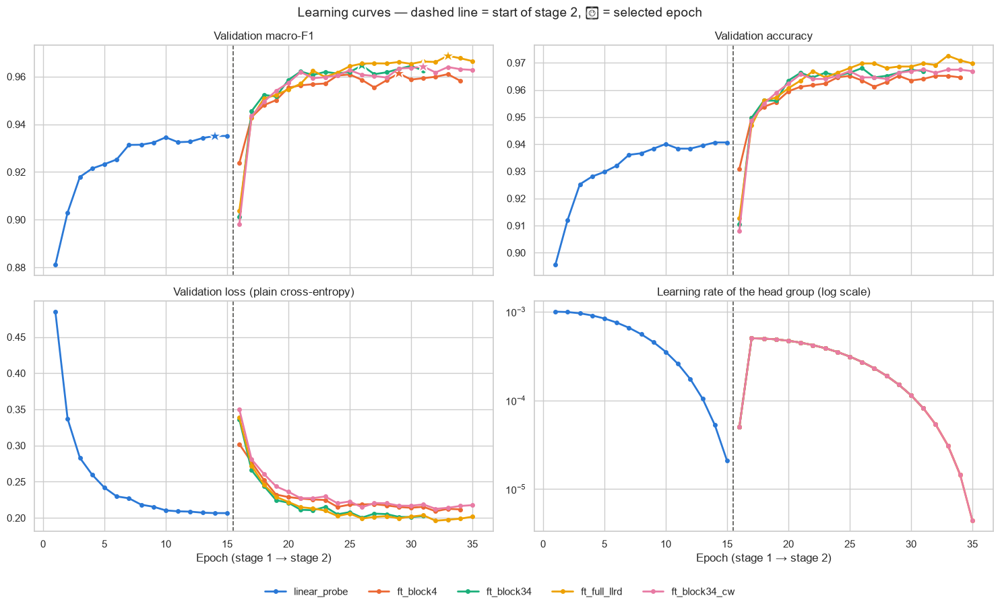

In [55]:
def plot_learning_curves(records: dict[str, dict], colors: dict[str, str]) -> plt.Figure:
    offset = len(records[BASELINE_NAME]["history"])
    fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
    panels = [(axes[0, 0], "val_macro_f1", "Validation macro-F1"),
              (axes[0, 1], "val_acc", "Validation accuracy"),
              (axes[1, 0], "val_loss", "Validation loss (plain cross-entropy)"),
              (axes[1, 1], "lr", "Learning rate of the head group (log scale)")]
    for name, rec in records.items():
        hist = rec["history"]
        start = 1 if name == BASELINE_NAME else offset + 1
        x = np.arange(start, start + len(hist))
        for ax, key, _ in panels:
            ax.plot(x, hist[key], color=colors[name], lw=2, marker="o", ms=4, label=name)
        best = int(hist["val_macro_f1"].to_numpy().argmax())
        axes[0, 0].plot(x[best], hist["val_macro_f1"].iloc[best], marker="*", ms=16, color=colors[name],
                        mec="white", mew=1.5, ls="none")
    for ax, _, title in panels:
        ax.axvline(offset + 0.5, ls="--", color=NEUTRAL_COLOR, lw=1.2)
        ax.set_title(title)
    axes[1, 1].set_yscale("log")
    for ax in axes[1]:
        ax.set_xlabel("Epoch (stage 1 → stage 2)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle("Learning curves — dashed line = start of stage 2, ★ = selected epoch", fontsize=14)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig


fig = plot_learning_curves(records, EXP_COLORS)
save_cmp_figure(fig, "learning_curves")
plt.show()

for name, rec in records.items():
    hist = rec["history"]
    best = int(hist.loc[hist["val_macro_f1"].idxmax(), "epoch"])
    if name != BASELINE_NAME and best == len(hist) and len(hist) == ALL_CONFIGS[name].epochs:
        print(f"⚠ {name}: best epoch is the last epoch of the budget -> it may still be improving.")

### 12.7 Per-class F1 and recall (test)

Left: absolute F1 per class and experiment. Right: change vs. the linear probe in percentage points — **blue = better,
red = worse**. Classes are sorted from weakest to strongest under the baseline, so the top rows answer *"did fine-tuning help
the weak classes?"*.

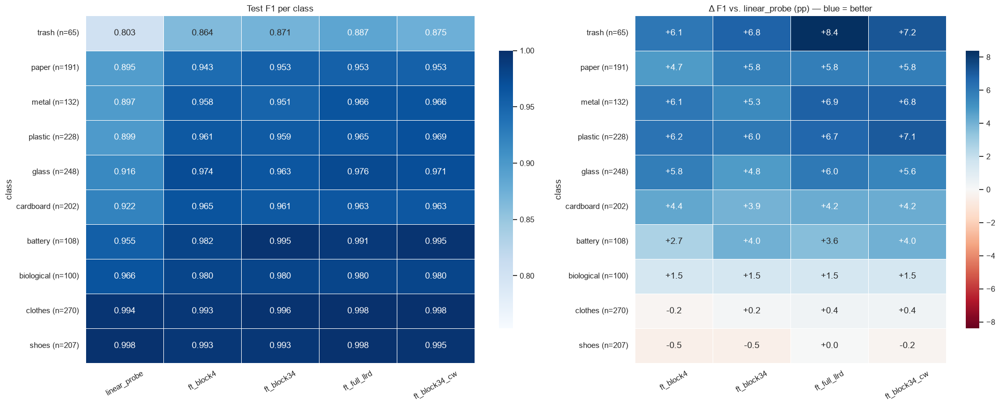

,linear_probe,ft_block4,ft_block34,ft_full_llrd,ft_block34_cw
class,,,,,
trash,0.785,0.831,0.831,0.846,0.862
paper,0.895,0.948,0.953,0.958,0.958
metal,0.894,0.947,0.947,0.970,0.962
plastic,0.895,0.965,0.965,0.974,0.974
glass,0.899,0.968,0.956,0.964,0.960
cardboard,0.931,0.965,0.975,0.970,0.970
battery,0.981,0.991,0.991,0.981,0.991
biological,0.980,0.990,0.990,0.990,0.990
clothes,0.996,0.993,0.993,1.000,0.996


In [56]:
def per_class_f1_table(records: dict[str, dict], split: str = "test") -> pd.DataFrame:
    table = {}
    for name, rec in records.items():
        _, _, f, _ = precision_recall_fscore_support(rec[split]["y_true"], rec[split]["y_pred"],
                                                     labels=np.arange(K), average=None, zero_division=0)
        table[name] = f
    return pd.DataFrame(table, index=pd.Index(classes, name="class"))


f1_table = per_class_f1_table(records).sort_values(BASELINE_NAME)
delta_pp = f1_table.drop(columns=BASELINE_NAME).sub(f1_table[BASELINE_NAME], axis=0) * 100
support = np.bincount(y_test, minlength=K)
ylabels = [f"{c} (n={support[class_to_idx[c]]})" for c in f1_table.index]

fig, axes = plt.subplots(1, 2, figsize=(20, 0.55 * K + 2.5),
                         gridspec_kw={"width_ratios": [len(records), len(records) - 1]})
sns.heatmap(f1_table, annot=True, fmt=".3f", cmap=SEQ_CMAP, vmin=max(0.0, f1_table.values.min() - 0.05), vmax=1.0,
            linewidths=0.5, linecolor="white", ax=axes[0], yticklabels=ylabels, cbar_kws={"shrink": 0.8})
lim = max(1.0, float(np.abs(delta_pp.values).max()))
sns.heatmap(delta_pp, annot=True, fmt="+.1f", cmap=DIVERGING_CMAP, center=0, vmin=-lim, vmax=lim,
            linewidths=0.5, linecolor="white", ax=axes[1], yticklabels=ylabels, cbar_kws={"shrink": 0.8})
axes[0].set_title("Test F1 per class")
axes[1].set_title(f"Δ F1 vs. {BASELINE_NAME} (pp) — blue = better")
for ax in axes:
    ax.grid(False)
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("")
fig.tight_layout()
save_cmp_figure(fig, "per_class_f1")
plt.show()

recall_table = pd.DataFrame(
    {name: np.diag(confusion_matrix(y_test, rec["test"]["y_pred"], labels=np.arange(K), normalize="true"))
     for name, rec in records.items()}, index=pd.Index(classes, name="class")
).loc[f1_table.index]
display(recall_table.style.format("{:.3f}").background_gradient(cmap=SEQ_CMAP, axis=1)
        .set_caption("Test recall per class (row-wise shading: best experiment per class is darkest)"))

### 12.8 Statistical significance on test

Two paired tests per comparison (same test images for every model):

* **Paired bootstrap of Δ macro-F1 / Δ accuracy** — 95 % CI and `P(Δ ≤ 0)`, the bootstrap probability that model *b* is not better.
* **Exact McNemar** on per-image correctness — only discordant images count: `fixed` (a wrong → b right) vs. `broken`.

Two families, each Holm-corrected (family-wise error 5 %): *every fine-tuned model vs. the baseline*, and *the selected model vs.
every other fine-tuned model*. The second family answers "is the winner really better than the alternatives?".

In [57]:
def compare_pair(name_a: str, name_b: str) -> dict:
    pa, pb = records[name_a]["test"]["y_pred"], records[name_b]["test"]["y_pred"]
    d_f1, lo, hi, p_not_better = paired_bootstrap_delta(y_test, pa, pb, macro_f1_fn)
    d_acc, acc_lo, acc_hi, _ = paired_bootstrap_delta(y_test, pa, pb, lambda t, p: float((t == p).mean()))
    fixed, broken, p_mc = mcnemar_exact(y_test, pa, pb)
    return {"comparison": f"{name_b} vs {name_a}", "Δ macro-F1 (pp)": 100 * d_f1,
            "Δ macro-F1 CI low": 100 * lo, "Δ macro-F1 CI high": 100 * hi, "P(Δ ≤ 0)": p_not_better,
            "Δ acc (pp)": 100 * d_acc, "Δ acc CI low": 100 * acc_lo, "Δ acc CI high": 100 * acc_hi,
            "fixed": fixed, "broken": broken, "McNemar p": p_mc}


def test_family(pairs: list[tuple[str, str]], family: str) -> pd.DataFrame:
    if not pairs:
        return pd.DataFrame()
    df = pd.DataFrame([compare_pair(a, b) for a, b in pairs])
    df["McNemar p (Holm)"] = holm_adjust(df["McNemar p"].tolist())
    df["significant (5%)"] = df["McNemar p (Holm)"] < 0.05
    df.insert(0, "family", family)
    return df


fine_tuned = [n for n in EXP_ORDER if n != BASELINE_NAME]
significance_df = pd.concat([
    test_family([(BASELINE_NAME, n) for n in fine_tuned], "vs baseline"),
    test_family([(n, best_name) for n in fine_tuned if n != best_name], "selected vs others"),
], ignore_index=True).set_index("comparison")

display(
    significance_df.style
    .format({c: "{:+.2f}" for c in significance_df.columns if c.startswith("Δ")})
    .format({"P(Δ ≤ 0)": "{:.3f}", "McNemar p": "{:.2e}", "McNemar p (Holm)": "{:.2e}"})
    .set_caption("Paired comparisons on the test set (pp = percentage points, Holm-corrected within each family)")
)

,family,Δ macro-F1 (pp),Δ macro-F1 CI low,Δ macro-F1 CI high,P(Δ ≤ 0),Δ acc (pp),Δ acc CI low,Δ acc CI high,fixed,broken,McNemar p,McNemar p (Holm),significant (5%)
comparison,,,,,,,,,,,,,
ft_block4 vs linear_probe,vs baseline,3.671352,2.595838,4.900865,0.000,3.483724,2.568532,4.511708,69,8,3.14e-13,6.27e-13,True
ft_block34 vs linear_probe,vs baseline,3.776973,2.736613,4.971987,0.000,3.483724,2.512850,4.511708,70,9,7.78e-13,7.78e-13,True
ft_full_llrd vs linear_probe,vs baseline,4.323749,3.262000,5.541584,0.000,3.997716,3.026842,5.082810,77,7,5.14e-16,2.06e-15,True
ft_block34_cw vs linear_probe,vs baseline,4.224428,3.160799,5.451733,0.000,3.940605,2.969732,5.025700,76,7,9.43e-16,2.83e-15,True
ft_full_llrd vs ft_block4,selected vs others,0.652397,-0.148598,1.460713,0.058,0.513992,-0.114220,1.086522,20,11,1.50e-01,2.99e-01,False
ft_full_llrd vs ft_block34,selected vs others,0.546775,0.088417,1.046669,0.006,0.513992,0.114220,0.970874,12,3,3.52e-02,1.05e-01,False
ft_full_llrd vs ft_block34_cw,selected vs others,0.099320,-0.364971,0.573482,0.320,0.057110,-0.342661,0.456882,6,5,1.00e+00,1.00e+00,False


### 12.9 Confusion matrices — selected model vs. baseline

Top: the selected model's confusion matrix. Bottom: **change in error counts** vs. the baseline, off-diagonal only —
**blue = fewer mistakes of that kind, red = more**. The table ranks the largest remaining confusions of both models.

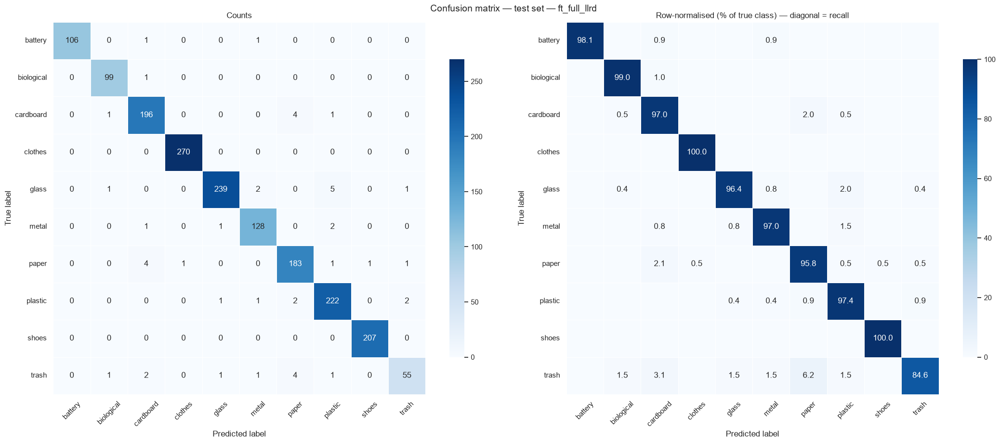

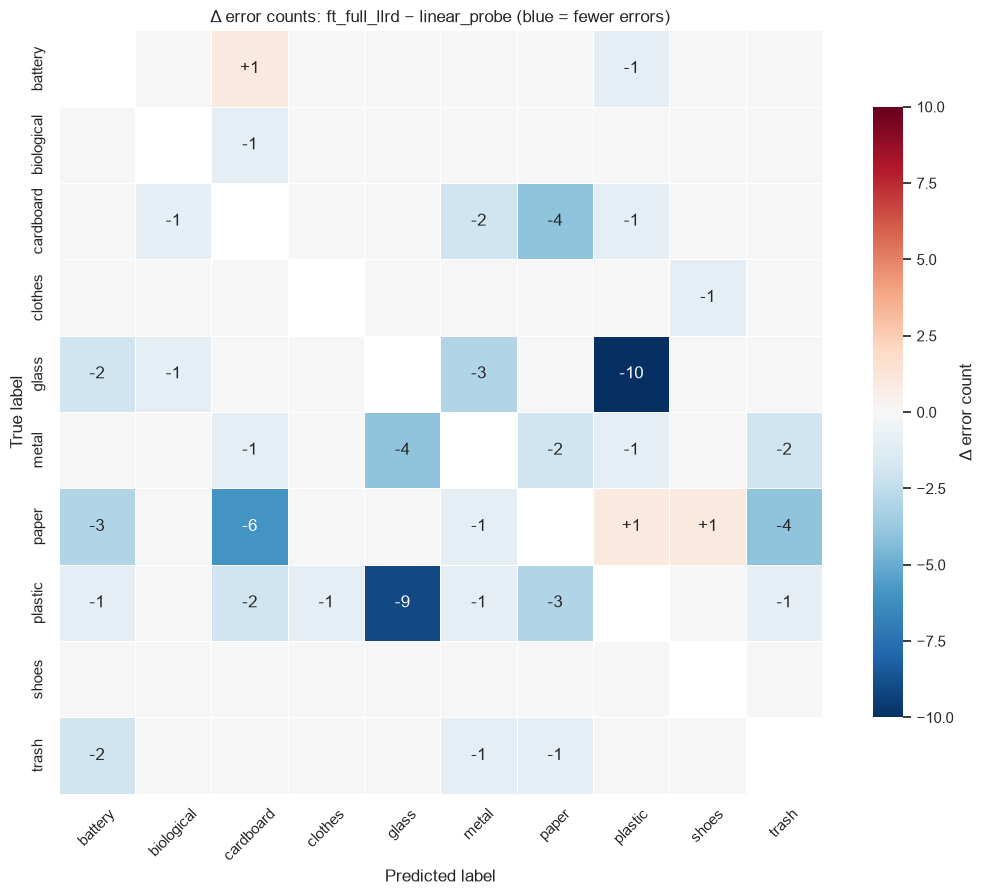

Total test errors: linear_probe = 116 | ft_full_llrd = 46


In [58]:
best_rec, base_rec = records[best_name], records[BASELINE_NAME]
best_cm = confusion_matrix(y_test, best_rec["test"]["y_pred"], labels=np.arange(K))
base_cm = confusion_matrix(y_test, base_rec["test"]["y_pred"], labels=np.arange(K))

fig = plot_confusion_matrices(best_cm, classes, f"Confusion matrix — test set — {best_name}")
save_cmp_figure(fig, "confusion_matrix_best")
plt.show()

err_delta = (best_cm - base_cm).astype(float)
np.fill_diagonal(err_delta, np.nan)
lim = max(1.0, float(np.nanmax(np.abs(err_delta))))
annot = np.where(np.nan_to_num(err_delta) != 0, np.char.mod("%+d", np.nan_to_num(err_delta).astype(int)), "")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(err_delta, annot=annot, fmt="", cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, square=True, linewidths=0.5,
            linecolor="white", xticklabels=classes, yticklabels=classes, ax=ax,
            cbar_kws={"shrink": 0.8, "label": "Δ error count"})
ax.set(xlabel="Predicted label", ylabel="True label",
       title=f"Δ error counts: {best_name} − {BASELINE_NAME} (blue = fewer errors)")
ax.tick_params(axis="x", rotation=45)
ax.grid(False)
fig.tight_layout()
save_cmp_figure(fig, "confusion_delta")
plt.show()

display(pd.concat({BASELINE_NAME: top_confusions(base_cm, classes, k=8),
                   best_name: top_confusions(best_cm, classes, k=8)}, axis=1).style.format(precision=1, na_rep=""))
print(f"Total test errors: {BASELINE_NAME} = {int(base_cm.sum() - np.trace(base_cm))} | "
      f"{best_name} = {int(best_cm.sum() - np.trace(best_cm))}")

### 12.10 Error overlap — what did fine-tuning change?

* **fixed** — baseline wrong, selected model right (the gain);
* **broken** — baseline right, selected model wrong (the regression; should be small);
* **still wrong** — both wrong. When both models agree on the *same* wrong class with high confidence, the label itself is the
  prime suspect — these are the images to review first (relabel in **train/val** data, never in test).

,test images
both correct,1628
fixed by fine-tuning,77
broken by fine-tuning,7
still wrong (same wrong class),27
still wrong (different wrong class),12


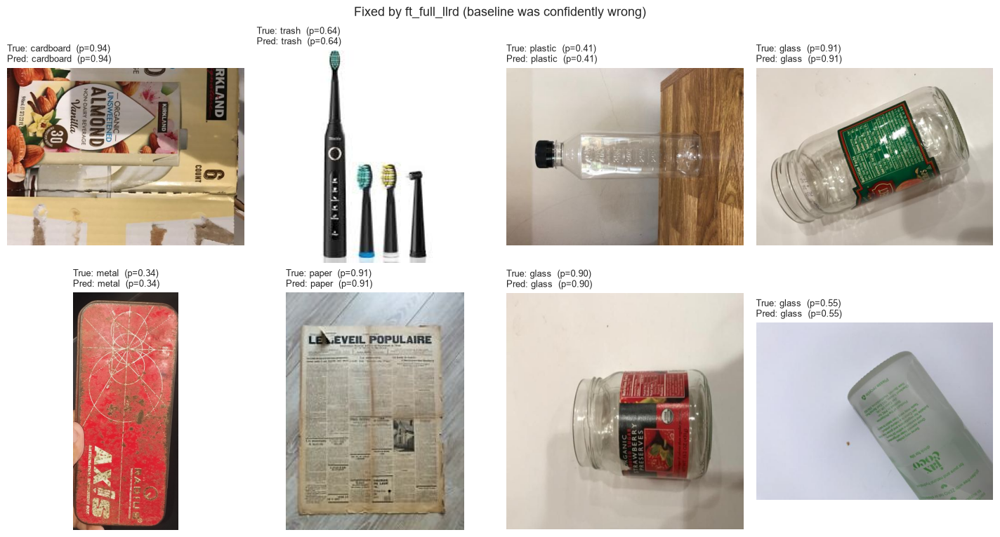

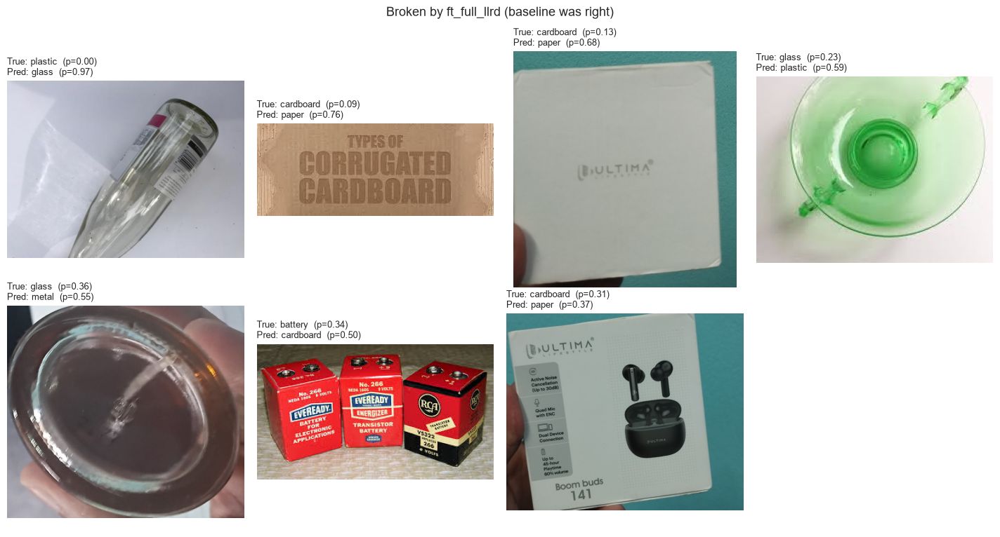

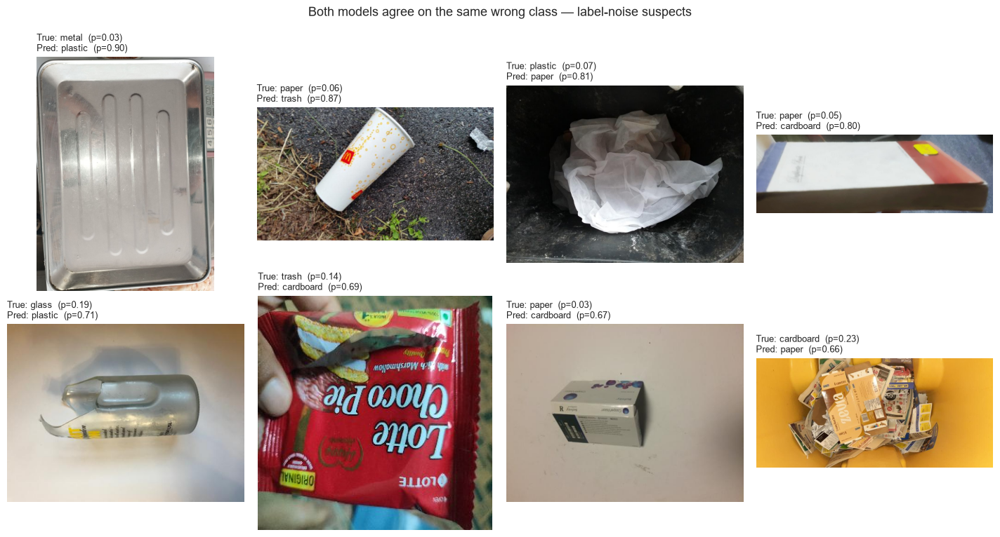

In [59]:
base_ok = base_rec["test"]["y_pred"] == y_test
best_ok = best_rec["test"]["y_pred"] == y_test
same_wrong = base_rec["test"]["y_pred"] == best_rec["test"]["y_pred"]
overlap = pd.Series({
    "both correct": int((base_ok & best_ok).sum()),
    "fixed by fine-tuning": int((~base_ok & best_ok).sum()),
    "broken by fine-tuning": int((base_ok & ~best_ok).sum()),
    "still wrong (same wrong class)": int((~base_ok & ~best_ok & same_wrong).sum()),
    "still wrong (different wrong class)": int((~base_ok & ~best_ok & ~same_wrong).sum()),
}, name="test images")
display(overlap.to_frame())

best_pred_cmp = build_prediction_frame(test_df, best_rec["test"], classes)
base_pred_cmp = build_prediction_frame(test_df, base_rec["test"], classes)
best_pred_cmp["baseline_pred"] = base_pred_cmp["pred"].to_numpy()
best_pred_cmp["baseline_conf"] = base_pred_cmp["confidence"].to_numpy()

for rows, title, fname in [
    (best_pred_cmp[~base_ok & best_ok].sort_values("baseline_conf", ascending=False).head(8),
     f"Fixed by {best_name} (baseline was confidently wrong)", "fixed_examples"),
    (best_pred_cmp[base_ok & ~best_ok].sort_values("confidence", ascending=False).head(8),
     f"Broken by {best_name} (baseline was right)", "broken_examples"),
    (best_pred_cmp[~base_ok & ~best_ok & same_wrong].sort_values("confidence", ascending=False).head(8),
     "Both models agree on the same wrong class — label-noise suspects", "label_noise_suspects"),
]:
    fig = show_prediction_grid(rows, title)
    if fig is not None:
        save_cmp_figure(fig, fname)
        plt.show()

### 12.11 Export comparison artifacts

Written to `reports/comparison/`:

| File | Content |
|------|---------|
| `comparison.csv` | Summary table (12.2) |
| `selection.csv` | Selection table with tie check and tie-break (12.4) |
| `calibration.csv` | Temperatures, NLL / ECE / log-loss / Brier before and after scaling (12.3) |
| `per_class_f1_test.csv`, `per_class_recall_test.csv` | Per-class tables (12.7) |
| `significance_test.csv` | Paired bootstrap + McNemar results (12.8) |
| `predictions_test_best.csv` | Per-image predictions of the selected model incl. the baseline prediction (12.10) |
| `summary.json` | Selected model, runner-up, selection rule, all configs and metrics |
| `*.png` | All comparison figures |

In [60]:
comparison_df.to_csv(COMPARE_DIR / "comparison.csv")
selection_df.to_csv(COMPARE_DIR / "selection.csv")
calibration_df.to_csv(COMPARE_DIR / "calibration.csv")
f1_table.to_csv(COMPARE_DIR / "per_class_f1_test.csv")
recall_table.to_csv(COMPARE_DIR / "per_class_recall_test.csv")
significance_df.to_csv(COMPARE_DIR / "significance_test.csv")
to_relative(best_pred_cmp, DATA_DIR).to_csv(COMPARE_DIR / "predictions_test_best.csv", index=False)

comparison_summary = {
    "selected_model": best_name,
    "runner_up": runner_up_name,
    "selection_rule": "max val macro-F1; statistical ties (paired bootstrap 95% CI of delta contains 0) "
                      "broken by min temperature-scaled val NLL",
    "tied_candidates": list(candidates.index),
    "checkpoint": records[best_name]["meta"]["checkpoint"],
    "temperature": records[best_name]["temperature"],
    "classes": classes,
    "experiments": {n: config_as_json(c) for n, c in ALL_CONFIGS.items()},
    "comparison": comparison_df.drop(columns="selected").to_dict(orient="index"),
    "significance_test": significance_df.to_dict(orient="index"),
}
(COMPARE_DIR / "summary.json").write_text(json.dumps(comparison_summary, indent=2, default=float))
print(f"Artifacts written to {COMPARE_DIR}:")
for p in sorted(COMPARE_DIR.iterdir()):
    print("  ", p.name)

Artifacts written to C:\Users\User\Projects\DL_Learning\reports\comparison:
   broken_examples.png
   calibration.csv
   calibration.png
   comparison.csv
   confusion_delta.png
   confusion_matrix_best.png
   fixed_examples.png
   label_noise_suspects.png
   learning_curves.png
   macro_f1_per_experiment.png
   misclassified_test_best.csv
   per_class_f1.png
   per_class_f1_test.csv
   per_class_recall_test.csv
   predictions_test_best.csv
   selection.csv
   significance_test.csv
   summary.json


## 13. In-depth evaluation of the selected model

Section 12 answered *which* model; this section answers *how good, where, why and how robust*. The baseline is shown alongside
wherever a reference point makes a number interpretable.

| # | Analysis | Question |
|---|----------|----------|
| 13.1 | Final inference recipe | TTA on/off (decided on val), temperature |
| 13.2 | Headline metrics + bootstrap CIs | How good, and how certain are we? |
| 13.3 | Per-class precision / recall / F1 with CIs | Which classes are weak, and is the gap real? |
| 13.4 | Confusion matrix | What is confused with what? |
| 13.5 | Per-class ROC and precision–recall curves | Ranking quality per class, independent of argmax |
| 13.6 | Calibration | Can the probabilities be used as confidences? |
| 13.7 | Selective prediction (risk–coverage) | How many items must go to manual review for 98 / 99 % accuracy? |
| 13.8 | Top-k accuracy | Is the true class at least among the suggestions? |
| 13.9 | Error analysis | What do the remaining mistakes look like? Geometry effects? |
| 13.10 | Grad-CAM | Does the model look at the object or at context? |
| 13.11 | Embedding space | How did fine-tuning reorganise the features? |
| 13.12 | Robustness to corruptions | Blur, noise, low light, contrast, JPEG, low resolution, rotation |
| 13.13 | Efficiency | Latency and throughput (fp32 / bf16) |
| 13.14 | Export | Deployable bundle + all evaluation artifacts |

**Caching.** Metrics come from the stored logits. Analyses that need the network (Grad-CAM, embeddings, robustness, latency)
store their results under `reports/best_model/cache/<model>_<checkpoint-md5>/`; the model is only built when a cache file is
missing, so re-running the section is instant and never retrains anything. `FORCE_RECOMPUTE = True` refreshes the caches.

In [61]:
EVAL_DIR = PROJECT_DIR / "reports" / "best_model"
FORCE_RECOMPUTE = False  # True -> recompute every model-dependent cache in this section

best_rec, base_rec = records[best_name], records[BASELINE_NAME]
CACHE_DIR = EVAL_DIR / "cache" / f"{best_name}_{file_md5(best_rec['ckpt'])[:8]}"  # invalidated if the checkpoint changes
CACHE_DIR.mkdir(parents=True, exist_ok=True)
BEST_COLOR, BASE_COLOR = EXP_COLORS[best_name], EXP_COLORS[BASELINE_NAME]
print(f"Selected model: {best_name} — {best_rec['description']} | checkpoint: {best_rec['meta']['checkpoint']}")


def save_eval_figure(fig: plt.Figure, name: str) -> Path:
    path = EVAL_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


def cached_npz(name: str, compute: Callable[[], dict[str, np.ndarray]]) -> dict[str, np.ndarray]:
    path = CACHE_DIR / f"{name}.npz"
    if path.exists() and not FORCE_RECOMPUTE:
        with np.load(path) as f:
            return {k: f[k] for k in f.files}
    arrays = compute()
    np.savez_compressed(path, **arrays)
    return arrays


def cached_frame(name: str, compute: Callable[[], pd.DataFrame]) -> pd.DataFrame:
    path = CACHE_DIR / f"{name}.csv"
    if path.exists() and not FORCE_RECOMPUTE:
        return pd.read_csv(path)
    frame = compute()
    frame.to_csv(path, index=False)
    return frame


_models: dict[str, nn.Module] = {}


def get_model(name: str) -> nn.Module:
    """Built lazily — only when a cache below is missing."""
    if name not in _models:
        _models[name] = build_model(classes, records[name]["ckpt"]).eval()
    return _models[name]


# Deterministic eval preprocessing as uint8 (exactly what `eval_tf` does before normalisation).
CROP = eval_tf.crop_size[0]
clean_uint8_tf = T.Compose([T.Resize(eval_tf.resize_size, interpolation=eval_tf.interpolation, antialias=True),
                            T.CenterCrop(eval_tf.crop_size), T.PILToTensor()])
_EVAL_MEAN = torch.tensor(eval_tf.mean).view(1, 3, 1, 1)
_EVAL_STD = torch.tensor(eval_tf.std).view(1, 3, 1, 1)


def normalize_batch(x01: torch.Tensor) -> torch.Tensor:
    """[0, 1] float batch on any device -> model input."""
    return (x01 - _EVAL_MEAN.to(x01.device)) / _EVAL_STD.to(x01.device)


def load_clean_uint8(paths: list[str]) -> torch.Tensor:
    imgs = []
    for p in paths:
        with Image.open(p) as im:
            imgs.append(clean_uint8_tf(im.convert("RGB")))
    return torch.stack(imgs)


def clean_split_uint8(frame: pd.DataFrame) -> torch.Tensor:
    """Whole split as a uint8 tensor (N, 3, 224, 224), loaded in parallel workers."""
    dl = DataLoader(GarbageDataset(frame, clean_uint8_tf), batch_size=128, shuffle=False, **eval_kwargs)
    return torch.cat([x for x, _ in dl])

Selected model: ft_full_llrd — Full fine-tuning, layer-wise LR decay | checkpoint: experiments/ft_full_llrd/best.pt


### 13.1 Final inference recipe — TTA and temperature

Both decisions are made on **validation** from the stored logits (mirror logits were saved in Section 11), so no inference is
needed. Horizontal-flip TTA doubles inference cost, so it is adopted only if its val macro-F1 gain is **statistically supported**
(paired bootstrap, `P(Δ ≤ 0) < 0.05`); a gain of one or two images is noise and does not justify the cost. The temperature is then
refitted on the final (TTA or plain) val logits.

In [62]:
def final_logits(rec: dict, split: str, tta: bool) -> np.ndarray:
    s = rec[split]
    return 0.5 * (s["logits"] + s["logits_hflip"]) if tta else s["logits"]


tta_d, tta_lo, tta_hi, tta_p = paired_bootstrap_delta(
    y_val, best_rec["val"]["y_pred"], final_logits(best_rec, "val", True).argmax(axis=1), macro_f1_fn)
use_tta = tta_p < 0.05
print(f"hflip TTA on val: Δ macro-F1 {100 * tta_d:+.2f} pp, 95% CI [{100 * tta_lo:+.2f}, {100 * tta_hi:+.2f}], "
      f"P(Δ ≤ 0) = {tta_p:.3f}  ->  use TTA: {use_tta}")

T_final = fit_temperature(final_logits(best_rec, "val", use_tta), y_val)
print(f"Temperature (fit on val{' + TTA' if use_tta else ''}): T = {T_final:.4f} "
      f"({'under' if T_final < 1 else 'over'}-confident raw model)")

final: dict[str, dict[str, np.ndarray]] = {}   # selected model, final recipe
base_final: dict[str, dict[str, np.ndarray]] = {}  # baseline, temperature-scaled, no TTA
for split, y in (("val", y_val), ("test", y_test)):
    logits = final_logits(best_rec, split, use_tta)
    final[split] = {"y_true": y, "logits": logits, "y_pred": logits.argmax(axis=1),
                    "probs_raw": softmax_np(logits), "probs": apply_temperature(logits, T_final)}
    base_final[split] = {"y_true": y, "y_pred": base_rec[split]["y_pred"],
                         "probs_raw": base_rec[split]["probs"], "probs": base_rec[split]["probs_ts"]}

hflip TTA on val: Δ macro-F1 -0.13 pp, 95% CI [-0.59, +0.29], P(Δ ≤ 0) = 0.728  ->  use TTA: False
Temperature (fit on val): T = 0.5847 (under-confident raw model)


### 13.2 Headline metrics with bootstrap confidence intervals

All label-based metrics are derived from a **confusion matrix per bootstrap resample** (2,000 resamples of the test images),
so every CI is computed from the same resamples and stays mutually consistent. The derivation is checked against scikit-learn.

MCC and Cohen's κ use their multi-class definitions; balanced accuracy is the mean per-class recall.

,validation,test,test CI low,test CI high,linear_probe test,Δ vs baseline (pp)
accuracy,0.972603,0.973729,0.966305,0.980583,0.933752,+4.00
balanced_accuracy,0.968398,0.965314,0.953798,0.975727,0.925624,+3.97
macro_precision,0.969290,0.970548,0.960401,0.979602,0.923606,+4.69
macro_recall,0.968398,0.965314,0.953798,0.975727,0.925624,+3.97
macro_f1,0.968777,0.967673,0.957106,0.977017,0.924435,+4.32
weighted_f1,0.972603,0.973609,0.965921,0.980564,0.933479,+4.01
mcc,0.969090,0.970359,0.961931,0.978127,0.925268,+4.51
cohen_kappa,0.969076,0.970339,0.961890,0.978107,0.925241,+4.51


,validation,test,linear_probe test
log-loss (raw),0.1975,0.1935,0.2139
log-loss (T-scaled),0.1087,0.0988,0.1997
ECE (raw),0.1042,0.1077,0.0390
ECE (T-scaled),0.0053,0.0079,0.0144
Brier (T-scaled),0.0458,0.0421,0.0981
top-3 accuracy,0.9949,0.9937,0.9920
"ROC-AUC (OvR, macro)",0.9985,0.9988,0.9962
mean average precision,0.9922,0.9903,0.9704


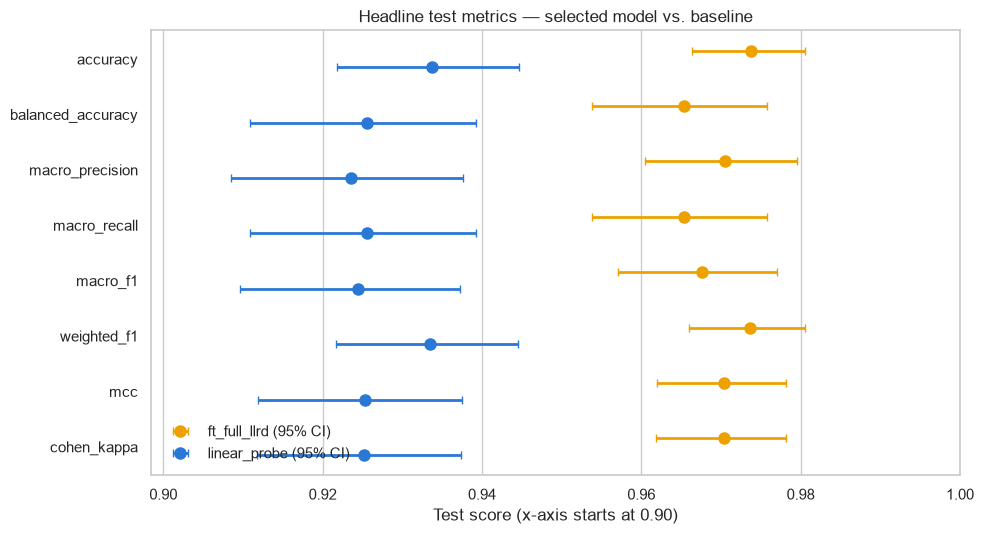

In [63]:
N_BOOT = 2000


def bootstrap_confusions(y_true: np.ndarray, y_pred: np.ndarray, n_boot: int = N_BOOT, seed: int = SEED) -> np.ndarray:
    """(n_boot, K, K) confusion matrices of image-level bootstrap resamples."""
    rng = np.random.default_rng(seed)
    n, codes = len(y_true), K * y_true + y_pred
    cms = np.empty((n_boot, K * K), dtype=np.int64)
    for b in range(n_boot):
        cms[b] = np.bincount(codes[rng.integers(0, n, n)], minlength=K * K)
    return cms.reshape(n_boot, K, K)


def per_class_from_cm(cm: np.ndarray) -> dict[str, np.ndarray]:
    """Per-class precision / recall / F1 from (..., K, K) confusion matrices (rows = true)."""
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(float)
    support, predicted = cm.sum(axis=-1).astype(float), cm.sum(axis=-2).astype(float)
    safe = lambda a, b: np.divide(a, b, out=np.zeros_like(a), where=b > 0)  # noqa: E731
    return {"precision": safe(tp, predicted), "recall": safe(tp, support), "f1": safe(2 * tp, support + predicted),
            "support": support}


def metrics_from_cm(cm: np.ndarray) -> dict[str, np.ndarray]:
    """Global label-based metrics from (..., K, K) confusion matrices."""
    pc = per_class_from_cm(cm)
    n = cm.sum(axis=(-2, -1)).astype(float)
    c = np.trace(cm, axis1=-2, axis2=-1).astype(float)
    t, p = pc["support"], cm.sum(axis=-2).astype(float)
    tp_sum = (t * p).sum(axis=-1)
    mcc_den = np.sqrt((n ** 2 - (p ** 2).sum(axis=-1)) * (n ** 2 - (t ** 2).sum(axis=-1)))
    pe = tp_sum / n ** 2
    return {
        "accuracy": c / n,
        "balanced_accuracy": pc["recall"].mean(axis=-1),
        "macro_precision": pc["precision"].mean(axis=-1),
        "macro_recall": pc["recall"].mean(axis=-1),
        "macro_f1": pc["f1"].mean(axis=-1),
        "weighted_f1": (pc["f1"] * t).sum(axis=-1) / n,
        "mcc": np.divide(c * n - tp_sum, mcc_den, out=np.zeros_like(c), where=mcc_den > 0),
        "cohen_kappa": (c / n - pe) / (1 - pe),
    }


cm_val = confusion_matrix(y_val, final["val"]["y_pred"], labels=np.arange(K))
cm_test = confusion_matrix(y_test, final["test"]["y_pred"], labels=np.arange(K))
cm_test_base = confusion_matrix(y_test, base_final["test"]["y_pred"], labels=np.arange(K))

# Consistency check against scikit-learn.
_m = metrics_from_cm(cm_test)
assert np.isclose(_m["accuracy"], accuracy_score(y_test, final["test"]["y_pred"]))
assert np.isclose(_m["macro_f1"], f1_score(y_test, final["test"]["y_pred"], average="macro"))
assert np.isclose(_m["mcc"], matthews_corrcoef(y_test, final["test"]["y_pred"]))
assert np.isclose(_m["cohen_kappa"], cohen_kappa_score(y_test, final["test"]["y_pred"]))

boot_test = bootstrap_confusions(y_test, final["test"]["y_pred"])
boot_test_base = bootstrap_confusions(y_test, base_final["test"]["y_pred"])
boot_m, boot_m_base = metrics_from_cm(boot_test), metrics_from_cm(boot_test_base)

def as_floats(metrics: dict) -> dict[str, float]:
    return {k: float(v) for k, v in metrics.items()}


headline_df = pd.DataFrame({
    "validation": as_floats(metrics_from_cm(cm_val)),
    "test": as_floats(metrics_from_cm(cm_test)),
    "test CI low": {k: np.quantile(v, 0.025) for k, v in boot_m.items()},
    "test CI high": {k: np.quantile(v, 0.975) for k, v in boot_m.items()},
    f"{BASELINE_NAME} test": as_floats(metrics_from_cm(cm_test_base)),
}).astype(float)
headline_df["Δ vs baseline (pp)"] = 100 * (headline_df["test"] - headline_df[f"{BASELINE_NAME} test"])
display(headline_df.style.format("{:.4f}").format({"Δ vs baseline (pp)": "{:+.2f}"})
        .set_caption(f"{best_name}{' + hflip TTA' if use_tta else ''} — label-based metrics, test 95% bootstrap CI"))


def probability_metrics(res: dict) -> dict[str, float]:
    y, p_raw, p = res["y_true"], res["probs_raw"], res["probs"]
    labels = np.arange(K)
    return {
        "log-loss (raw)": log_loss(y, p_raw, labels=labels),
        "log-loss (T-scaled)": log_loss(y, p, labels=labels),
        "ECE (raw)": expected_calibration_error(y, p_raw),
        "ECE (T-scaled)": expected_calibration_error(y, p),
        "Brier (T-scaled)": brier_score(y, p),
        "top-3 accuracy": top_k_accuracy_score(y, p, k=3, labels=labels),
        "ROC-AUC (OvR, macro)": roc_auc_score(y, p, multi_class="ovr", average="macro", labels=labels),
        "mean average precision": float(np.mean([average_precision_score(y == k, p[:, k]) for k in labels])),
    }


prob_df = pd.DataFrame({"validation": probability_metrics(final["val"]), "test": probability_metrics(final["test"]),
                        f"{BASELINE_NAME} test": probability_metrics(base_final["test"])})
display(prob_df.style.format("{:.4f}").set_caption("Probability-based metrics"))

# Visual summary: test estimate with CI for both models (shared 0-1 scale -> one axis is legitimate).
show = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "mcc", "cohen_kappa"]
fig, ax = plt.subplots(figsize=(10, 5.5))
for offset, (name, cm, bm, color) in zip([-0.15, 0.15], [(best_name, cm_test, boot_m, BEST_COLOR),
                                                          (BASELINE_NAME, cm_test_base, boot_m_base, BASE_COLOR)]):
    point = metrics_from_cm(cm)
    est = np.array([point[m] for m in show], dtype=float)
    lo = np.array([np.quantile(bm[m], 0.025) for m in show])
    hi = np.array([np.quantile(bm[m], 0.975) for m in show])
    y_pos = np.arange(len(show)) + offset
    ax.errorbar(est, y_pos, xerr=[est - lo, hi - est], fmt="o", ms=8, color=color, elinewidth=2, capsize=3,
                label=f"{name} (95% CI)")
ax.set_yticks(np.arange(len(show)), show)
ax.invert_yaxis()
lo_lim = max(0.0, min(np.quantile(boot_m_base[m], 0.025) for m in show) - 0.01)
ax.set_xlim(lo_lim, 1.0)
ax.set_xlabel(f"Test score (x-axis starts at {lo_lim:.2f})")
ax.set_title("Headline test metrics — selected model vs. baseline")
ax.legend(frameon=False, loc="lower left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_eval_figure(fig, "headline_metrics")
plt.show()

### 13.3 Per-class precision, recall and F1 with confidence intervals

For a sorting line, low **recall** on a hazardous class (*battery*) is the costlier failure, while low **precision** on a
recyclable class contaminates that stream. The CIs show which per-class gaps are real: with only ~65 test images of *trash*, its
interval is several times wider than that of *clothes*. Hollow markers = baseline point estimate.

,support,precision,precision CI,Δ precision vs baseline (pp),recall,recall CI,Δ recall vs baseline (pp),f1,f1 CI,Δ f1 vs baseline (pp),missed (FN),false alarms (FP)
class,,,,,,,,,,,,
trash,65,0.932203,"[0.862, 0.985]",+11.0,0.846154,"[0.754, 0.929]",+6.2,0.887097,"[0.821, 0.941]",+8.4,10,4
paper,191,0.948187,"[0.916, 0.977]",+5.3,0.958115,"[0.927, 0.984]",+6.3,0.953125,"[0.929, 0.973]",+5.8,8,10
cardboard,202,0.956098,"[0.926, 0.981]",+4.3,0.970297,"[0.945, 0.991]",+4.0,0.963145,"[0.944, 0.980]",+4.2,6,9
plastic,228,0.956897,"[0.927, 0.980]",+5.4,0.973684,"[0.950, 0.992]",+7.9,0.965217,"[0.947, 0.981]",+6.7,6,10
metal,132,0.962406,"[0.928, 0.992]",+6.2,0.969697,"[0.939, 0.993]",+7.6,0.966038,"[0.943, 0.985]",+6.9,4,5
glass,248,0.987603,"[0.972, 1.000]",+5.5,0.963710,"[0.938, 0.984]",+6.5,0.975510,"[0.960, 0.988]",+6.0,9,3
biological,100,0.970588,"[0.935, 1.000]",+1.9,0.990000,"[0.967, 1.000]",+1.0,0.980198,"[0.959, 0.996]",+1.5,1,3
battery,108,1.000000,"[1.000, 1.000]",+7.0,0.981481,"[0.951, 1.000]",+0.0,0.990654,"[0.975, 1.000]",+3.6,2,0
shoes,207,0.995192,"[0.984, 1.000]",+0.0,1.000000,"[1.000, 1.000]",+0.0,0.997590,"[0.992, 1.000]",+0.0,0,1


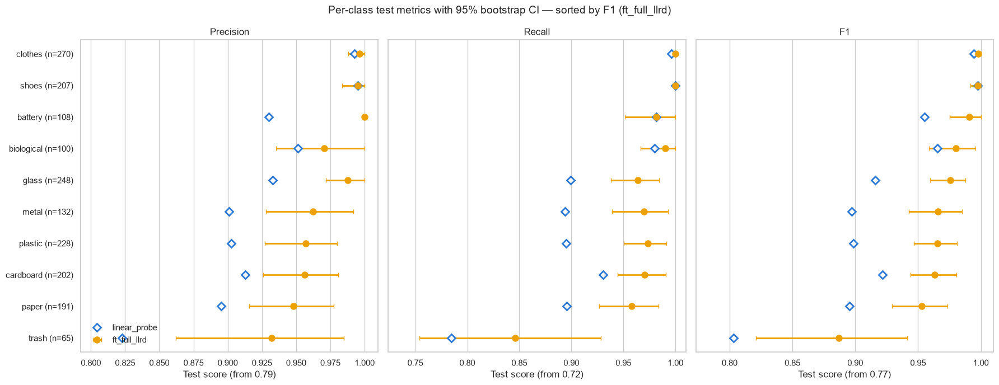

              precision    recall  f1-score   support

     battery     1.0000    0.9815    0.9907       108
  biological     0.9706    0.9900    0.9802       100
   cardboard     0.9561    0.9703    0.9631       202
     clothes     0.9963    1.0000    0.9982       270
       glass     0.9876    0.9637    0.9755       248
       metal     0.9624    0.9697    0.9660       132
       paper     0.9482    0.9581    0.9531       191
     plastic     0.9569    0.9737    0.9652       228
       shoes     0.9952    1.0000    0.9976       207
       trash     0.9322    0.8462    0.8871        65

    accuracy                         0.9737      1751
   macro avg     0.9705    0.9653    0.9677      1751
weighted avg     0.9737    0.9737    0.9736      1751



In [64]:
pc_point, pc_base = per_class_from_cm(cm_test), per_class_from_cm(cm_test_base)
pc_boot = per_class_from_cm(boot_test)

rows = []
for k, c in enumerate(classes):
    row = {"class": c, "support": int(pc_point["support"][k])}
    for m in ("precision", "recall", "f1"):
        row[m] = pc_point[m][k]
        row[f"{m} CI"] = f"[{np.quantile(pc_boot[m][:, k], 0.025):.3f}, {np.quantile(pc_boot[m][:, k], 0.975):.3f}]"
        row[f"Δ {m} vs baseline (pp)"] = 100 * (pc_point[m][k] - pc_base[m][k])
    row["missed (FN)"] = int(cm_test[k].sum() - cm_test[k, k])
    row["false alarms (FP)"] = int(cm_test[:, k].sum() - cm_test[k, k])
    rows.append(row)
per_class_df = pd.DataFrame(rows).set_index("class").sort_values("f1")
display(per_class_df.style
        .format({m: "{:.3f}" for m in ("precision", "recall", "f1")})
        .format({c: "{:+.1f}" for c in per_class_df.columns if c.startswith("Δ")})
        .background_gradient(subset=["f1"], cmap=SEQ_CMAP)
        .set_caption(f"{best_name} — per-class test metrics, 95% bootstrap CI"))

order = per_class_df.index.tolist()
idx = [class_to_idx[c] for c in order]
fig, axes = plt.subplots(1, 3, figsize=(18, 0.5 * K + 2), sharey=True)
for ax, m in zip(axes, ("precision", "recall", "f1")):
    est = pc_point[m][idx]
    lo = np.quantile(pc_boot[m][:, idx], 0.025, axis=0)
    hi = np.quantile(pc_boot[m][:, idx], 0.975, axis=0)
    ax.errorbar(est, np.arange(K), xerr=[est - lo, hi - est], fmt="o", ms=8, color=BEST_COLOR, elinewidth=2,
                capsize=3, label=best_name)
    ax.plot(pc_base[m][idx], np.arange(K), marker="D", ms=7, mfc="white", mec=BASE_COLOR, mew=2, ls="none",
            label=BASELINE_NAME)
    ax.set_title(m.capitalize() if m != "f1" else "F1")
    lo_lim = max(0.0, min(lo.min(), pc_base[m][idx].min()) - 0.03)
    ax.set_xlim(lo_lim, 1.01)
    ax.set_xlabel(f"Test score (from {lo_lim:.2f})")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(K), [f"{c} (n={int(pc_point['support'][class_to_idx[c]])})" for c in order])
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle(f"Per-class test metrics with 95% bootstrap CI — sorted by F1 ({best_name})", fontsize=14)
fig.tight_layout()
save_eval_figure(fig, "per_class_metrics_ci")
plt.show()

print(classification_report(y_test, final["test"]["y_pred"], labels=np.arange(K), target_names=classes, digits=4,
                            zero_division=0))

### 13.4 Confusion matrix

Counts (operational cost) and row-normalised percentages (diagonal = recall), followed by the largest remaining confusions.

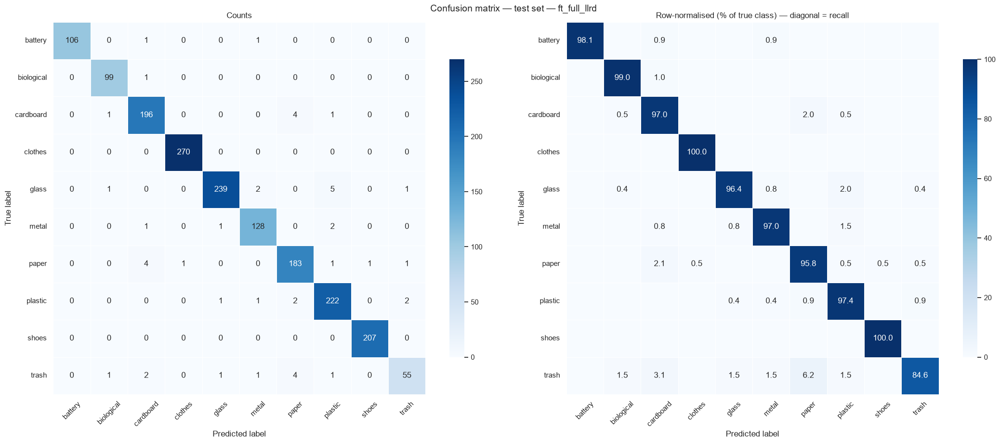

,true,predicted,count,% of true class
0,glass,plastic,5,2.0
1,cardboard,paper,4,2.0
2,trash,paper,4,6.2
3,paper,cardboard,4,2.1
4,metal,plastic,2,1.5
5,plastic,paper,2,0.9
6,trash,cardboard,2,3.1
7,plastic,trash,2,0.9
8,glass,metal,2,0.8
9,biological,cardboard,1,1.0


In [65]:
fig = plot_confusion_matrices(cm_test, classes, f"Confusion matrix — test set — {best_name}")
save_eval_figure(fig, "confusion_matrix_test")
plt.show()
display(top_confusions(cm_test, classes, k=10).style.format({"% of true class": "{:.1f}"}))

### 13.5 Per-class ROC and precision–recall curves

One-vs-rest, one panel per class (small multiples — ten overlaid curves would be unreadable). Precision–recall is the more
informative view under class imbalance: a weak minority class shows up as a PR curve that bends early, while its ROC curve can
still look near-perfect. ROC uses a log-scaled false-positive axis to make the differences in the low-FPR region visible.

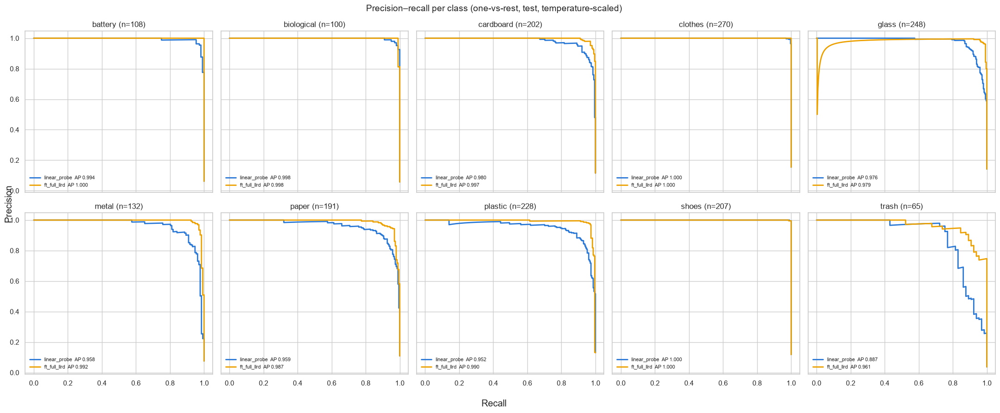

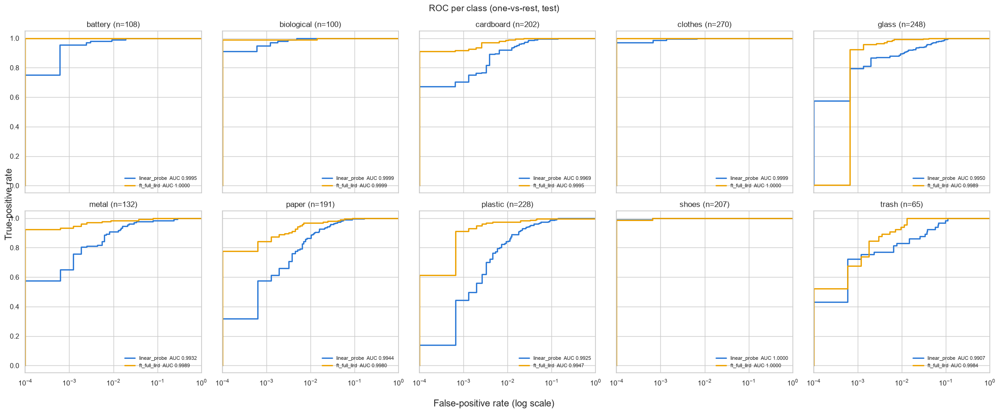

In [66]:
def plot_class_curves(kind: str) -> tuple[plt.Figure, pd.DataFrame]:
    fig, axes = plt.subplots(2, 5, figsize=(22, 9), sharex=True, sharey=True)
    scores = []
    for k, ax in enumerate(axes.flat):
        y_bin = y_test == k
        for name, res, color in ((BASELINE_NAME, base_final["test"], BASE_COLOR), (best_name, final["test"], BEST_COLOR)):
            s = res["probs"][:, k]
            if kind == "pr":
                prec, rec, _ = precision_recall_curve(y_bin, s)
                value = average_precision_score(y_bin, s)
                ax.plot(rec, prec, color=color, lw=2, label=f"{name}  AP {value:.3f}")
            else:
                fpr, tpr, _ = roc_curve(y_bin, s)
                value = auc(fpr, tpr)
                ax.plot(np.clip(fpr, 1e-4, 1), tpr, color=color, lw=2, label=f"{name}  AUC {value:.4f}")
            scores.append({"class": classes[k], "model": name, "AP" if kind == "pr" else "ROC-AUC": value})
        ax.set_title(f"{classes[k]} (n={int(y_bin.sum())})")
        ax.legend(frameon=False, fontsize=8, loc="lower left" if kind == "pr" else "lower right")
    if kind == "pr":
        fig.supxlabel("Recall")
        fig.supylabel("Precision")
        fig.suptitle("Precision–recall per class (one-vs-rest, test, temperature-scaled)", fontsize=14)
    else:
        axes.flat[0].set_xscale("log")
        axes.flat[0].set_xlim(1e-4, 1)
        fig.supxlabel("False-positive rate (log scale)")
        fig.supylabel("True-positive rate")
        fig.suptitle("ROC per class (one-vs-rest, test)", fontsize=14)
    fig.tight_layout()
    table = pd.DataFrame(scores).pivot(index="class", columns="model").droplevel(0, axis=1)
    return fig, table[[BASELINE_NAME, best_name]]


fig, ap_table = plot_class_curves("pr")
save_eval_figure(fig, "pr_curves_per_class")
plt.show()
fig, auc_table = plot_class_curves("roc")
save_eval_figure(fig, "roc_curves_per_class")
plt.show()

curve_table = pd.concat({"AP": ap_table, "ROC-AUC": auc_table}, axis=1).sort_values(("AP", best_name))
display(curve_table.style.format("{:.4f}").set_caption("Per-class ranking quality (test)"))

### 13.6 Calibration

Reliability diagram and confidence distribution of the **raw** and the **temperature-scaled** selected model. After scaling, the
bars should sit on the diagonal; the right-hand histograms show where correct and incorrect predictions overlap — that overlap is
where a rejection threshold (13.7) acts.

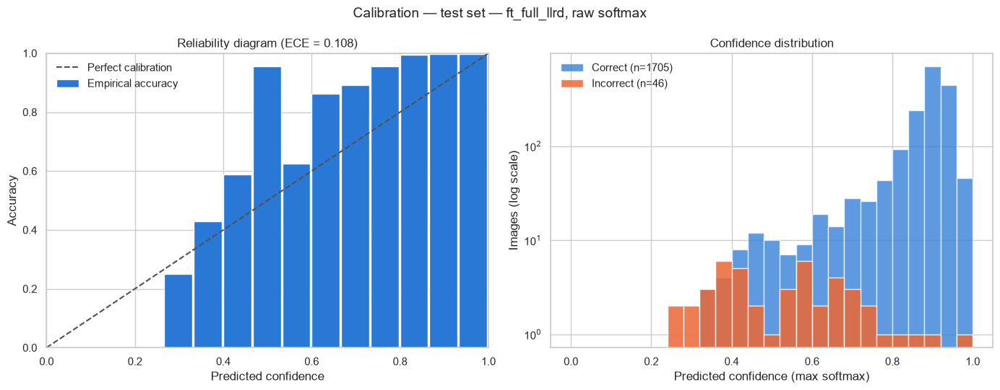

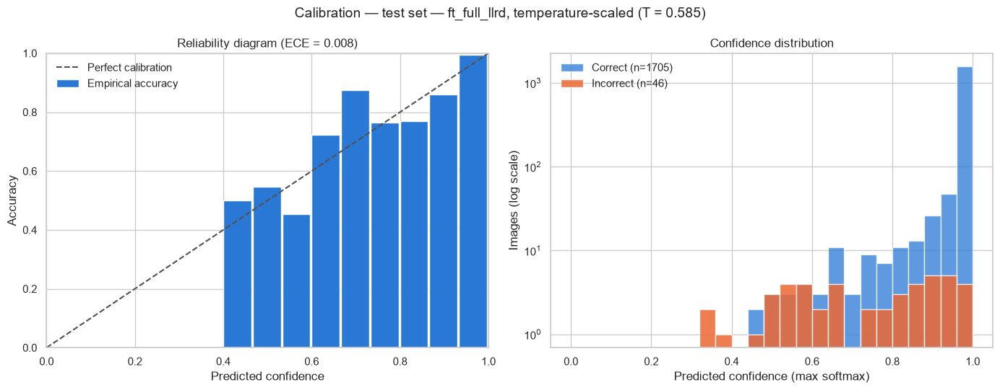

In [67]:
for key, label in (("probs_raw", "raw softmax"), ("probs", f"temperature-scaled (T = {T_final:.3f})")):
    fig = plot_calibration(y_test, final["test"][key], f"Calibration — test set — {best_name}, {label}")
    save_eval_figure(fig, f"calibration_{'raw' if key == 'probs_raw' else 'scaled'}")
    plt.show()

### 13.7 Selective prediction — accuracy vs. coverage

In deployment, low-confidence items can be routed to **manual inspection** instead of being sorted automatically. The
risk–coverage curve shows the accuracy on the automatically handled fraction as the confidence threshold rises.

**Protocol.** For each target accuracy the threshold is chosen on **validation** (largest coverage that reaches the target) and
then applied unchanged to **test**, which reports the honest coverage / accuracy. AURC (area under the risk–coverage curve,
lower is better) summarises the whole curve. Confidences are temperature-scaled; scaling does not change the ranking, but it makes
the thresholds interpretable as probabilities.

,model,target accuracy,threshold (val),test coverage,test accuracy (covered),test images to review
0,ft_full_llrd,97.0%,0.354,99.9%,97.48%,2
1,ft_full_llrd,98.0%,0.630,98.2%,98.31%,31
2,ft_full_llrd,99.0%,0.894,93.8%,99.21%,109
3,ft_full_llrd,99.5%,0.974,87.3%,99.74%,223
4,linear_probe,97.0%,0.759,88.7%,97.81%,198
5,linear_probe,98.0%,0.848,84.6%,98.31%,269
6,linear_probe,99.0%,0.943,75.0%,99.31%,438
7,linear_probe,99.5%,0.969,67.8%,99.58%,564


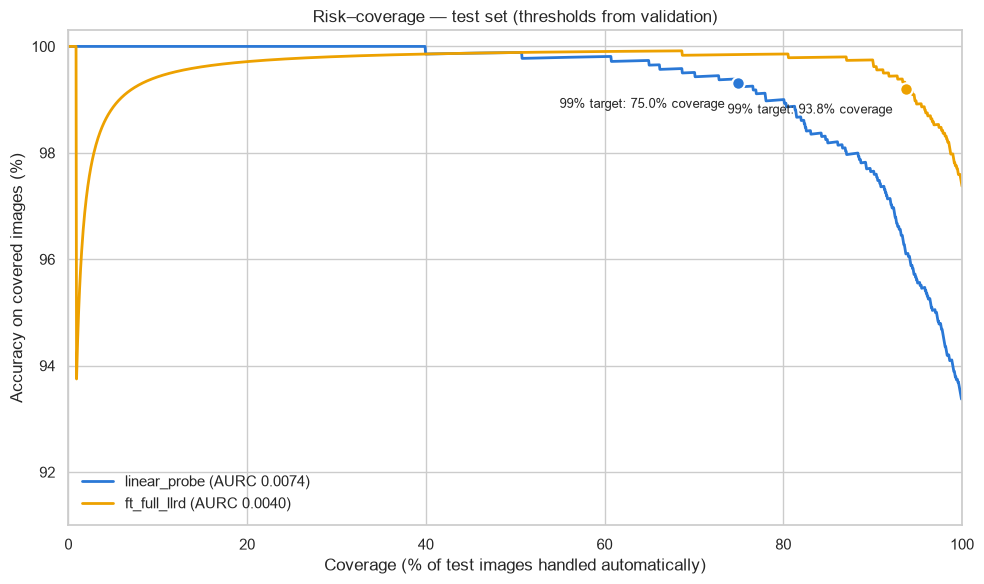

In [68]:
def risk_coverage(y: np.ndarray, probs: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Coverage, accuracy on the covered part, and the confidence threshold — sorted by decreasing confidence."""
    conf = probs.max(axis=1)
    order = np.argsort(-conf, kind="stable")
    correct = (probs.argmax(axis=1) == y)[order]
    n_cov = np.arange(1, len(y) + 1)
    return n_cov / len(y), np.cumsum(correct) / n_cov, conf[order]


def threshold_for_target(y: np.ndarray, probs: np.ndarray, target: float) -> float:
    """Lowest confidence threshold whose covered subset still reaches `target` accuracy (max coverage)."""
    _, acc, conf = risk_coverage(y, probs)
    ok = np.nonzero(acc >= target)[0]
    return float(conf[ok.max()]) if len(ok) else float("nan")


def apply_threshold(y: np.ndarray, probs: np.ndarray, t: float) -> tuple[float, float, int]:
    keep = probs.max(axis=1) >= t
    acc = float((probs.argmax(axis=1)[keep] == y[keep]).mean()) if keep.any() else float("nan")
    return float(keep.mean()), acc, int((~keep).sum())


TARGETS = [0.97, 0.98, 0.99, 0.995]
sel_rows = []
for name, res_val, res_test in ((best_name, final["val"], final["test"]),
                                (BASELINE_NAME, base_final["val"], base_final["test"])):
    for target in TARGETS:
        t = threshold_for_target(y_val, res_val["probs"], target)
        cov, acc, n_review = apply_threshold(y_test, res_test["probs"], t) if np.isfinite(t) else (np.nan, np.nan, -1)
        sel_rows.append({"model": name, "target accuracy": target, "threshold (val)": t,
                         "test coverage": cov, "test accuracy (covered)": acc, "test images to review": n_review})
selective_df = pd.DataFrame(sel_rows)
display(selective_df.style.format({"target accuracy": "{:.1%}", "threshold (val)": "{:.3f}", "test coverage": "{:.1%}",
                                   "test accuracy (covered)": "{:.2%}"}, na_rep="unreachable")
        .set_caption("Thresholds chosen on validation, evaluated on test"))

fig, ax = plt.subplots(figsize=(10, 6))
for name, res, color in ((BASELINE_NAME, base_final["test"], BASE_COLOR), (best_name, final["test"], BEST_COLOR)):
    cov, acc, _ = risk_coverage(y_test, res["probs"])
    aurc = float((1 - acc).mean())
    ax.plot(cov * 100, acc * 100, color=color, lw=2, label=f"{name} (AURC {aurc:.4f})")
    for _, r in selective_df[(selective_df["model"] == name) & (selective_df["target accuracy"] == 0.99)].iterrows():
        if np.isfinite(r["test coverage"]):
            ax.plot(r["test coverage"] * 100, r["test accuracy (covered)"] * 100, marker="o", ms=9, color=color,
                    mec="white", mew=1.5, ls="none")
            ax.annotate(f"99% target: {r['test coverage']:.1%} coverage", (r["test coverage"] * 100,
                        r["test accuracy (covered)"] * 100), textcoords="offset points", xytext=(-10, -18),
                        ha="right", fontsize=9)
full_cov_acc = min(float((res["y_pred"] == y_test).mean()) for res in (final["test"], base_final["test"]))
y_lo = max(0.0, float(np.floor(full_cov_acc * 100)) - 2)  # just below the accuracy at 100 % coverage
ax.set(xlim=(0, 100), ylim=(y_lo, 100.3), xlabel="Coverage (% of test images handled automatically)",
       ylabel="Accuracy on covered images (%)", title="Risk–coverage — test set (thresholds from validation)")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
save_eval_figure(fig, "risk_coverage")
plt.show()

### 13.8 Top-k accuracy

Relevant for a *"suggest a bin"* interface that shows the k most likely classes.

In [69]:
topk_df = pd.DataFrame({
    f"{name} {split}": [top_k_accuracy_score(y, res["probs"], k=k, labels=np.arange(K)) for k in range(1, 6)]
    for name, src in ((best_name, final), (BASELINE_NAME, base_final))
    for split, y, res in (("val", y_val, src["val"]), ("test", y_test, src["test"]))
}, index=pd.Index(range(1, 6), name="k"))
display(topk_df.style.format("{:.2%}").set_caption("Top-k accuracy"))

,ft_full_llrd val,ft_full_llrd test,linear_probe val,linear_probe test
k,,,,
1,97.26%,97.37%,94.06%,93.38%
2,99.03%,98.86%,98.29%,97.83%
3,99.49%,99.37%,99.32%,99.20%
4,99.71%,99.49%,99.71%,99.60%
5,99.77%,99.60%,99.83%,99.89%


### 13.9 Error analysis

Remaining mistakes sorted by confidence — the **most confident** ones are most often label noise or a systematic blind spot —
then the weakest class in detail, the least confident *correct* predictions, and the error rate against image geometry for both
models (does fine-tuning reduce the center-crop problem for extreme aspect ratios?).

Misclassified test images: 46 / 1751 (2.63%)


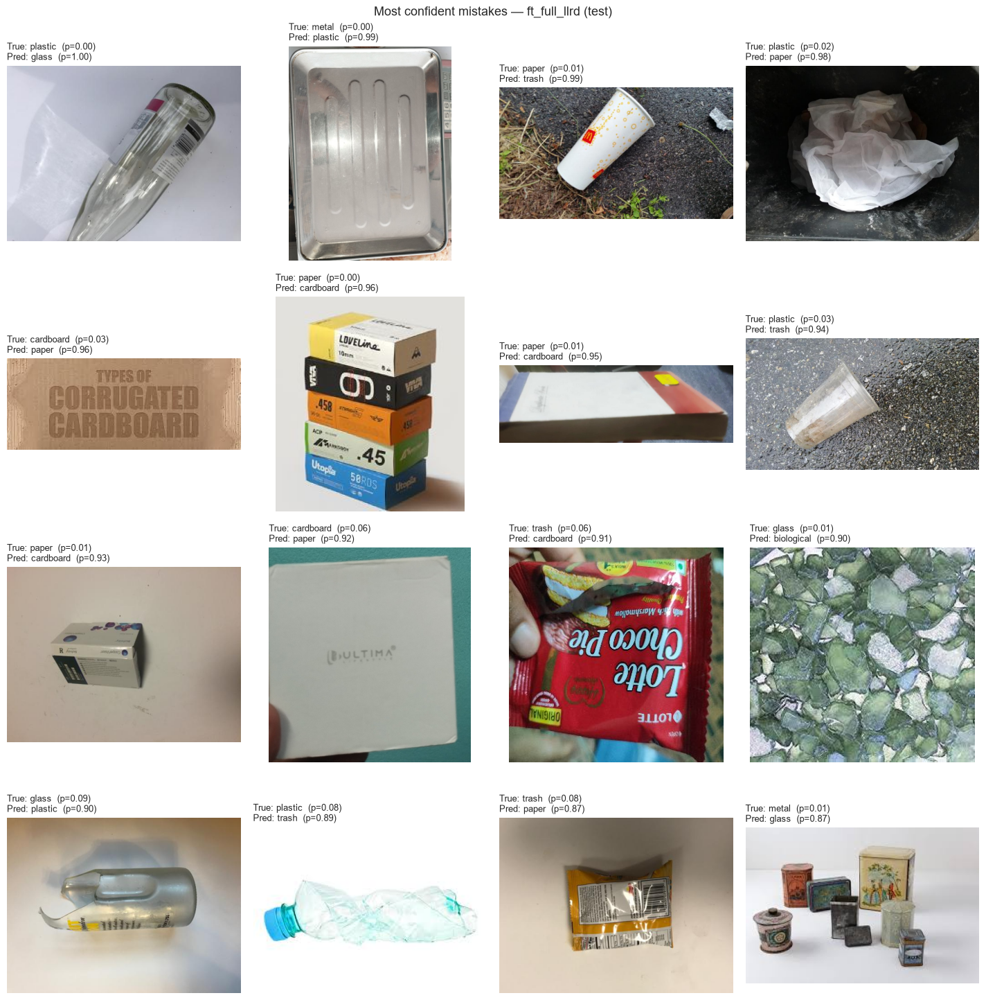

Weakest class: 'trash' -> 10 missed images; predicted as:


,count
pred,
paper,4
cardboard,2
biological,1
metal,1
glass,1
plastic,1


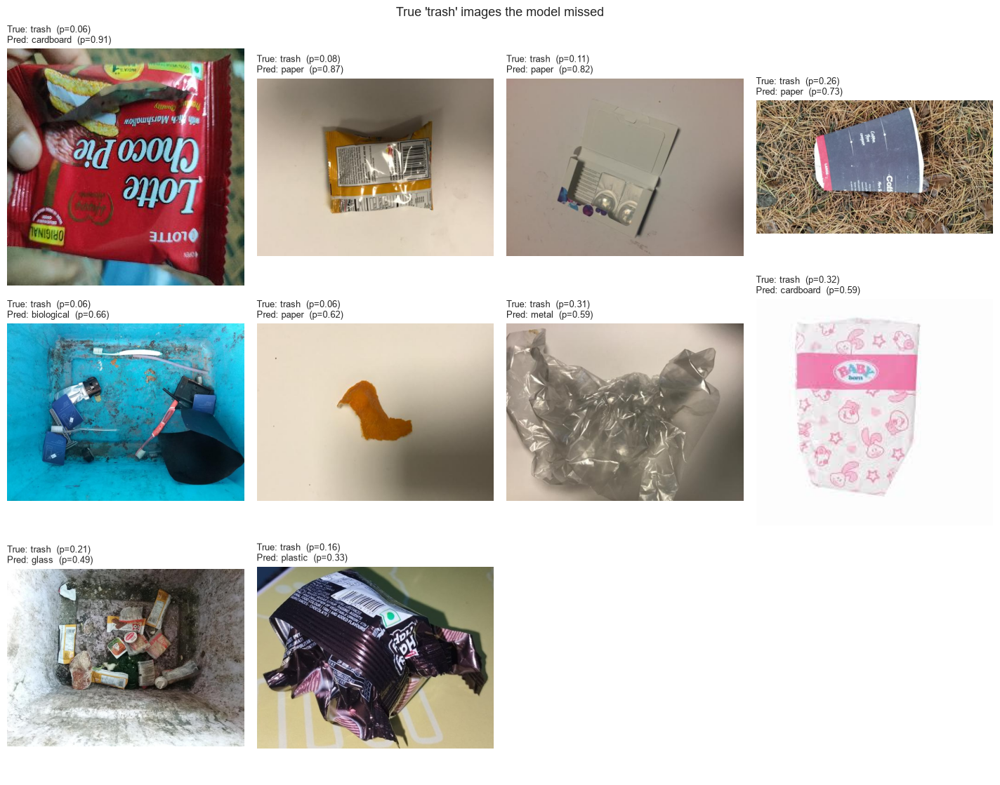

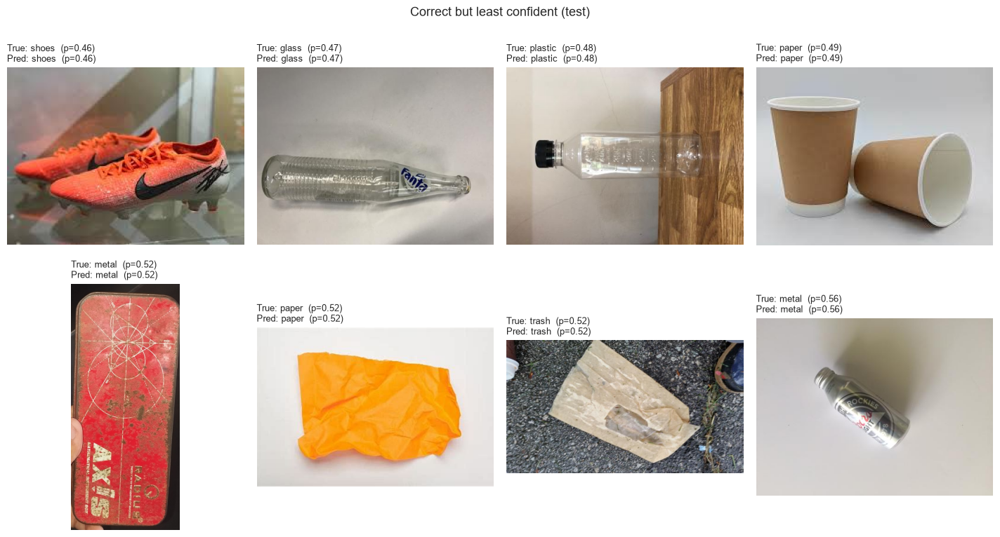

,images,error rate linear_probe,error rate ft_full_llrd
aspect_bucket,,,
very tall (<0.5),22,22.73%,0.00%
tall,458,2.62%,0.66%
square-ish,459,4.58%,1.53%
wide,787,9.40%,4.07%
very wide (>2),25,16.00%,16.00%


,images,error rate linear_probe,error rate ft_full_llrd
min_side_bucket,,,
<150 px,34,5.88%,5.88%
150-224 px,466,5.58%,2.36%
224-400 px,960,6.04%,1.77%
>400 px,291,10.31%,5.50%


In [70]:
eval_pred = build_prediction_frame(test_df, final["test"], classes)
eval_errors = eval_pred[~eval_pred["correct"]].sort_values("confidence", ascending=False)
print(f"Misclassified test images: {len(eval_errors)} / {len(eval_pred)} ({len(eval_errors) / len(eval_pred):.2%})")

fig = show_prediction_grid(eval_errors.head(16), f"Most confident mistakes — {best_name} (test)")
if fig is not None:
    save_eval_figure(fig, "errors_most_confident")
    plt.show()

weakest_class = per_class_df.index[0]
missed = eval_errors[eval_errors["true"] == weakest_class]
print(f"Weakest class: '{weakest_class}' -> {len(missed)} missed images; predicted as:")
display(missed["pred"].value_counts().rename("count").to_frame())
fig = show_prediction_grid(missed.head(12), f"True '{weakest_class}' images the model missed")
if fig is not None:
    save_eval_figure(fig, "errors_weakest_class")
    plt.show()

fig = show_prediction_grid(eval_pred[eval_pred["correct"]].nsmallest(8, "confidence"),
                           "Correct but least confident (test)")
if fig is not None:
    plt.show()

geo = eval_pred[["path", "correct"]].assign(baseline_correct=base_final["test"]["y_pred"] == y_test).merge(
    ok[["path", "width", "height", "aspect"]], on="path", how="left", validate="one_to_one")
geo["aspect_bucket"] = pd.cut(geo["aspect"], bins=[0, 0.5, 0.8, 1.25, 2.0, np.inf],
                              labels=["very tall (<0.5)", "tall", "square-ish", "wide", "very wide (>2)"])
geo["min_side_bucket"] = pd.cut(geo[["width", "height"]].min(axis=1), bins=[0, 150, 224, 400, np.inf],
                                labels=["<150 px", "150-224 px", "224-400 px", ">400 px"])
for col in ("aspect_bucket", "min_side_bucket"):
    table = geo.groupby(col, observed=True).agg(
        images=("correct", "size"),
        **{f"error rate {BASELINE_NAME}": ("baseline_correct", lambda s: 1 - s.mean()),
           f"error rate {best_name}": ("correct", lambda s: 1 - s.mean())})
    display(table.style.format({c: "{:.2%}" for c in table.columns if c.startswith("error")})
            .set_caption(f"Test error rate by {col}"))

### 13.10 Grad-CAM — where does the model look?

Grad-CAM (Selvaraju et al., 2017) weights the activation maps of the last stage (`trunk_output.block4`, 7×7 for a 224 input) by
the spatially averaged gradient of a class score and up-samples the result. It is shown on the exact 224×224 crop the model sees.

* **Mistakes:** the map for the *predicted* class next to the map for the *true* class. If the predicted-class map sits on
  background, packaging or a secondary object, the error is a context / ambiguity problem rather than a feature problem.
* **Correct predictions** (one confident example per class): the map should cover the object itself.

The maps are cached; the network is only run when the cache is missing.

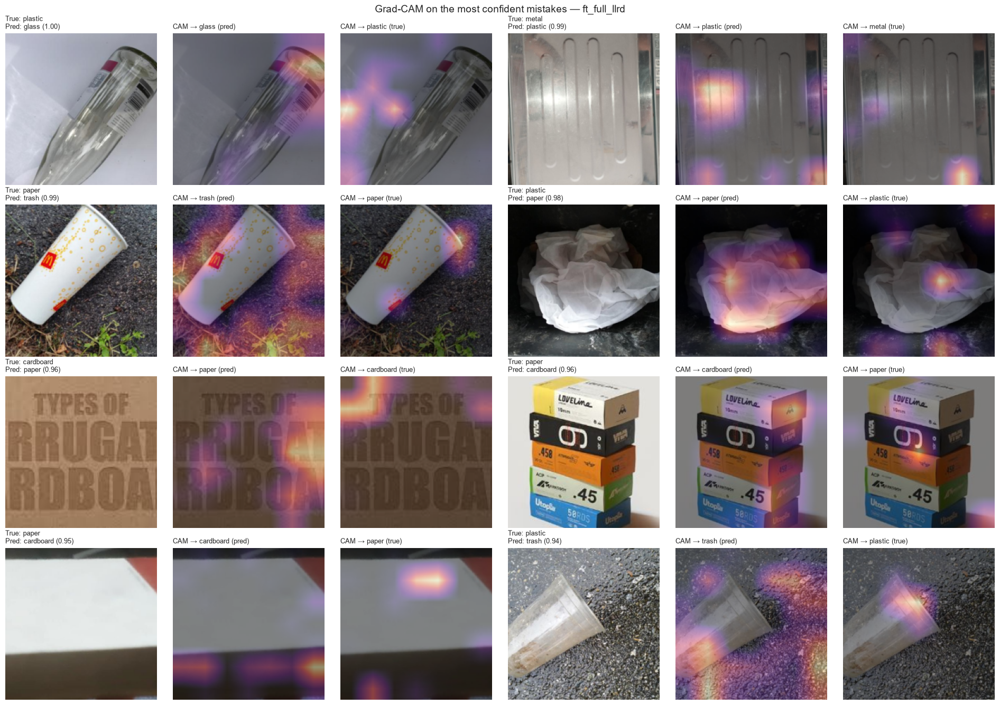

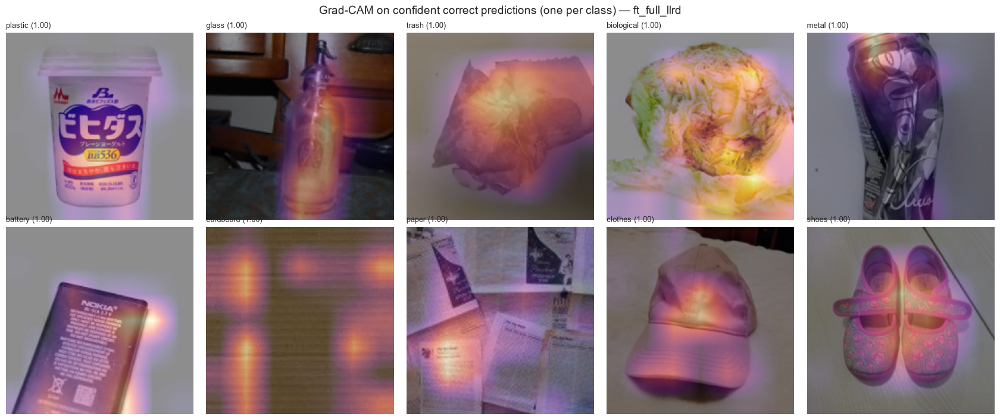

In [71]:
class GradCAM:
    """Grad-CAM on the output of `layer` (Selvaraju et al., 2017)."""

    def __init__(self, model: nn.Module, layer: nn.Module) -> None:
        self.model, self.layer = model, layer

    def __call__(self, x: torch.Tensor, target: torch.Tensor) -> np.ndarray:
        store: dict[str, torch.Tensor] = {}

        def hook(_module, _inp, out):
            store["act"] = out
            out.register_hook(lambda g: store.__setitem__("grad", g))

        handle = self.layer.register_forward_hook(hook)
        try:
            self.model.eval()
            self.model.zero_grad(set_to_none=True)
            with torch.enable_grad():
                logits = self.model(x.requires_grad_(True))
                logits.gather(1, target.view(-1, 1)).sum().backward()
        finally:
            handle.remove()
        act, grad = store["act"].detach(), store["grad"].detach()
        cam = F.relu((grad.mean(dim=(2, 3), keepdim=True) * act).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        lo, hi = cam.amin(dim=(1, 2), keepdim=True), cam.amax(dim=(1, 2), keepdim=True)
        return ((cam - lo) / (hi - lo + 1e-8)).cpu().numpy().astype(np.float16)


CAM_MISTAKES = 8
mistake_idx = eval_errors.index[:CAM_MISTAKES].to_numpy()
correct_idx = (eval_pred[eval_pred["correct"]].sort_values("confidence", ascending=False)
               .groupby("true", sort=False).head(1).index.to_numpy())


def compute_gradcam() -> dict[str, np.ndarray]:
    model = get_model(best_name)
    cam = GradCAM(model, model.trunk_output.block4)
    out: dict[str, np.ndarray] = {"mistake_idx": mistake_idx, "correct_idx": correct_idx}
    for tag, idx in (("mistake", mistake_idx), ("correct", correct_idx)):
        if len(idx) == 0:
            out[f"{tag}_cam_pred"] = out[f"{tag}_cam_true"] = np.zeros((0, CROP, CROP), np.float16)
            continue
        x = normalize_batch(load_clean_uint8(eval_pred.loc[idx, "path"].tolist()).float().div(255)).to(device)
        out[f"{tag}_cam_pred"] = cam(x.clone(), torch.as_tensor(final["test"]["y_pred"][idx], device=device))
        out[f"{tag}_cam_true"] = cam(x.clone(), torch.as_tensor(y_test[idx], device=device))
    return out


cams = cached_npz("gradcam", compute_gradcam)
if not (np.array_equal(cams["mistake_idx"], mistake_idx) and np.array_equal(cams["correct_idx"], correct_idx)):
    FORCE_RECOMPUTE, _prev = True, FORCE_RECOMPUTE
    cams = cached_npz("gradcam", compute_gradcam)  # selection changed -> refresh the cache
    FORCE_RECOMPUTE = _prev


def show_cam(ax, img: torch.Tensor, cam: np.ndarray | None, title: str) -> None:
    ax.imshow(img.permute(1, 2, 0).numpy())
    if cam is not None:
        ax.imshow(cam.astype(np.float32), cmap="magma", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(title, fontsize=9, loc="left")
    ax.axis("off")


if len(mistake_idx):
    imgs = load_clean_uint8(eval_pred.loc[mistake_idx, "path"].tolist())
    per_row = 2
    n_rows = int(np.ceil(len(mistake_idx) / per_row))
    fig, axes = plt.subplots(n_rows, 3 * per_row, figsize=(3.2 * 3 * per_row, 3.4 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for j, i in enumerate(mistake_idx):
        r, c0 = divmod(j, per_row)
        row = eval_pred.loc[i]
        show_cam(axes[r, 3 * c0], imgs[j], None, f"True: {row['true']}\nPred: {row['pred']} ({row['confidence']:.2f})")
        show_cam(axes[r, 3 * c0 + 1], imgs[j], cams["mistake_cam_pred"][j], f"CAM → {row['pred']} (pred)")
        show_cam(axes[r, 3 * c0 + 2], imgs[j], cams["mistake_cam_true"][j], f"CAM → {row['true']} (true)")
    fig.suptitle(f"Grad-CAM on the most confident mistakes — {best_name}", fontsize=14)
    fig.tight_layout()
    save_eval_figure(fig, "gradcam_mistakes")
    plt.show()

if len(correct_idx):
    imgs = load_clean_uint8(eval_pred.loc[correct_idx, "path"].tolist())
    n_cols = 5
    n_rows = int(np.ceil(len(correct_idx) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 3.6 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for j, i in enumerate(correct_idx):
        row = eval_pred.loc[i]
        show_cam(axes.flat[j], imgs[j], cams["correct_cam_pred"][j], f"{row['true']} ({row['confidence']:.2f})")
    fig.suptitle(f"Grad-CAM on confident correct predictions (one per class) — {best_name}", fontsize=14)
    fig.tight_layout()
    save_eval_figure(fig, "gradcam_correct")
    plt.show()

### 13.11 Embedding space — how did fine-tuning reorganise the features?

The 888-d global-average-pooled features (input of `fc`) are extracted for the baseline (= frozen ImageNet features) and the
selected model. Three views:

* **5-NN accuracy** — test images classified by cosine similarity to their 5 nearest *validation* images, without the linear
  head. It measures how linearly-independent, *local* class structure the features have.
* **Silhouette score** (cosine, by true class) — cluster compactness vs. separation, in [-1, 1].
* **t-SNE** of the test features (PCA-50 first). Class names mark each class's median position; misclassified images are drawn
  in orange. t-SNE preserves neighbourhoods, not global distances — read clusters, not inter-cluster gaps.

,linear_probe,ft_full_llrd
5-NN accuracy (val gallery → test),0.9075,0.9629
"silhouette (cosine, test)",0.1569,0.2792


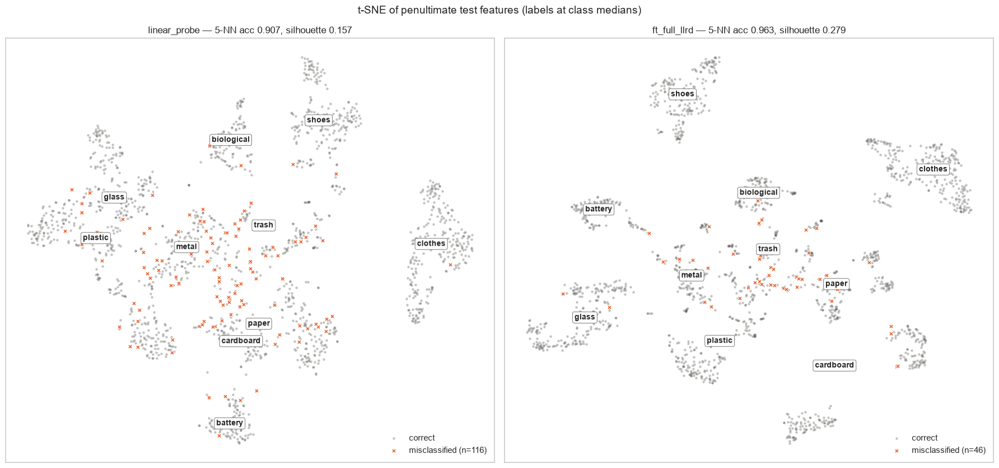

In [72]:
@torch.inference_mode()
def extract_features(model: nn.Module, loader: DataLoader) -> np.ndarray:
    """Penultimate (pre-fc) features — same forward path as torchvision's RegNet.forward."""
    model.eval()
    feats = []
    for X, _ in loader:
        x = model.trunk_output(model.stem(X.to(device, non_blocking=True)))
        feats.append(model.avgpool(x).flatten(1).float().cpu())
    return torch.cat(feats).numpy()


def compute_embeddings() -> dict[str, np.ndarray]:
    out = {}
    for tag, name in (("best", best_name), ("base", BASELINE_NAME)):
        model = get_model(name)
        out[f"{tag}_val"], out[f"{tag}_test"] = extract_features(model, val_dl), extract_features(model, test_dl)
    return out


def l2_normalize(x: np.ndarray) -> np.ndarray:
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-12)


def knn_accuracy(gallery: np.ndarray, g_y: np.ndarray, query: np.ndarray, q_y: np.ndarray, k: int = 5) -> float:
    sims = l2_normalize(query) @ l2_normalize(gallery).T
    nn_idx = np.argpartition(-sims, k, axis=1)[:, :k]
    rows = np.arange(len(query))[:, None]
    votes = np.zeros((len(query), K))
    np.add.at(votes, (rows, g_y[nn_idx]), sims[rows, nn_idx])
    return float((votes.argmax(axis=1) == q_y).mean())


emb = cached_npz("embeddings", compute_embeddings)


def compute_tsne() -> dict[str, np.ndarray]:
    out = {}
    for tag in ("base", "best"):
        x = l2_normalize(emb[f"{tag}_test"])
        x = PCA(n_components=min(50, x.shape[1], len(x) - 1), random_state=SEED).fit_transform(x)
        out[tag] = TSNE(n_components=2, perplexity=min(30.0, (len(x) - 1) / 3), init="pca",
                        random_state=SEED).fit_transform(x)
    return out


tsne = cached_npz("tsne", compute_tsne)

emb_rows = {}
for tag, name in (("base", BASELINE_NAME), ("best", best_name)):
    emb_rows[name] = {
        "5-NN accuracy (val gallery → test)": knn_accuracy(emb[f"{tag}_val"], y_val, emb[f"{tag}_test"], y_test),
        "silhouette (cosine, test)": float(silhouette_score(l2_normalize(emb[f"{tag}_test"]), y_test, metric="cosine")),
    }
emb_df = pd.DataFrame(emb_rows)
display(emb_df.style.format("{:.4f}").set_caption("Feature-space quality without the linear head"))

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
for ax, (tag, name, res) in zip(axes, (("base", BASELINE_NAME, base_final["test"]), ("best", best_name, final["test"]))):
    xy, wrong = tsne[tag], res["y_pred"] != y_test
    ax.scatter(xy[~wrong, 0], xy[~wrong, 1], s=10, color=NEUTRAL_COLOR, alpha=0.35, linewidths=0, label="correct")
    ax.scatter(xy[wrong, 0], xy[wrong, 1], s=28, marker="X", color=VAL_COLOR, edgecolors="white", linewidths=0.6,
               label=f"misclassified (n={wrong.sum()})")
    for k, c in enumerate(classes):
        cx, cy = np.median(xy[y_test == k], axis=0)
        ax.text(cx, cy, c, ha="center", va="center", fontsize=10, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=NEUTRAL_COLOR, lw=0.6, alpha=0.9))
    m = emb_rows[name]
    ax.set_title(f"{name} — 5-NN acc {m['5-NN accuracy (val gallery → test)']:.3f}, "
                 f"silhouette {m['silhouette (cosine, test)']:.3f}")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(frameon=False, loc="lower right")
fig.suptitle("t-SNE of penultimate test features (labels at class medians)", fontsize=14)
fig.tight_layout()
save_eval_figure(fig, "tsne_embeddings")
plt.show()

### 13.12 Robustness to common corruptions

Real sorting lines see motion blur, sensor noise, poor lighting, heavy compression, low-resolution cameras and rotated items.
Each corruption is applied at three severities to the deterministic 224×224 test crops, **before** normalisation, and both models
see the identical corrupted image (seeded noise) — so the comparison is paired. No TTA here, to isolate the network itself.

| Corruption | Severity 1 / 2 / 3 |
|------------|--------------------|
| Gaussian blur σ (px) | 1 / 2 / 3 |
| Gaussian noise std (on [0, 1]) | 0.04 / 0.08 / 0.16 |
| Darken (brightness ×) | 0.7 / 0.5 / 0.3 |
| Low contrast (contrast ×) | 0.6 / 0.4 / 0.2 |
| JPEG quality | 30 / 15 / 5 |
| Low resolution (down to px, then back up) | 112 / 64 / 32 |
| Rotation (degrees) | 15 / 30 / 45 |

**Retention** = mean corrupted macro-F1 / clean macro-F1. The clean row is checked against the stored test logits.

,clean macro-F1,mean corrupted macro-F1,worst case macro-F1,retention,worst corruption
model,,,,,
ft_full_llrd,0.9672,0.9091,0.7045,0.9398,low_resolution (sev 3)
linear_probe,0.9244,0.8515,0.6212,0.9211,jpeg (sev 3)


model,linear_probe,ft_full_llrd,Δ (pp)
corruption,,,
jpeg,0.774473,0.845414,+7.09
low_resolution,0.782310,0.853128,+7.08
gaussian_noise,0.837702,0.875528,+3.78
gaussian_blur,0.828862,0.912526,+8.37
rotation,0.905352,0.948055,+4.27
low_contrast,0.913782,0.963650,+4.99
darken,0.918075,0.965133,+4.71


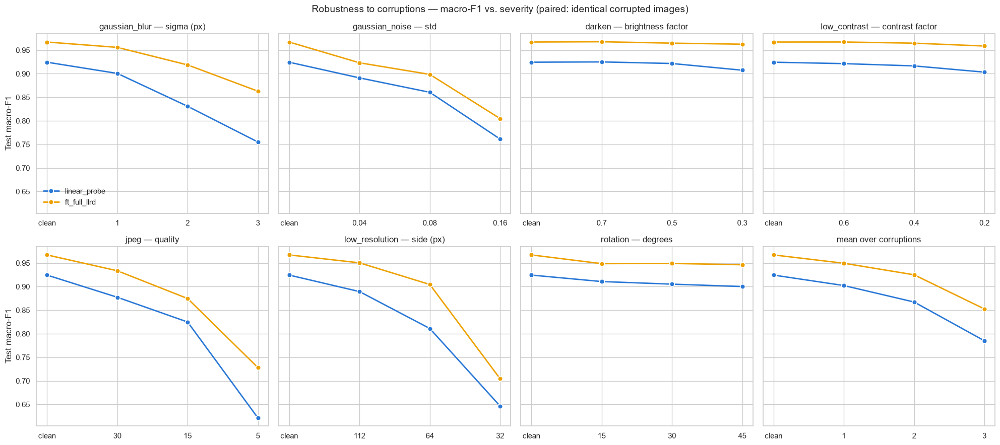

In [73]:
CORRUPTIONS: dict[str, tuple[str, list[float]]] = {
    "gaussian_blur": ("sigma (px)", [1.0, 2.0, 3.0]),
    "gaussian_noise": ("std", [0.04, 0.08, 0.16]),
    "darken": ("brightness factor", [0.7, 0.5, 0.3]),
    "low_contrast": ("contrast factor", [0.6, 0.4, 0.2]),
    "jpeg": ("quality", [30, 15, 5]),
    "low_resolution": ("side (px)", [112, 64, 32]),
    "rotation": ("degrees", [15, 30, 45]),
}


def corrupt(x_uint8: torch.Tensor, kind: str, level: float, gen: torch.Generator) -> torch.Tensor:
    """uint8 CPU batch -> corrupted float batch in [0, 1] on `device`."""
    if kind == "jpeg":
        x_uint8 = torch.stack([decode_jpeg(encode_jpeg(img, quality=int(level))) for img in x_uint8])
    x = x_uint8.to(device).float().div_(255)
    if kind == "gaussian_blur":
        k = 2 * int(np.ceil(3 * level)) + 1
        x = TF.gaussian_blur(x, [k, k], [level, level])
    elif kind == "gaussian_noise":
        x = x + level * torch.randn(x.shape, generator=gen, device=x.device)
    elif kind == "darken":
        x = x * level
    elif kind == "low_contrast":
        x = TF.adjust_contrast(x, level)
    elif kind == "low_resolution":
        s = int(level)
        x = F.interpolate(x, size=(s, s), mode="bilinear", antialias=True, align_corners=False)
        x = F.interpolate(x, size=(CROP, CROP), mode="bilinear", align_corners=False)
    elif kind == "rotation":
        x = TF.rotate(x, level, interpolation=T.InterpolationMode.BILINEAR)
    return x.clamp_(0, 1)


@torch.inference_mode()
def compute_robustness() -> pd.DataFrame:
    x_all = clean_split_uint8(test_df)
    models = {name: get_model(name) for name in (best_name, BASELINE_NAME)}
    settings = [("clean", 0, "-", 0.0)] + [(kind, s + 1, pname, lvl) for kind, (pname, levels) in CORRUPTIONS.items()
                                           for s, lvl in enumerate(levels)]
    rows = []
    for kind, sev, pname, lvl in tqdm(settings, desc="corruptions"):
        gen = torch.Generator(device=device.type).manual_seed(SEED)
        preds: dict[str, list[torch.Tensor]] = {n: [] for n in models}
        for i in range(0, len(x_all), 128):
            xb = x_all[i:i + 128]
            x = xb.to(device).float().div_(255) if kind == "clean" else corrupt(xb, kind, lvl, gen)
            x = normalize_batch(x)
            for n, m in models.items():
                preds[n].append(m(x).argmax(dim=1).cpu())
        for n, p in preds.items():
            p = torch.cat(p).numpy()
            rows.append({"model": n, "corruption": kind, "severity": sev, "parameter": pname, "level": lvl,
                         "accuracy": float((p == y_test).mean()), "macro_f1": fast_macro_f1(y_test, p, K)})
    return pd.DataFrame(rows)


robustness_df = cached_frame("robustness", compute_robustness)

for name in (best_name, BASELINE_NAME):  # the clean path must reproduce the stored (no-TTA) test predictions
    clean_f1 = robustness_df.query("model == @name and corruption == 'clean'")["macro_f1"].item()
    assert abs(clean_f1 - fast_macro_f1(y_test, records[name]["test"]["y_pred"], K)) < 2e-3, name

clean = robustness_df[robustness_df["corruption"] == "clean"].set_index("model")["macro_f1"]
corrupted = robustness_df[robustness_df["corruption"] != "clean"]
rob_summary = corrupted.groupby("model")["macro_f1"].agg(["mean", "min"]).rename(
    columns={"mean": "mean corrupted macro-F1", "min": "worst case macro-F1"})
rob_summary.insert(0, "clean macro-F1", clean)
rob_summary["retention"] = rob_summary["mean corrupted macro-F1"] / rob_summary["clean macro-F1"]
rob_summary["worst corruption"] = corrupted.loc[corrupted.groupby("model")["macro_f1"].idxmin()].set_index("model").apply(
    lambda r: f"{r['corruption']} (sev {r['severity']})", axis=1)
display(rob_summary.loc[[best_name, BASELINE_NAME]].style.format(
    {c: "{:.4f}" for c in rob_summary.columns if c != "worst corruption"}))

per_corr = corrupted.pivot_table(index="corruption", columns="model", values="macro_f1", aggfunc="mean")
per_corr["Δ (pp)"] = 100 * (per_corr[best_name] - per_corr[BASELINE_NAME])
display(per_corr[[BASELINE_NAME, best_name, "Δ (pp)"]].sort_values(best_name).style
        .format("{:.4f}").format({"Δ (pp)": "{:+.2f}"}).set_caption("Mean macro-F1 over the three severities"))

panels = [*CORRUPTIONS, "mean over corruptions"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey=True)
for ax, kind in zip(axes.flat, panels):
    for name, color in ((BASELINE_NAME, BASE_COLOR), (best_name, BEST_COLOR)):
        sub = robustness_df[robustness_df["model"] == name]
        if kind == "mean over corruptions":
            curve = pd.concat([sub[sub["corruption"] == "clean"][["severity", "macro_f1"]],
                               sub[sub["corruption"] != "clean"].groupby("severity", as_index=False)["macro_f1"].mean()])
            xticks = ["clean", "1", "2", "3"]
        else:
            curve = pd.concat([sub[sub["corruption"] == "clean"], sub[sub["corruption"] == kind]])
            levels = CORRUPTIONS[kind][1]
            xticks = ["clean", *[f"{lv:g}" for lv in levels]]
        ax.plot(curve["severity"], curve["macro_f1"], color=color, lw=2, marker="o", ms=7, mec="white", mew=1.2,
                label=name)
    ax.set_xticks(range(4), xticks)
    ax.set_title(kind if kind == "mean over corruptions" else f"{kind} — {CORRUPTIONS[kind][0]}")
for ax in axes[:, 0]:
    ax.set_ylabel("Test macro-F1")
axes.flat[0].legend(frameon=False, loc="lower left")
fig.suptitle("Robustness to corruptions — macro-F1 vs. severity (paired: identical corrupted images)", fontsize=14)
fig.tight_layout()
save_eval_figure(fig, "robustness")
plt.show()

### 13.13 Efficiency

Median latency of a forward pass on this machine for batch 1 (interactive use) and batch 64 (offline throughput), in fp32 and
with bf16 autocast. With TTA the per-image cost doubles. Results are cached together with the device name; running on a
different GPU triggers a new measurement.

In [74]:
@torch.inference_mode()
def time_forward(model: nn.Module, batch: int, bf16: bool, n_warmup: int, n_iter: int) -> float:
    """Median wall-clock time of one forward pass in milliseconds."""
    x = torch.randn(batch, 3, CROP, CROP, device=device)
    times = []
    for i in range(n_warmup + n_iter):
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with autocast(device_type=device.type, dtype=torch.bfloat16, enabled=bf16):
            model(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
        if i >= n_warmup:
            times.append(time.perf_counter() - t0)
    return float(np.median(times) * 1000)


DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"


def compute_latency() -> pd.DataFrame:
    model = get_model(best_name)
    gpu = device.type == "cuda"
    rows = []
    for batch in (1, 64):
        for bf16 in (False, True):
            n_iter = (100 if batch == 1 else 30) if gpu else (10 if batch == 1 else 3)
            ms = time_forward(model, batch, bf16, n_warmup=10 if gpu else 2, n_iter=n_iter)
            rows.append({"device": DEVICE_NAME, "batch": batch, "precision": "bf16" if bf16 else "fp32",
                         "latency (ms / batch)": ms, "throughput (img / s)": 1000 * batch / ms})
    return pd.DataFrame(rows)


latency_df = cached_frame("latency", compute_latency)
if latency_df["device"].iloc[0] != DEVICE_NAME:  # measured on another machine -> re-measure here
    latency_df = compute_latency()
    latency_df.to_csv(CACHE_DIR / "latency.csv", index=False)

n_params = int(best_rec["meta"]["n_total"])
efficiency = {
    "parameters (M)": n_params / 1e6,
    "GFLOPs @224 (torchvision meta)": float(regnet_1_6GF_weights.meta.get("_ops", float("nan"))),
    "checkpoint size (MB)": best_rec["ckpt"].stat().st_size / 2 ** 20,
    "TTA (×2 inference cost)": use_tta,
}
display(pd.Series(efficiency, name=best_name).to_frame())
display(latency_df.style.format({"latency (ms / batch)": "{:.2f}", "throughput (img / s)": "{:,.0f}"}).hide(axis="index"))

,ft_full_llrd
parameters (M),10.32232
GFLOPs @224 (torchvision meta),1.612
checkpoint size (MB),39.778735
TTA (×2 inference cost),False


device,batch,precision,latency (ms / batch),throughput (img / s)
NVIDIA GeForce RTX 5070 Laptop GPU,1,fp32,29.79,34
NVIDIA GeForce RTX 5070 Laptop GPU,1,bf16,44.38,23
NVIDIA GeForce RTX 5070 Laptop GPU,64,fp32,71.16,899
NVIDIA GeForce RTX 5070 Laptop GPU,64,bf16,47.68,"1,342"


### 13.14 Export — deployable bundle and evaluation artifacts

`checkpoints/best_model_bundle.pt` contains everything inference needs and nothing it does not: architecture name, weights,
class order, preprocessing parameters, temperature, the TTA decision and the manual-review threshold (val-chosen threshold for the
99 % accuracy target). Section 14 loads **only** this file.

| File in `reports/best_model/` | Content |
|------|---------|
| `metrics.json` | Recipe, headline + probability metrics with CIs, robustness and efficiency summaries |
| `per_class_test.csv` | Per-class P / R / F1 with CIs and Δ vs. baseline |
| `predictions_test.csv`, `misclassified_test.csv` | Per-image predictions with the full calibrated probability vector |
| `selective_prediction.csv`, `robustness.csv`, `latency.csv` | Tables of 13.7, 13.12, 13.13 |
| `*.png` | All figures of Section 13 |

In [75]:
review_row = selective_df.query("model == @best_name and `target accuracy` == 0.99")
REVIEW_THRESHOLD = float(review_row["threshold (val)"].item()) if len(review_row) else float("nan")

BUNDLE_PATH = PROJECT_DIR / "checkpoints" / "best_model_bundle.pt"
best_state = torch.load(best_rec["ckpt"], map_location="cpu", weights_only=False)
torch.save({
    "arch": "regnet_y_1_6gf",
    "model": best_state["model"],
    "classes": classes,
    "preprocess": {"resize": list(eval_tf.resize_size), "crop": list(eval_tf.crop_size),
                   "interpolation": eval_tf.interpolation.value, "mean": list(eval_tf.mean), "std": list(eval_tf.std)},
    "temperature": T_final,
    "tta_hflip": bool(use_tta),
    "review_threshold": REVIEW_THRESHOLD if np.isfinite(REVIEW_THRESHOLD) else None,
    "source_run": best_name,
    "source_checkpoint_md5": file_md5(best_rec["ckpt"]),
    "test_metrics": headline_df["test"].to_dict(),
}, BUNDLE_PATH)

eval_probs = pd.DataFrame(final["test"]["probs"], columns=[f"p_{c}" for c in classes])
eval_out = to_relative(pd.concat([eval_pred, eval_probs], axis=1), DATA_DIR)
eval_out.to_csv(EVAL_DIR / "predictions_test.csv", index=False)
eval_out.loc[~eval_out["correct"]].sort_values("confidence", ascending=False).to_csv(
    EVAL_DIR / "misclassified_test.csv", index=False)
per_class_df.to_csv(EVAL_DIR / "per_class_test.csv")
selective_df.to_csv(EVAL_DIR / "selective_prediction.csv", index=False)
robustness_df.to_csv(EVAL_DIR / "robustness.csv", index=False)
latency_df.to_csv(EVAL_DIR / "latency.csv", index=False)

eval_summary = {
    "model": best_name,
    "bundle": BUNDLE_PATH.relative_to(PROJECT_DIR).as_posix(),
    "recipe": {"tta_hflip": bool(use_tta), "temperature": T_final, "review_threshold_99": REVIEW_THRESHOLD},
    "headline_metrics": headline_df.to_dict(orient="index"),
    "probability_metrics": prob_df.to_dict(orient="index"),
    "embedding_quality": emb_df.to_dict(),
    "robustness": rob_summary.to_dict(orient="index"),
    "efficiency": efficiency,
}
(EVAL_DIR / "metrics.json").write_text(json.dumps(eval_summary, indent=2, default=float))
print(f"Bundle: {BUNDLE_PATH}")
print(f"Artifacts written to {EVAL_DIR}:")
for p in sorted(EVAL_DIR.iterdir()):
    if p.is_file():
        print("  ", p.name)

Bundle: C:\Users\User\Projects\DL_Learning\checkpoints\best_model_bundle.pt
Artifacts written to C:\Users\User\Projects\DL_Learning\reports\best_model:
   calibration_raw.png
   calibration_scaled.png
   confusion_matrix_test.png
   errors_most_confident.png
   errors_weakest_class.png
   gradcam_correct.png
   gradcam_mistakes.png
   headline_metrics.png
   latency.csv
   metrics.json
   misclassified_test.csv
   per_class_metrics_ci.png
   per_class_test.csv
   pr_curves_per_class.png
   predictions_test.csv
   risk_coverage.png
   robustness.csv
   robustness.png
   roc_curves_per_class.png
   selective_prediction.csv
   tsne_embeddings.png


## 14. Inference

A deployment-style predictor built **only** from the exported bundle: it rebuilds the network and the evaluation transform from
the stored parameters, applies TTA if it was selected, divides the logits by the fitted temperature and flags low-confidence
images for manual review. A consistency check compares it with the batch predictions of Section 13 before the demo.

In [ ]:
def load_bundle(path: Path) -> tuple[nn.Module, dict]:
    bundle = torch.load(path, map_location="cpu", weights_only=False)
    assert bundle["arch"] == "regnet_y_1_6gf"
    net = regnet_y_1_6gf(weights=None)
    net.fc = nn.Linear(net.fc.in_features, len(bundle["classes"]))
    net.load_state_dict(bundle["model"])
    pp = bundle["preprocess"]
    bundle["transform"] = T.Compose([
        T.Resize(pp["resize"], interpolation=T.InterpolationMode(pp["interpolation"]), antialias=True),
        T.CenterCrop(pp["crop"]), T.ToTensor(), T.Normalize(pp["mean"], pp["std"]),
    ])
    return net.to(device).eval(), bundle


@torch.inference_mode()
def predict(image_path: str | Path, net: nn.Module, bundle: dict, top_k: int = 3) -> dict:
    """Top-k (class, calibrated probability) and a manual-review flag for one image file."""
    with Image.open(image_path) as im:
        x = bundle["transform"](im.convert("RGB")).unsqueeze(0).to(device)
    logits = net(x).float()
    if bundle["tta_hflip"]:
        logits = 0.5 * (logits + net(torch.flip(x, dims=[3])).float())
    probs = (logits / bundle["temperature"]).softmax(dim=1).squeeze(0).cpu()
    top = probs.topk(min(top_k, len(bundle["classes"])))
    preds = [(bundle["classes"][i], float(p)) for p, i in zip(top.values, top.indices)]
    threshold = bundle["review_threshold"]
    return {"top_k": preds, "needs_review": threshold is not None and preds[0][1] < threshold}


deploy_net, deploy_bundle = load_bundle(BUNDLE_PATH)

# Consistency check: single-image path == batch evaluation of Section 13 (top-1 and calibrated confidence).
check_idx = np.random.default_rng(SEED).choice(len(test_df), size=min(32, len(test_df)), replace=False)
for i in check_idx:
    out = predict(test_df["path"].iloc[i], deploy_net, deploy_bundle, top_k=1)
    assert out["top_k"][0][0] == classes[final["test"]["y_pred"][i]], f"top-1 mismatch at test index {i}"
    assert abs(out["top_k"][0][1] - final["test"]["probs"][i].max()) < 1e-3, f"confidence mismatch at test index {i}"
print(f"Bundle predictor reproduces the batch evaluation on {len(check_idx)} test images.")
thr = deploy_bundle["review_threshold"]
print(f"TTA: {deploy_bundle['tta_hflip']} | T = {deploy_bundle['temperature']:.3f} | "
      f"review threshold: {thr if thr is None else round(thr, 3)}")

demo_idx = np.random.default_rng(SEED + 1).choice(len(test_df), size=min(8, len(test_df)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 9.5), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, demo_idx):
    path, true = test_df["path"].iloc[i], test_df["label"].iloc[i]
    out = predict(path, deploy_net, deploy_bundle)
    with Image.open(path) as im:
        ax.imshow(im.convert("RGB"))
    lines = [f"True: {true}"] + [f"{c}: {p:.3f}" for c, p in out["top_k"]]
    if out["needs_review"]:
        lines.append("→ manual review")
    ax.set_title("\n".join(lines), fontsize=9, loc="left")
fig.suptitle("Bundle predictor on random test images (calibrated top-3)", fontsize=14)
fig.tight_layout()
plt.show()

## 15. Conclusions & next steps

The verdict below is generated from the numbers of Sections 12–13, so it always matches the actual run.

In [ ]:
b, s = comparison_df.loc[BASELINE_NAME], comparison_df.loc[best_name]
lines = [
    f"Selected model: {best_name} ({best_rec['description']})",
    f"  selection   : val macro-F1, statistical ties {list(candidates.index)} broken by T-scaled val NLL",
    f"  recipe      : TTA {'on' if use_tta else 'off'} (val Δ {100 * tta_d:+.2f} pp, P(Δ≤0) = {tta_p:.3f}), "
    f"temperature T = {T_final:.3f}",
    f"  val  macro-F1: {b['val macro-F1']:.4f} -> {s['val macro-F1']:.4f} ({100 * (s['val macro-F1'] - b['val macro-F1']):+.2f} pp)",
    f"  test macro-F1: {headline_df.loc['macro_f1', f'{BASELINE_NAME} test']:.4f} -> "
    f"{headline_df.loc['macro_f1', 'test']:.4f}  95% CI [{headline_df.loc['macro_f1', 'test CI low']:.4f}, "
    f"{headline_df.loc['macro_f1', 'test CI high']:.4f}]",
    f"  test accuracy: {headline_df.loc['accuracy', f'{BASELINE_NAME} test']:.2%} -> {headline_df.loc['accuracy', 'test']:.2%}",
    f"  test ECE     : raw {prob_df.loc['ECE (raw)', 'test']:.4f} -> T-scaled {prob_df.loc['ECE (T-scaled)', 'test']:.4f}",
    f"  weakest class '{per_class_df.index[0]}': F1 {per_class_df['f1'].iloc[0]:.3f} {per_class_df['f1 CI'].iloc[0]}, "
    f"recall {per_class_df['recall'].iloc[0]:.3f}",
]
if best_name != BASELINE_NAME:
    sig = significance_df.loc[f"{best_name} vs {BASELINE_NAME}"]
    lines.append(f"  vs baseline : paired Δ macro-F1 {sig['Δ macro-F1 (pp)']:+.2f} pp [{sig['Δ macro-F1 CI low']:+.2f}, "
                 f"{sig['Δ macro-F1 CI high']:+.2f}], McNemar fixed {sig['fixed']} / broken {sig['broken']}, "
                 f"Holm p = {sig['McNemar p (Holm)']:.1e} -> "
                 f"{'significant' if sig['significant (5%)'] else 'NOT significant'}")
    key = f"{best_name} vs {runner_up_name}"
    if key in significance_df.index:
        h = significance_df.loc[key]
        lines.append(f"  vs runner-up '{runner_up_name}': Δ macro-F1 {h['Δ macro-F1 (pp)']:+.2f} pp "
                     f"[{h['Δ macro-F1 CI low']:+.2f}, {h['Δ macro-F1 CI high']:+.2f}], Holm p = {h['McNemar p (Holm)']:.1e}"
                     + ("  -> practically tied on test as well" if not h["significant (5%)"] else ""))
r99 = selective_df.query("model == @best_name and `target accuracy` == 0.99").iloc[0]
if np.isfinite(r99["test coverage"]):
    lines.append(f"  selective   : 99% target -> {r99['test coverage']:.1%} of test images automated at "
                 f"{r99['test accuracy (covered)']:.2%} accuracy, {r99['test images to review']} to manual review")
rs = rob_summary.loc[best_name]
lines.append(f"  robustness  : retention {rs['retention']:.3f} (baseline {rob_summary.loc[BASELINE_NAME, 'retention']:.3f}),"
             f" worst: {rs['worst corruption']} -> macro-F1 {rs['worst case macro-F1']:.3f}")
lat = latency_df.query("batch == 1 and precision == 'bf16'")["latency (ms / batch)"].item()
lines.append(f"  latency     : {lat:.1f} ms / image (batch 1, bf16, {DEVICE_NAME})"
             + (" ×2 with TTA" if use_tta else ""))
print("\n".join(lines))

**What this notebook establishes**

* A leakage-free protocol: deduplicated, label-noise-filtered, stratified **and** group-disjoint splits; every decision (epoch,
  experiment, TTA, temperature, review threshold) taken on validation only.
* A reproducible experiment pipeline: each run is trained once, saved, recorded in `experiments/registry.csv` and logged to
  TensorBoard; comparison and evaluation run from the stored artifacts in seconds, and caches invalidate themselves when a config
  or an upstream checkpoint changes.
* A selection rule that does not pick winners by noise (paired-bootstrap tie check, proper-scoring-rule tie-break), and an
  in-depth evaluation of the winner: CIs for every metric, per-class ranking curves, calibration, selective prediction, Grad-CAM,
  feature-space analysis, corruption robustness and latency.

**How to read the outcome**

* The bundle `checkpoints/best_model_bundle.pt` is the deployable artifact (weights + preprocessing + temperature + TTA flag +
  review threshold).
* If the selected model and the runner-up are tied on test as well (13 / 12.8), the choice between them is not a statistical
  question; both are equally good, and the cheaper-to-retrain one is a valid alternative.
* `ft_block34_cw` shows the class-weighting trade-off: a higher `trash` recall usually costs precision elsewhere. Whether that is
  worth it is a product decision (missed `trash` vs. a contaminated recyclable stream), not a statistical one.

**Next steps** (evaluate on validation, report on test)

1. **Clean labels** — review the label-noise suspects (12.10) and the most confident mistakes (13.9) in **train/val**; fix or drop
   them and retrain the selected configuration.
2. **Higher resolution** — fine-tune at 288–320 px; helps small objects and texture-based pairs (paper ↔ cardboard, plastic ↔ glass).
3. **Robustness-aware augmentation** — add the weakest corruptions of 13.12 (e.g. blur / low resolution) to `train_tf_ft`.
4. **Mixup / CutMix**, **EMA of weights**, and k-fold CV with the same `StratifiedGroupKFold` for tighter estimates.
5. **Larger / different backbones** (`regnet_y_3_2gf`, `convnext_tiny`, `efficientnet_v2_s`) with the same pipeline — each is one
   `FTConfig` plus an architecture switch — then an ensemble of the two best temperature-scaled models.
6. **Export** — TorchScript / ONNX from the bundle, `channels_last` + bf16 for throughput.